# 🤖 NewsBot Intelligence System
## ITAI 2373 - Mid-Term Group Project Template

**Team Members:** Diane Lenhoff
**Date:** 10/16/2026
**GitHub Repository:** https://github.com/lenhofda/ITAI2373-NewsBot-Midterm-/tree/main

---

## 🎯 Project Overview

Welcome to your NewsBot Intelligence System! This notebook will guide you through building a comprehensive NLP system that:

- 📰 **Processes** news articles with advanced text cleaning
- 🏷️ **Classifies** articles into categories (Politics, Sports, Technology, Business, Entertainment, Health)
- 🔍 **Extracts** named entities (people, organizations, locations, dates, money)
- 😊 **Analyzes** sentiment and emotional tone
- 📊 **Generates** insights for business intelligence

### 📚 Module Integration Checklist
- [ ] **Module 1:** NLP applications and real-world context
- [ ] **Module 2:** Text preprocessing pipeline
- [ ] **Module 3:** TF-IDF feature extraction
- [ ] **Module 4:** POS tagging analysis
- [ ] **Module 5:** Syntax parsing and semantic analysis
- [ ] **Module 6:** Sentiment and emotion analysis
- [ ] **Module 7:** Text classification system
- [ ] **Module 8:** Named Entity Recognition

---

## 📦 Setup and Installation

Let's start by installing and importing all the libraries we'll need for our NewsBot system.

In [ ]:
# Install required packages (run this cell first!)
!pip install spacy scikit-learn nltk pandas matplotlib seaborn wordcloud plotly
!python -m spacy download en_core_web_sm

# Download NLTK data
import nltk
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('vader_lexicon')
nltk.download('averaged_perceptron_tagger')

print("✅ All packages installed successfully!")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 30.7 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package vader_lexicon to /root/nltk_data...


✅ All packages installed successfully!


[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger.zip.


In [ ]:
# Import all necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import plotly.express as px
import plotly.graph_objects as go
from collections import Counter, defaultdict
import re
import warnings
warnings.filterwarnings('ignore')

# NLP Libraries
import spacy
import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.tag import pos_tag

# Scikit-learn for machine learning
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.pipeline import Pipeline

# Load spaCy model
nlp = spacy.load('en_core_web_sm')

# Set up plotting style
plt.style.use('default')
sns.set_palette("husl")

print("📚 All libraries imported successfully!")
print(f"🔧 spaCy model loaded: {nlp.meta['name']} v{nlp.meta['version']}")

📚 All libraries imported successfully!
🔧 spaCy model loaded: core_web_sm v3.8.0


## 📊 Data Loading and Exploration

### 🎯 Module 1: Understanding Our NLP Application

Before we dive into the technical implementation, let's understand the real-world context of our NewsBot Intelligence System. This system addresses several business needs:

1. **Media Monitoring:** Automatically categorize and track news coverage
2. **Business Intelligence:** Extract key entities and sentiment trends
3. **Content Management:** Organize large volumes of news content
4. **Market Research:** Understand public sentiment about topics and entities

**💡 Discussion Question:** What other real-world applications can you think of for this type of system? Consider different industries and use cases.

In [ ]:
import pandas as pd
# Load your dataset
# 💡 TIP: If using the provided dataset, upload it to Colab first
# 💡 TIP: You can also use sample datasets like BBC News or 20 Newsgroups

# Option 1: Load provided dataset
# df = pd.read_csv('news_dataset.csv')

# Option 2: Load BBC News dataset (if using alternative)
df = pd.read_csv('https://raw.githubusercontent.com/lenhofda/ITAI2373-NewsBot-Midterm-/main/BBC%20News%20Train.csv')

df_test = pd.read_csv('https://raw.githubusercontent.com/lenhofda/ITAI2373-NewsBot-Midterm-/main/BBC%20News%20Test.csv')

# df = pd.DataFrame(sample_data)

print(f"📊 Dataset loaded successfully!")
print(f"📈 Shape: {df.shape}")
print(f"📋 Columns: {list(df.columns)}")

# Display first few rows
df.head()

📊 Dataset loaded successfully!
📈 Shape: (1490, 3)
📋 Columns: ['ArticleId', 'Text', 'Category']


,ArticleId,Text,Category
0,1833,worldcom ex-boss launches defence lawyers defe...,business
1,154,german business confidence slides german busin...,business
2,1101,bbc poll indicates economic gloom citizens in ...,business
3,1976,lifestyle governs mobile choice faster bett...,tech
4,917,enron bosses in $168m payout eighteen former e...,business


📊 DATASET OVERVIEW
Total articles: 1490
Unique categories: 5
Categories: ['business', 'tech', 'politics', 'sport', 'entertainment']

📈 CATEGORY DISTRIBUTION
Category
sport            346
business         336
politics         274
entertainment    273
tech             261
Name: count, dtype: int64


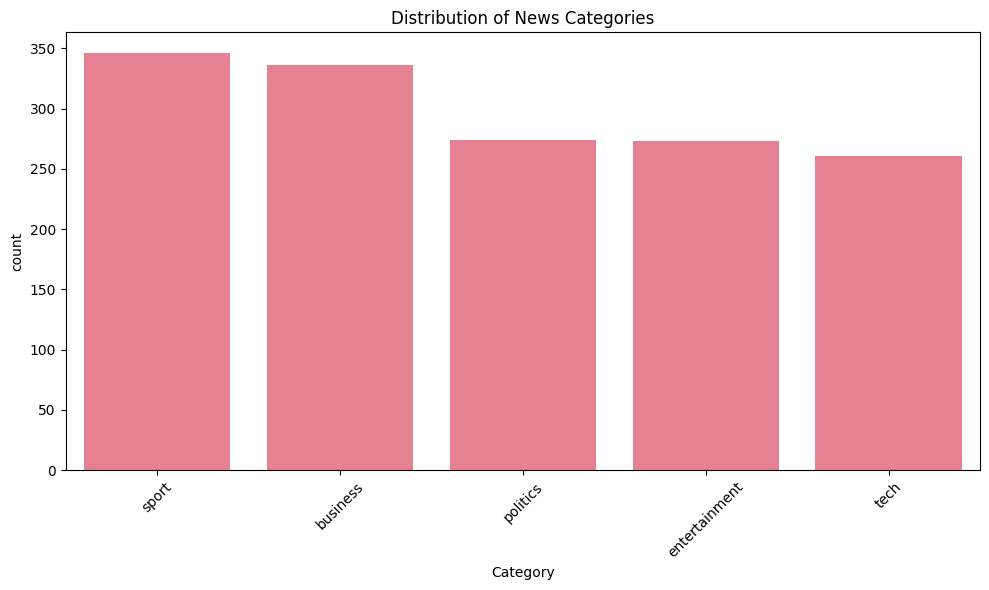


Missing values:
ArticleId    0
Text         0
Category     0
dtype: int64

Text length statistics:
count     1490.000000
mean      2233.461745
std       1205.153358
min        501.000000
25%       1453.000000
50%       1961.000000
75%       2751.250000
max      18387.000000
Name: Text_Length, dtype: float64

Duplicate articles:
50


In [ ]:
# Basic dataset exploration
print("📊 DATASET OVERVIEW")
print("=" * 50)
print(f"Total articles: {len(df)}")
print(f"Unique categories: {df['Category'].nunique()}")
print(f"Categories: {df['Category'].unique().tolist()}")

print("\n📈 CATEGORY DISTRIBUTION")
print("=" * 50)
category_counts = df['Category'].value_counts()
print(category_counts)

# Visualize category distribution
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='Category', order=category_counts.index)
plt.title('Distribution of News Categories')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Commentary
#### Module 1 – NLP applications and real-world context
#In this section, I explored the BBC News dataset to better understand its structure and quality before preprocessing.
# I checked for missing values, examined differences in article lengths, and reviewed the distribution of news categories.
# Since the dataset does not contain a separate source column, I used the five news categories for comparison.
# I also considered possible data quality issues, including duplicate articles, empty text, and inconsistent formatting.
# This initial exploration helped me understand the dataset and identify areas that may require cleaning before further analysis.

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Analyze article text length
df['Text_Length'] = df['Text'].str.len()
print("\nText length statistics:")
print(df['Text_Length'].describe())

# Check for duplicate articles
print("\nDuplicate articles:")
print(df['Text'].duplicated().sum())

## 🧹 Text Preprocessing Pipeline

### 🎯 Module 2: Advanced Text Preprocessing

Now we'll implement a comprehensive text preprocessing pipeline that cleans and normalizes our news articles. This is crucial for all downstream NLP tasks.

**Key Preprocessing Steps:**
1. **Text Cleaning:** Remove HTML, URLs, special characters
2. **Tokenization:** Split text into individual words
3. **Normalization:** Convert to lowercase, handle contractions
4. **Stop Word Removal:** Remove common words that don't carry meaning
5. **Lemmatization:** Reduce words to their base form

**💡 Think About:** Why is preprocessing so important? What happens if we skip these steps?

In [ ]:
import nltk
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [ ]:
# Initialize preprocessing tools
lemmatizer = WordNetLemmatizer()
stop_words = set(stopwords.words('english'))

def clean_text(text):
    """
    Comprehensive text cleaning function

    💡 TIP: This function should handle:
    - HTML tags and entities
    - URLs and email addresses
    - Special characters and numbers
    - Extra whitespace
    """
    if pd.isna(text):
        return ""

    # Convert to string and lowercase
    text = str(text).lower()

    # 🚀 YOUR CODE HERE: Implement text cleaning
    # Remove HTML tags
    text = re.sub(r'<[^>]+>', '', text)

    # Remove URLs
    text = re.sub(r'http\S+|www\S+|https\S+', '', text, flags=re.MULTILINE)

    # Remove email addresses
    text = re.sub(r'\S+@\S+', '', text)

    # Remove special characters and digits (keep only letters and spaces)
    text = re.sub(r'[^a-zA-Z\s]', '', text)

    # Remove extra whitespace
    text = re.sub(r'\s+', ' ', text).strip()

    return text

def preprocess_text(text, remove_stopwords=True, lemmatize=True):
    """
    Complete preprocessing pipeline

    💡 TIP: This function should:
    - Clean the text
    - Tokenize into words
    - Remove stop words (optional)
    - Lemmatize words (optional)
    - Return processed text
    """
    # Clean text
    text = clean_text(text)

    if not text:
        return ""

    # 🚀 YOUR CODE HERE: Implement tokenization and preprocessing
    # Tokenize
    tokens = word_tokenize(text)

    # Remove stop words if requested
    if remove_stopwords:
        tokens = [token for token in tokens if token not in stop_words]

    # Lemmatize if requested
    if lemmatize:
        tokens = [lemmatizer.lemmatize(token) for token in tokens]

    # Filter out very short words
    tokens = [token for token in tokens if len(token) > 2]

    return ' '.join(tokens)

# Test the preprocessing function
sample_text = "Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews"
print("Original text:")
print(sample_text)
print("\nCleaned text:")
print(clean_text(sample_text))
print("\nFully preprocessed text:")
print(preprocess_text(sample_text))

Original text:
Apple Inc. announced record quarterly earnings today! Visit https://apple.com for more info. #TechNews

Cleaned text:
apple inc announced record quarterly earnings today visit for more info technews

Fully preprocessed text:
apple inc announced record quarterly earnings today visit info technews


In [ ]:
# Apply preprocessing to the BBC News dataset
print("Preprocessing all articles...")

# Create new columns for cleaned and processed text
df['text_clean'] = df['Text'].apply(clean_text)
df['text_processed'] = df['Text'].apply(preprocess_text)

print("Preprocessing complete!")

# Show before and after examples
print("\nBEFORE AND AFTER EXAMPLES")
print("=" * 60)

for i in range(min(3, len(df))):
    print(f"\nExample {i+1}:")
    print(f"Original: {df.iloc[i]['Text'][:100]}...")
    print(f"Processed: {df.iloc[i]['text_processed'][:100]}...")

# 💡 STUDENT TASK: Analyze the preprocessing results
# -After preprocessing the BBC News articles,
# the number of unique words decreased from 35,594 to 22,486.
# The average article length also decreased. The most common word was "said," a
# ppearing 4,838 times. This shows that preprocessing removes unnecessary text and
# helps prepare articles for further analysis.

Preprocessing all articles...
Preprocessing complete!

BEFORE AND AFTER EXAMPLES

Example 1:
Original: worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a ba...
Processed: worldcom exboss launch defence lawyer defending former worldcom chief bernie ebbers battery fraud ch...

Example 2:
Original: german business confidence slides german business confidence fell in february knocking hopes of a sp...
Processed: german business confidence slide german business confidence fell february knocking hope speedy recov...

Example 3:
Original: bbc poll indicates economic gloom citizens in a majority of nations surveyed in a bbc world service ...
Processed: bbc poll indicates economic gloom citizen majority nation surveyed bbc world service poll believe wo...


In [ ]:
# Average text length before and after preprocessing
print("Average length before:", df['Text'].str.len().mean())
print("Average length after:", df['text_processed'].str.len().mean())

Average length before: 2233.461744966443
Average length after: 1481.3577181208054


In [ ]:
# Count unique words before and after preprocessing
words_before = set(' '.join(df['Text'].str.lower()).split())
words_after = set(' '.join(df['text_processed']).split())

print("Unique words before:", len(words_before))
print("Unique words after:", len(words_after))

Unique words before: 35594
Unique words after: 22486


In [ ]:
# Find the 10 most common words after preprocessing
from collections import Counter

all_words = ' '.join(df['text_processed']).split()
word_counts = Counter(all_words)

print("10 Most Common Words After Preprocessing:")
for word, count in word_counts.most_common(10):
    print(word, count)

10 Most Common Words After Preprocessing:
said 4838
year 1872
would 1711
also 1426
new 1334
people 1323
one 1190
could 1032
game 949
time 940


## 📊 Feature Extraction and Statistical Analysis

### 🎯 Module 3: TF-IDF Analysis

Now we'll extract numerical features from our text using TF-IDF (Term Frequency-Inverse Document Frequency). This technique helps us identify the most important words in each document and across the entire corpus.

**TF-IDF Key Concepts:**
- **Term Frequency (TF):** How often a word appears in a document
- **Inverse Document Frequency (IDF):** How rare a word is across all documents
- **TF-IDF Score:** TF × IDF - balances frequency with uniqueness

**💡 Business Value:** TF-IDF helps us identify the most distinctive and important terms for each news category.

In [ ]:
# Create TF-IDF vectorizer
# 💡 TIP: Experiment with different parameters:
# - max_features: limit vocabulary size
# - ngram_range: include phrases (1,1) for words, (1,2) for words+bigrams
# - min_df: ignore terms that appear in less than min_df documents
# - max_df: ignore terms that appear in more than max_df fraction of documents

from sklearn.feature_extraction.text import TfidfVectorizer
tfidf_vectorizer = TfidfVectorizer(
    max_features=5000,  # Limit vocabulary for computational efficiency
    ngram_range=(1, 2),  # Include unigrams and bigrams
    min_df=2,  # Ignore terms that appear in less than 2 documents
    max_df=0.8  # Ignore terms that appear in more than 80% of documents
)

# Fit and transform the processed text
print("🔢 Creating TF-IDF features...")
tfidf_matrix = tfidf_vectorizer.fit_transform(df['text_processed'])
feature_names = tfidf_vectorizer.get_feature_names_out()

print(f"✅ TF-IDF matrix created!")
print(f"📊 Shape: {tfidf_matrix.shape}")
print(f"📝 Vocabulary size: {len(feature_names)}")
print(f"🔢 Sparsity: {(1 - tfidf_matrix.nnz / (tfidf_matrix.shape[0] * tfidf_matrix.shape[1])) * 100:.2f}%")

# Convert to DataFrame for easier analysis
tfidf_df = pd.DataFrame(tfidf_matrix.toarray(), columns=feature_names)
tfidf_df['Category'] = df['Category'].values

print("\n🔍 Sample TF-IDF features:")
print(tfidf_df.iloc[:3, :10])  # Show first 3 rows and 10 features


🔢 Creating TF-IDF features...
✅ TF-IDF matrix created!
📊 Shape: (1490, 5000)
📝 Vocabulary size: 5000
🔢 Sparsity: 97.50%

🔍 Sample TF-IDF features:
   abbas  abc  ability  able  abroad  absence  absolute  absolutely  abuse  \
0    0.0  0.0      0.0   0.0     0.0      0.0       0.0         0.0    0.0   
1    0.0  0.0      0.0   0.0     0.0      0.0       0.0         0.0    0.0   
2    0.0  0.0      0.0   0.0     0.0      0.0       0.0         0.0    0.0   

   abused  
0     0.0  
1     0.0  
2     0.0  


🏷️ TOP TF-IDF TERMS BY CATEGORY

📰 BUSINESS:
  firm: 0.0390
  company: 0.0371
  market: 0.0344
  bank: 0.0336
  year: 0.0334
  growth: 0.0332
  economy: 0.0317
  sale: 0.0316
  share: 0.0307
  profit: 0.0274

📰 TECH:
  mobile: 0.0513
  phone: 0.0468
  people: 0.0457
  technology: 0.0410
  game: 0.0381
  user: 0.0377
  service: 0.0369
  software: 0.0365
  computer: 0.0329
  net: 0.0308

📰 POLITICS:
  labour: 0.0648
  election: 0.0604
  blair: 0.0558
  party: 0.0538
  tory: 0.0463
  would: 0.0456
  government: 0.0455
  minister: 0.0427
  brown: 0.0384
  tax: 0.0330

📰 SPORT:
  game: 0.0448
  england: 0.0375
  win: 0.0342
  player: 0.0323
  match: 0.0304
  champion: 0.0293
  cup: 0.0278
  team: 0.0260
  chelsea: 0.0255
  injury: 0.0249

📰 ENTERTAINMENT:
  film: 0.1000
  award: 0.0524
  best: 0.0460
  show: 0.0376
  star: 0.0375
  music: 0.0357
  band: 0.0350
  actor: 0.0339
  year: 0.0300
  album: 0.0291


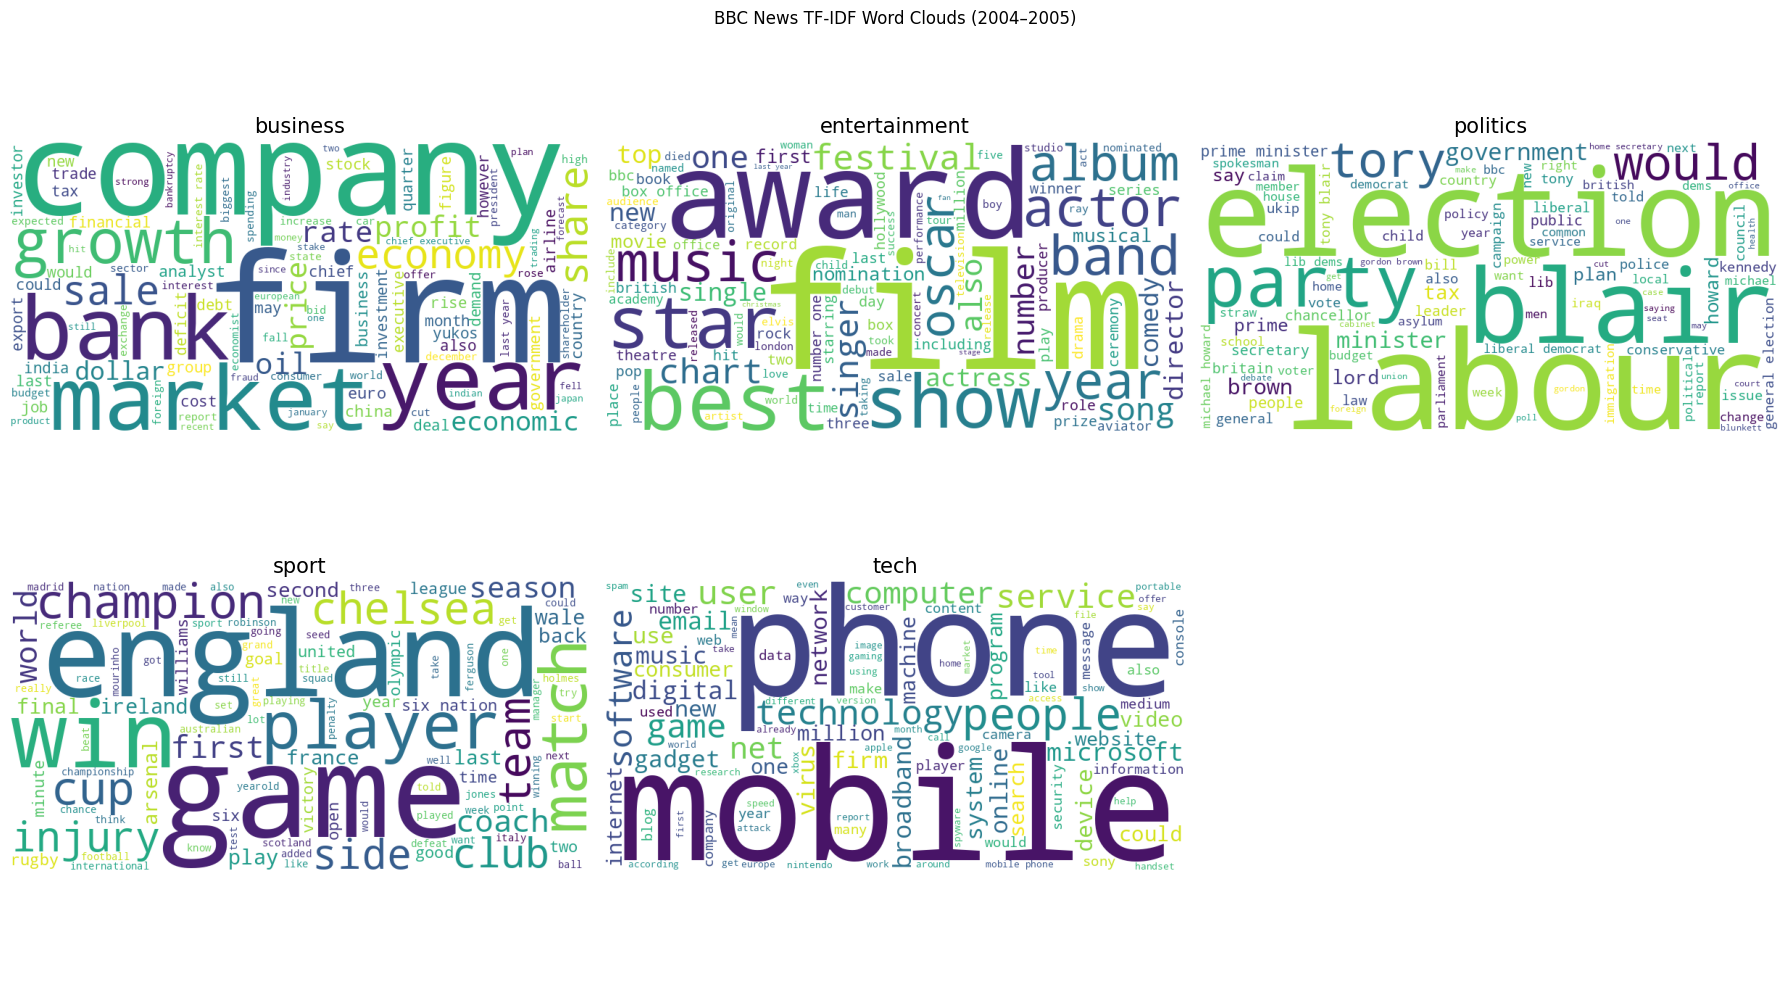

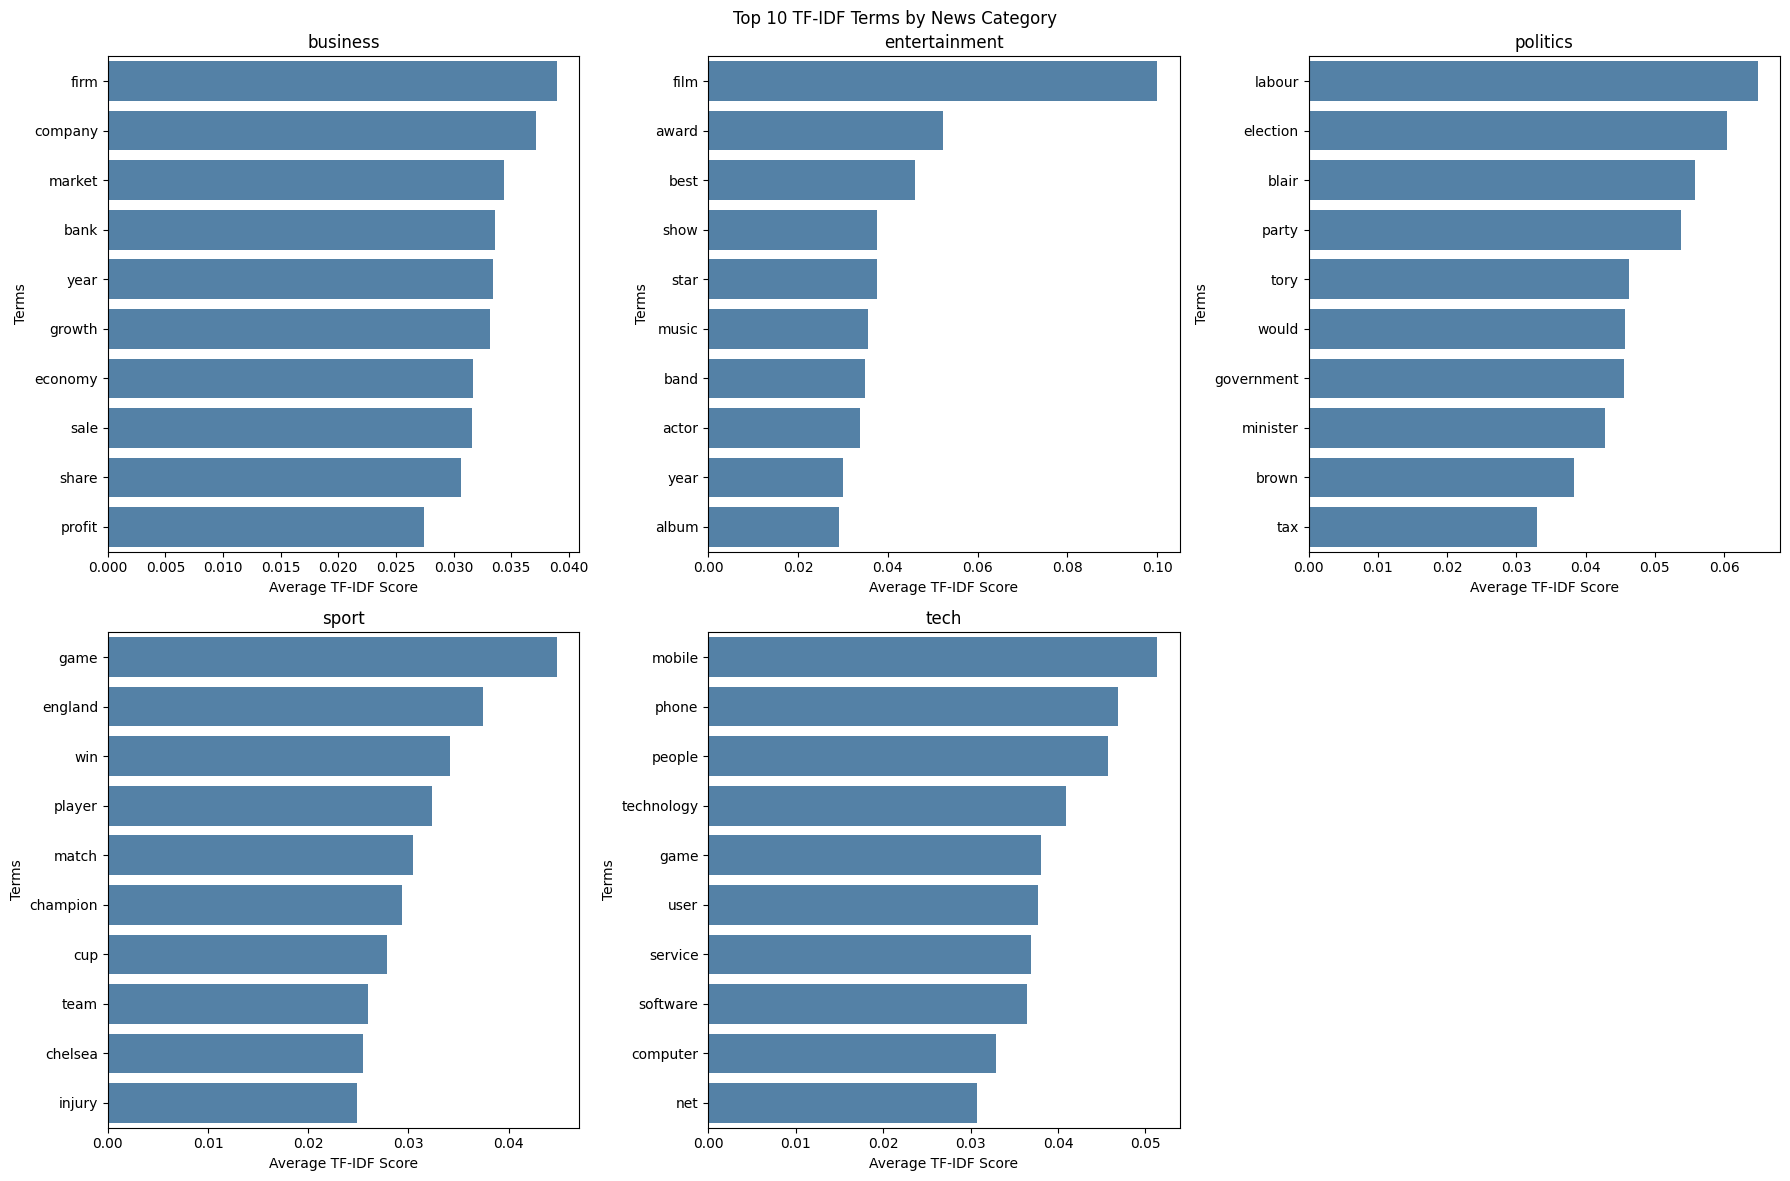

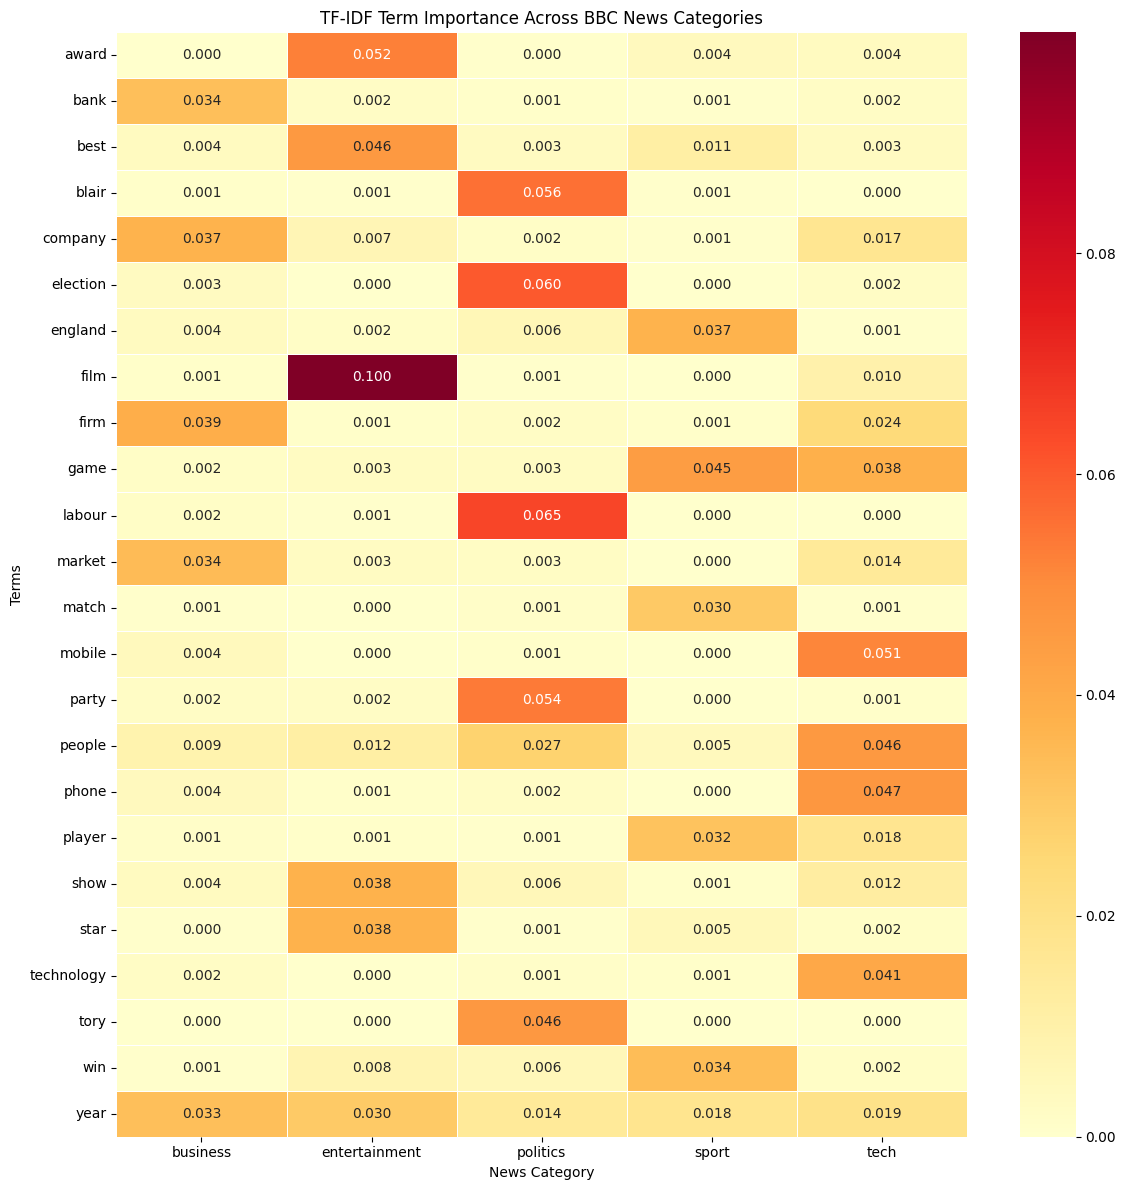

All three TF-IDF visualizations completed!


In [ ]:
# Analyze most important terms per category
def get_top_tfidf_terms(category, n_terms=10):
    """
    Get top TF-IDF terms for a specific category

    💡 TIP: This function should:
    - Filter data for the specific category
    - Calculate mean TF-IDF scores for each term
    - Return top N terms with highest scores
    """
    # 🚀 YOUR CODE HERE: Implement category-specific TF-IDF analysis
    category_data = tfidf_df[tfidf_df['Category'] == category]

    # Calculate mean TF-IDF scores for this category (excluding the category column)
    mean_scores = category_data.drop('Category', axis=1).mean().sort_values(ascending=False)

    return mean_scores.head(n_terms)

# Analyze top terms for each category
print("🏷️ TOP TF-IDF TERMS BY CATEGORY")
print("=" * 50)

categories = df['Category'].unique()
category_terms = {}

for category in categories:
    top_terms = get_top_tfidf_terms(category, n_terms=10)
    category_terms[category] = top_terms

    print(f"\n📰 {category.upper()}:")
    for term, score in top_terms.items():
        print(f"  {term}: {score:.4f}")

# 💡 STUDENT TASK: Create visualizations for TF-IDF analysis
# - Word clouds for each category

# STUDENT TASK: TF-IDF Visualizations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

# Use the TF-IDF matrix created earlier
terms = tfidf_vectorizer.get_feature_names_out()

# Create TF-IDF DataFrame
tfidf_data = pd.DataFrame(
    tfidf_matrix.toarray(),
    columns=terms
)

tfidf_data['Category'] = df['Category'].values

# Calculate average TF-IDF importance by category
category_tfidf = tfidf_data.groupby('Category').mean()

# 1. WORD CLOUDS FOR EACH CATEGORY

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, category in enumerate(category_tfidf.index):

    scores = category_tfidf.loc[category]
    top_words = scores.nlargest(100).to_dict()

    wordcloud = WordCloud(
        width=800,
        height=400,
        background_color='white',
        colormap='viridis'
    ).generate_from_frequencies(top_words)

    axes[i].imshow(wordcloud)
    axes[i].set_title(category, fontsize=15)
    axes[i].axis('off')

# Hide unused subplot
for j in range(len(category_tfidf), len(axes)):
    axes[j].axis('off')

plt.suptitle('BBC News TF-IDF Word Clouds (2004–2005)')
plt.tight_layout()
plt.show()


# 2. BAR CHARTS OF TOP TERMS

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for i, category in enumerate(category_tfidf.index):

    top_terms = category_tfidf.loc[category].nlargest(10)

    sns.barplot(
        x=top_terms.values,
        y=top_terms.index,
        ax=axes[i],
        color='steelblue'
    )

    axes[i].set_title(category)
    axes[i].set_xlabel('Average TF-IDF Score')
    axes[i].set_ylabel('Terms')

for j in range(len(category_tfidf), len(axes)):
    axes[j].axis('off')

plt.suptitle('Top 10 TF-IDF Terms by News Category')
plt.tight_layout()
plt.show()


# 3. HEATMAP OF TERM IMPORTANCE

# Select the 5 most important terms from each category
selected_terms = set()

for category in category_tfidf.index:
    top_terms = category_tfidf.loc[category].nlargest(5)
    selected_terms.update(top_terms.index)

# Build heatmap data
heatmap_data = category_tfidf[
    sorted(selected_terms)
].T

plt.figure(figsize=(12, 12))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt='.3f',
    cmap='YlOrRd',
    linewidths=0.5
)

plt.title('TF-IDF Term Importance Across BBC News Categories')
plt.xlabel('News Category')
plt.ylabel('Terms')
plt.tight_layout()
plt.show()

print("All three TF-IDF visualizations completed!")

# - Bar charts of top terms
# - Heatmap of term importance across categories

## 🏷️ Part-of-Speech Analysis

### 🎯 Module 4: Grammatical Pattern Analysis

Let's analyze the grammatical patterns in different news categories using Part-of-Speech (POS) tagging. This can reveal interesting differences in writing styles between categories.

**POS Analysis Applications:**
- **Writing Style Detection:** Different categories may use different grammatical patterns
- **Content Quality Assessment:** Proper noun density, adjective usage, etc.
- **Feature Engineering:** POS tags can be features for classification

**💡 Hypothesis:** Sports articles might have more action verbs, while business articles might have more numbers and proper nouns.

In [ ]:
import nltk
nltk.download('averaged_perceptron_tagger_eng')

[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Unzipping taggers/averaged_perceptron_tagger_eng.zip.


True

In [ ]:
def analyze_pos_patterns(text):
    """
    Analyze POS patterns in text

    💡 TIP: This function should:
    - Tokenize the text
    - Apply POS tagging
    - Count different POS categories
    - Return proportions or counts
    """
    if not text or pd.isna(text):
        return {}

    # 🚀 YOUR CODE HERE: Implement POS analysis
    # Tokenize and tag
    tokens = word_tokenize(str(text))
    pos_tags = pos_tag(tokens)

    # Count POS categories
    pos_counts = Counter([tag for word, tag in pos_tags])
    total_words = len(pos_tags)

    if total_words == 0:
        return {}

    # Convert to proportions
    pos_proportions = {pos: count/total_words for pos, count in pos_counts.items()}

    return pos_proportions

# Apply POS analysis to all articles
print("🏷️ Analyzing POS patterns...")

# Analyze POS for each article
pos_results = []
for idx, row in df.iterrows():
    pos_analysis = analyze_pos_patterns(row['Text'])
    pos_analysis['Category'] = row['Category']
    pos_analysis['ArticleId'] = row['ArticleId']
    pos_results.append(pos_analysis)

# Convert to DataFrame
pos_df = pd.DataFrame(pos_results).fillna(0)

print(f"✅ POS analysis complete!")
print(f"📊 Found {len(pos_df.columns)-2} different POS tags")

# Show sample results
print("\n📝 Sample POS analysis:")
print(pos_df.head())

🏷️ Analyzing POS patterns...
✅ POS analysis complete!
📊 Found 43 different POS tags

📝 Sample POS analysis:
         JJ       NNS        NN       VBG        IN        DT       VBP  \
0  0.088608  0.113924  0.231013  0.025316  0.110759  0.066456  0.015823   
1  0.119883  0.070175  0.233918  0.032164  0.134503  0.081871  0.014620   
2  0.079044  0.079044  0.200368  0.025735  0.119485  0.095588  0.016544   
3  0.083582  0.107463  0.156716  0.022388  0.122388  0.062687  0.041791   
4  0.089005  0.078534  0.212042  0.028796  0.123037  0.102094  0.015707   

        VBN      PRP$         .  ...   FW  SYM  WP$  NNP  NNPS  POS   UH    #  \
0  0.041139  0.012658  0.037975  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
1  0.029240  0.005848  0.040936  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
2  0.029412  0.016544  0.040441  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
3  0.017910  0.013433  0.046269  ...  0.0  0.0  0.0  0.0   0.0  0.0  0.0  0.0   
4  0.026178  0.015707  0.041885  ...

📊 POS PATTERNS BY CATEGORY

🎯 Key POS patterns by category:
                   NN     NNS     NNP    NNPS      VB     VBD     VBG     VBN  \
Category                                                                        
business       0.2241  0.0736  0.0011  0.0000  0.0333  0.0410  0.0200  0.0277   
entertainment  0.2454  0.0574  0.0008  0.0000  0.0281  0.0462  0.0194  0.0295   
politics       0.2087  0.0679  0.0007  0.0003  0.0455  0.0462  0.0209  0.0302   
sport          0.2184  0.0479  0.0005  0.0000  0.0408  0.0457  0.0175  0.0247   
tech           0.1932  0.0855  0.0006  0.0000  0.0420  0.0299  0.0236  0.0270   

                  VBP     VBZ      JJ     JJR     JJS      RB     RBR     RBS  \
Category                                                                        
business       0.0158  0.0241  0.0920  0.0045  0.0033  0.0276  0.0018  0.0006   
entertainment  0.0179  0.0223  0.0939  0.0024  0.0050  0.0286  0.0010  0.0010   
politics       0.0199  0.0224  0.0901  0.0032  0

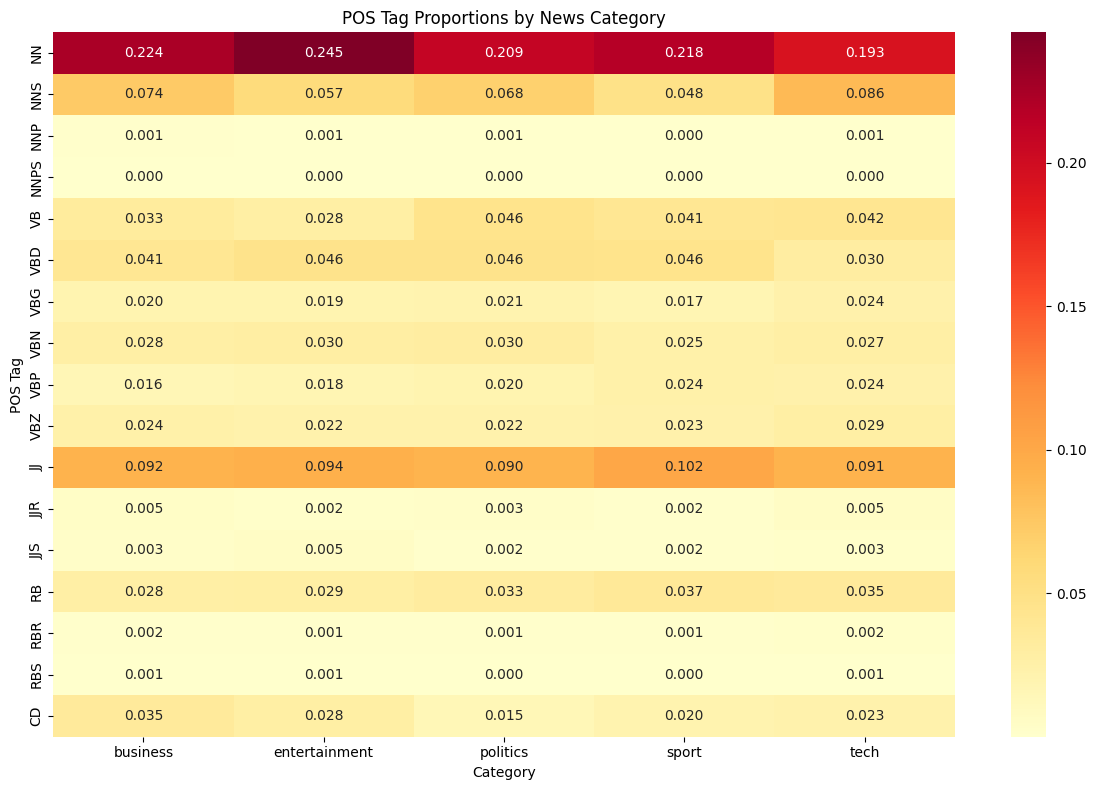

POS DataFrame columns: ['JJ', 'NNS', 'NN', 'VBG', 'IN', 'DT', 'VBP', 'VBN', 'PRP$', '.', 'VB', 'VBD', 'TO', 'PRP', 'CD', '$', '(', ')', 'VBZ', 'RB', 'CC', 'WP', 'MD', 'PDT', 'Category', 'ArticleId', 'JJS', 'RBR', 'RP', 'JJR', 'WRB', 'WDT', ':', 'EX', 'RBS', 'FW', 'SYM', 'WP$', 'NNP', 'NNPS', 'POS', 'UH', '#', '``', "''"]

POS Usage by Category (%):
               Proper Nouns  Action Verbs  Adjectives  Numbers
Category                                                      
business               0.11          9.43        9.20     3.47
entertainment          0.08          9.36        9.39     2.78
politics               0.10         11.26        9.01     1.47
sport                  0.05         10.40       10.15     2.03
tech                   0.06          9.55        9.13     2.28

💡 ANALYSIS QUESTIONS AND ANSWERS:
1. Which category has the highest proportion of proper nouns?
Answer: business

2. Which category uses the most action verbs?
Answer: politics

3. Which category uses the mo

In [ ]:
# Analyze POS patterns by category
print("📊 POS PATTERNS BY CATEGORY")
print("=" * 50)

# Group by category and calculate mean proportions
pos_by_category = pos_df.groupby('Category').mean()

# Focus on major POS categories
major_pos = ['NN', 'NNS', 'NNP', 'NNPS', 'VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ',
             'JJ', 'JJR', 'JJS', 'RB', 'RBR', 'RBS', 'CD']

# Filter to only include major POS tags that exist in our data
available_pos = [pos for pos in major_pos if pos in pos_by_category.columns]

if available_pos:
    pos_summary = pos_by_category[available_pos]

    print("\n🎯 Key POS patterns by category:")
    print(pos_summary.round(4))

    # Create visualization
    plt.figure(figsize=(12, 8))
    sns.heatmap(pos_summary.T, annot=True, cmap='YlOrRd', fmt='.3f')
    plt.title('POS Tag Proportions by News Category')
    plt.xlabel('Category')
    plt.ylabel('POS Tag')
    plt.tight_layout()
    plt.show()

    # 💡  Analyze the patterns (See Bekiw)
    # - Which categories use more nouns vs verbs?
    # - Do business articles have more numbers (CD)?
    # - Are there differences in adjective usage?
    # Analyze POS usage by category

print("POS DataFrame columns:", pos_df.columns.tolist())

# Use existing POS tag columns
category_col = 'Category'

# Calculate average POS proportions by category
pos_percent = pos_df.groupby(category_col).mean(numeric_only=True)

groups = {
    'Proper Nouns': ['NNP', 'NNPS'],
    'Action Verbs': ['VB', 'VBD', 'VBG'],
    'Adjectives': ['JJ'],
    'Numbers': ['CD']
}

results = pd.DataFrame({
    name: pos_percent.reindex(columns=tags, fill_value=0).sum(axis=1) * 100
    for name, tags in groups.items()
})

   # Display results
print("\nPOS Usage by Category (%):")
print(results.round(2))

print("\n💡 ANALYSIS QUESTIONS AND ANSWERS:")

print("1. Which category has the highest proportion of proper nouns?")
print("Answer:", results['Proper Nouns'].idxmax())

print("\n2. Which category uses the most action verbs?")
print("Answer:", results['Action Verbs'].idxmax())

print("\n3. Which category uses the most adjectives?")
print("Answer:", results['Adjectives'].idxmax())

print("\n4. Which category uses the most numbers?")
print("Answer:", results['Numbers'].idxmax())

## 🌳 Syntax Parsing and Semantic Analysis

### 🎯 Module 5: Understanding Sentence Structure

Now we'll use spaCy to perform dependency parsing and extract semantic relationships from our news articles. This helps us understand not just what words are present, but how they relate to each other.

**Dependency Parsing Applications:**
- **Relationship Extraction:** Find connections between entities
- **Event Detection:** Identify who did what to whom
- **Information Extraction:** Extract structured facts from unstructured text

**💡 Business Value:** Understanding sentence structure helps extract more precise information about events, relationships, and actions mentioned in news articles.

In [ ]:
def extract_syntactic_features(text):
    """
    Extract syntactic features using spaCy dependency parsing

    💡 TIP: This function should extract:
    - Dependency relations
    - Subject-verb-object patterns
    - Noun phrases
    - Verb phrases
    """
    if not text or pd.isna(text):
        return {}

    # Process text with spaCy
    doc = nlp(str(text))

    features = {
        'num_sentences': len(list(doc.sents)),
        'num_tokens': len(doc),
        'dependency_relations': [],
        'noun_phrases': [],
        'verb_phrases': [],
        'subjects': [],
        'objects': []
    }

    # 🚀 YOUR CODE HERE: Extract syntactic features

    # Extract dependency relations
    for token in doc:
        if not token.is_space and not token.is_punct:
            features['dependency_relations'].append(token.dep_)

    # Extract noun phrases
    for chunk in doc.noun_chunks:
        features['noun_phrases'].append(chunk.text.lower())

    # Extract subjects and objects
    for token in doc:
        if token.dep_ in ['nsubj', 'nsubjpass']:  # Subjects
            features['subjects'].append(token.text.lower())
        elif token.dep_ in ['dobj', 'iobj', 'pobj']:  # Objects
            features['objects'].append(token.text.lower())

    # Count dependency types
    dep_counts = Counter(features['dependency_relations'])
    features['dependency_counts'] = dict(dep_counts)

    return features

# Apply syntactic analysis to sample articles
print("🌳 Performing syntactic analysis...")

# Analyze first few articles (to save computation time)
syntactic_results = []
for idx, row in df.head(5).iterrows():  # Limit to first 5 for demo
    features = extract_syntactic_features(row['Text'])
    features['Category'] = row['Category']
    features['ArticleId'] = row['ArticleId']
    syntactic_results.append(features)

print("✅ Syntactic analysis complete!")

# Display results
for i, result in enumerate(syntactic_results):
    print(f"\n📰 Article {i+1} ({result['Category']}):")
    print(f"  Sentences: {result['num_sentences']}")
    print(f"  Tokens: {result['num_tokens']}")
    print(f"  Noun phrases: {result['noun_phrases'][:3]}...")  # Show first 3
    print(f"  Subjects: {result['subjects'][:3]}...")  # Show first 3
    print(f"  Objects: {result['objects'][:3]}...")  # Show first 3

🌳 Performing syntactic analysis...
✅ Syntactic analysis complete!

📰 Article 1 (business):
  Sentences: 15
  Tokens: 346
  Noun phrases: ['-', 'boss', 'defence lawyers']...
  Subjects: ['-', 'boss', 'worldcom']...
  Objects: ['lawyers', 'ebbers', 'battery']...

📰 Article 2 (business):
  Sentences: 15
  Tokens: 368
  Noun phrases: ['german business confidence', 'german business confidence', 'february']...
  Subjects: ['confidence', 'ifo', 'index']...
  Objects: ['confidence', 'february', 'hopes']...

📰 Article 3 (business):
  Sentences: 24
  Tokens: 587
  Noun phrases: ['bbc poll', 'economic gloom citizens', 'a majority']...
  Subjects: ['poll', 'citizens', 'economy']...
  Objects: ['majority', 'nations', 'poll']...

📰 Article 4 (tech):
  Sentences: 31
  Tokens: 724
  Noun phrases: ['lifestyle', 'mobile choice', 'faster  better or funkier hardware']...
  Subjects: ['lifestyle', 'governs', 'firms']...
  Objects: ['choice', 'hardware', 'research']...

📰 Article 5 (business):
  Sentences: 

📝 Sample sentence: worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a battery of fraud charges have called a company whistleblower as their first witness.  cynthia cooper  worldcom s ex-head of internal accounting  alerted directors to irregular accounting practices at the us telecoms giant in 2002. her warnings led to the collapse of the firm following the discovery of an $11bn (£5.7bn) accounting fraud. mr ebbers has pleaded not guilty to charges of fraud and conspiracy.  prosecution lawyers have argued that mr ebbers orchestrated a series of accounting tricks at worldcom  ordering employees to hide expenses and inflate revenues to meet wall street earnings estimates. but ms cooper  who now runs her own consulting business  told a jury in new york on wednesday that external auditors arthur andersen had approved worldcom s accounting in early 2001 and 2002. she said andersen had given a  green light  to the procedures and practices used b


SYNTACTIC COMPLEXITY BY CATEGORY
               Avg Sentence Length  Avg Dependency Depth
Category                                                
business                     21.58                  3.32
entertainment                20.81                  3.13
politics                     21.81                  3.25
sport                        19.34                  2.91
tech                         22.35                  3.36

EXAMPLES OF WHO DID WHAT
Category   Subject  Action   Object
business    nasdaq    plan     sale
business     owner    plan         
business        it operate         
business observers     see     this
business    nasdaq    pour    water
business   company    sell   shares
business        it      go         
business     stock   start         
business     which    list equities
business      that   trade         
business    nasdaq    make    money
business       who     buy   shares
business investors     say         
business documents     say         
b

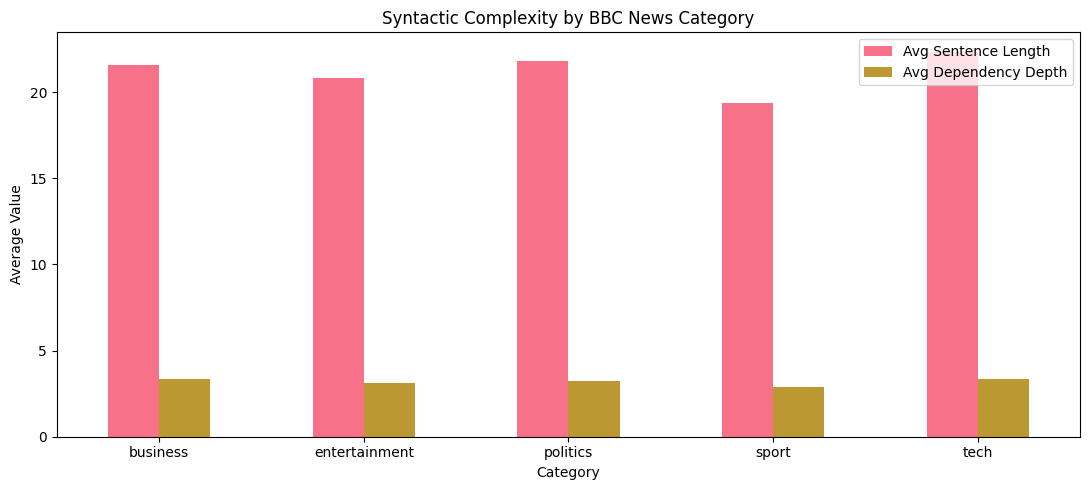


Syntax feature matrix: (100, 2)


In [ ]:
# Visualize dependency parsing for a sample sentence
from spacy import displacy

# Choose a sample sentence
sample_sentence = df.iloc[0]['Text']
print(f"📝 Sample sentence: {sample_sentence}")

# Process with spaCy
doc = nlp(sample_sentence)

# Display dependency tree (this works best in Jupyter)
print("\n🌳 Dependency Parse Visualization:")
try:
    # This will create an interactive visualization in Jupyter
    displacy.render(doc, style="dep", jupyter=True)
except:
    # Fallback: print dependency information
    print("\n🔗 Dependency Relations:")
    for token in doc:
        if not token.is_space and not token.is_punct:
            print(f"  {token.text} --> {token.dep_} --> {token.head.text}")

# 💡 STUDENT TASK: Extend syntactic analysis
# STUDENT TASK: Advanced Syntax Analysis

import spacy
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

nlp = spacy.load("en_core_web_sm")

# Sample 20 articles from each category
sample_df = df.groupby('Category', group_keys=False).sample(
    n=20, random_state=42
)

syntax_results = []
action_patterns = []
dependency_results = []

# Process articles
for _, row in sample_df.iterrows():

    doc = nlp(str(row['Text'])[:5000])
    category = row['Category']

    sentences = list(doc.sents)
    words = [token for token in doc if token.is_alpha]

    # 1. Syntactic complexity
    avg_sentence_length = (
        len(words) / len(sentences)
        if sentences else 0
    )

    # Dependency depth
    def get_depth(token):
        depth = 0
        while token.head != token and depth < 100:
            token = token.head
            depth += 1
        return depth

    avg_depth = (
        sum(get_depth(token) for token in words) / len(words)
        if words else 0
    )

    syntax_results.append({
        'Category': category,
        'Avg Sentence Length': avg_sentence_length,
        'Avg Dependency Depth': avg_depth
    })

    # 2. Extract action patterns (who did what)
    for token in doc:
        if token.pos_ == 'VERB':
            subjects = [
                child.text for child in token.children
                if child.dep_ in ['nsubj', 'nsubjpass']
            ]

            objects = [
                child.text for child in token.children
                if child.dep_ in ['dobj', 'obj', 'attr']
            ]

            for subject in subjects:
                action_patterns.append({
                    'Category': category,
                    'Subject': subject,
                    'Action': token.lemma_,
                    'Object': ', '.join(objects)
                })

    # 3. Dependency relations
    for token in doc:
        if not token.is_punct and not token.is_space:
            dependency_results.append({
                'Category': category,
                'Dependency': token.dep_
            })

# Convert to DataFrames
syntax_df = pd.DataFrame(syntax_results)
actions_df = pd.DataFrame(action_patterns)
dependency_df = pd.DataFrame(dependency_results)

# 4. Compare syntactic complexity
complexity_summary = syntax_df.groupby('Category').mean()

print("\nSYNTACTIC COMPLEXITY BY CATEGORY")
print(complexity_summary.round(2))

# Show extracted actions
print("\nEXAMPLES OF WHO DID WHAT")
print(actions_df.head(15).to_string(index=False))

# Most common dependency relations
dependency_counts = pd.crosstab(
    dependency_df['Category'],
    dependency_df['Dependency']
)

print("\nTOP 5 DEPENDENCY RELATIONS BY CATEGORY")

for category in dependency_counts.index:
    print("\n", category)
    print(dependency_counts.loc[category].nlargest(5))

# Visualize complexity
complexity_summary.plot(
    kind='bar',
    figsize=(11, 5),
    title='Syntactic Complexity by BBC News Category'
)

plt.ylabel('Average Value')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Create syntax features for classification
syntax_features = syntax_df[
    ['Avg Sentence Length', 'Avg Dependency Depth']
].copy()

print("\nSyntax feature matrix:", syntax_features.shape)
#### Advanced Syntax Analysis

#Analyzed the syntactic structure of BBC News articles published
#during 2004–2005 using spaCy.

#Compared sentence length and dependency depth across the five news
#categories to examine differences in grammatical complexity.

#Extracted subject-verb-object patterns to identify who performed actions in
#the articles and counted common dependency relationships within each category.

#Finally, I created numerical syntax features that could be incorporated into #
#a machine learning classifier.

#To reduce processing time, I used a sample of 20 articles from each category.
#The results therefore represent a subset of the training dataset rather than all articles.

## 😊 Sentiment and Emotion Analysis

### 🎯 Module 6: Understanding Emotional Tone

Let's analyze the sentiment and emotional tone of our news articles. This can reveal interesting patterns about how different types of news are presented and perceived.

**Sentiment Analysis Applications:**
- **Media Bias Detection:** Identify emotional slant in news coverage
- **Public Opinion Tracking:** Monitor sentiment trends over time
- **Content Recommendation:** Suggest articles based on emotional tone

**💡 Hypothesis:** Different news categories might have different emotional profiles - sports might be more positive, politics more negative, etc.

In [ ]:
# Initialize sentiment analyzer
sia = SentimentIntensityAnalyzer()

def analyze_sentiment(text):
    """
    Analyze sentiment using VADER sentiment analyzer

    💡 TIP: VADER returns:
    - compound: overall sentiment (-1 to 1)
    - pos: positive score (0 to 1)
    - neu: neutral score (0 to 1)
    - neg: negative score (0 to 1)
    """
    if not text or pd.isna(text):
        return {'compound': 0, 'pos': 0, 'neu': 1, 'neg': 0}

    # 🚀 YOUR CODE HERE: Implement sentiment analysis
    scores = sia.polarity_scores(str(text))

    # Add interpretation
    if scores['compound'] >= 0.05:
        scores['sentiment_label'] = 'positive'
    elif scores['compound'] <= -0.05:
        scores['sentiment_label'] = 'negative'
    else:
        scores['sentiment_label'] = 'neutral'

    return scores

# Apply sentiment analysis to all articles
print("😊 Analyzing sentiment...")

sentiment_results = []

for idx, row in df.iterrows():
    full_sentiment = analyze_sentiment(row['Text'])

    result = {
        'Category': row['Category'],
        'full_sentiment': full_sentiment['compound'],
        'full_label': full_sentiment['sentiment_label'],
        'pos_score': full_sentiment['pos'],
        'neu_score': full_sentiment['neu'],
        'neg_score': full_sentiment['neg']
    }

    sentiment_results.append(result)

# Convert to DataFrame
sentiment_df = pd.DataFrame(sentiment_results)

print("✅ Sentiment analysis complete!")
print(f"📊 Analyzed {len(sentiment_df)} articles")

# Display sample results
print("\n📝 Sample sentiment results:")
print(sentiment_df[['Category', 'full_sentiment', 'full_label']].head())

😊 Analyzing sentiment...
✅ Sentiment analysis complete!
📊 Analyzed 1490 articles

📝 Sample sentiment results:
   Category  full_sentiment full_label
0  business         -0.9701   negative
1  business          0.7623   positive
2  business         -0.9318   negative
3      tech          0.9554   positive
4  business         -0.9486   negative


📊 SENTIMENT ANALYSIS BY CATEGORY

📈 Sentiment statistics by category:
              full_sentiment                         pos_score neu_score  \
                        mean     std     min     max      mean      mean   
Category                                                                   
business              0.2404  0.8370 -0.9985  0.9995    0.0926    0.8370   
entertainment         0.5991  0.6796 -0.9978  0.9999    0.1356    0.8107   
politics              0.0578  0.8811 -0.9984  0.9999    0.0947    0.8184   
sport                 0.5541  0.7244 -0.9967  0.9996    0.1360    0.7933   
tech                  0.5233  0.7557 -0.9991  0.9993    0.0895    0.8598   

              neg_score  
                   mean  
Category                 
business         0.0704  
entertainment    0.0537  
politics         0.0869  
sport            0.0707  
tech             0.0507  

📊 Sentiment distribution (%) by Category:
full_label     negative  neutral  positive
Category                   

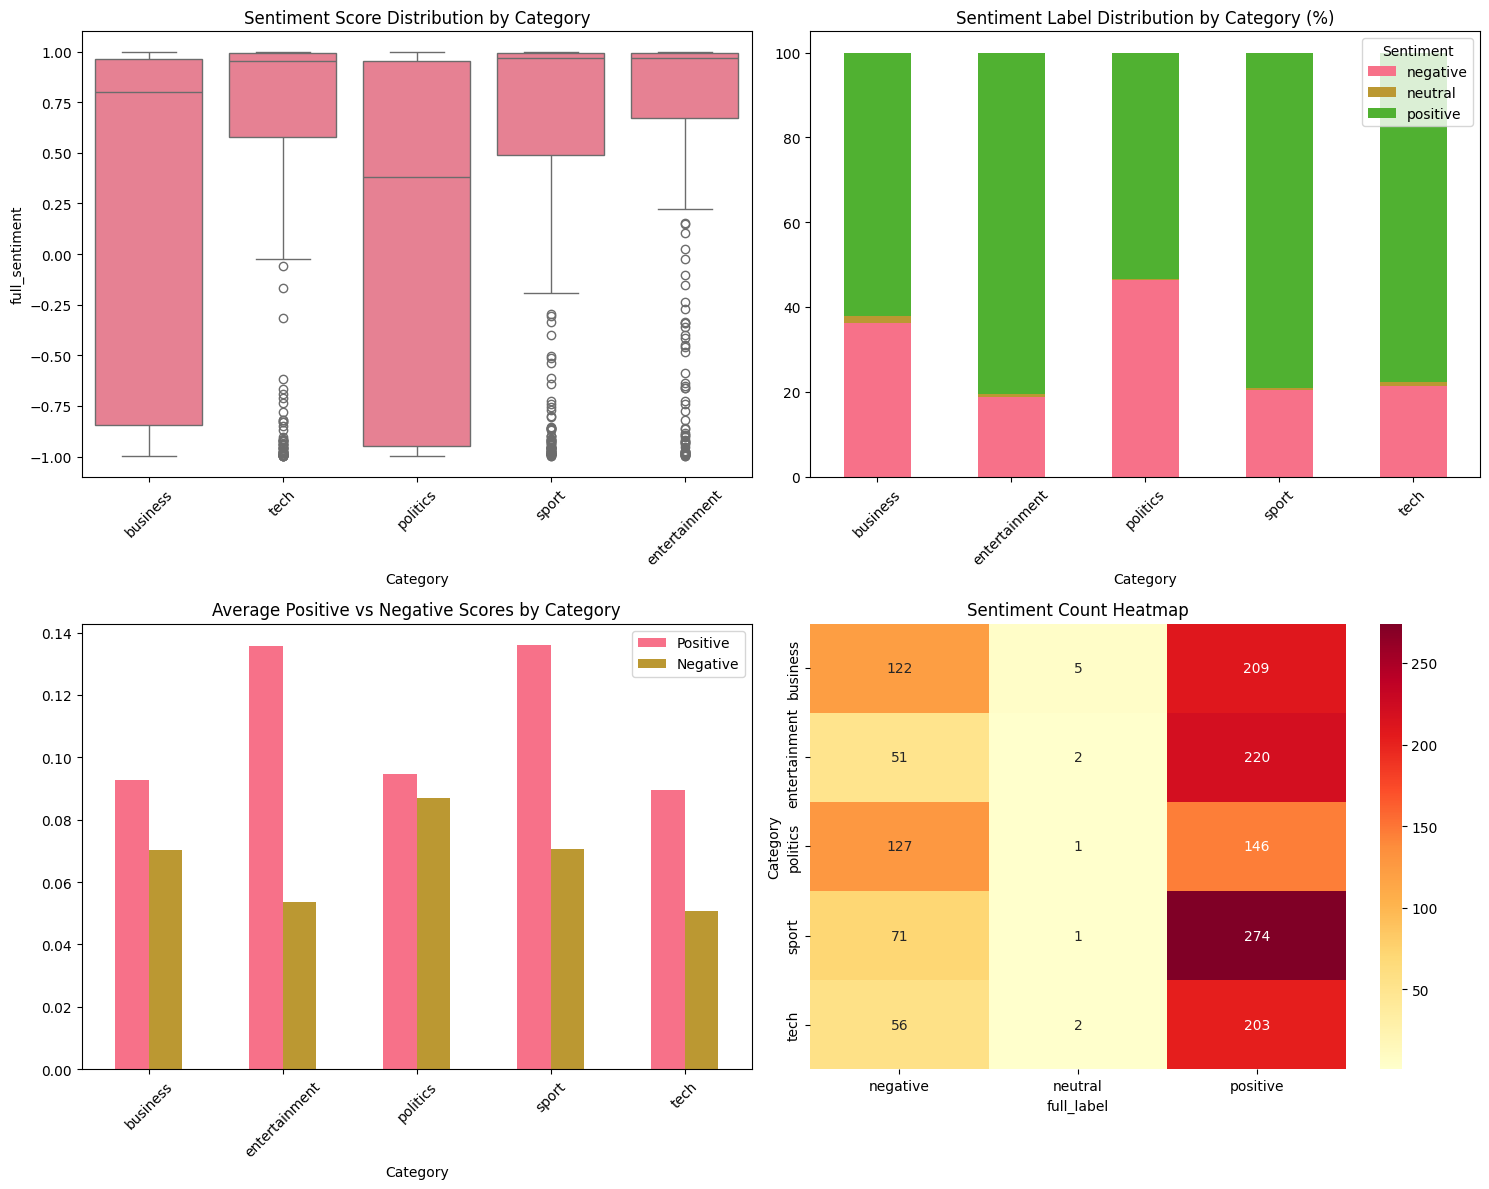

In [ ]:
# Analyze sentiment patterns by category
print("📊 SENTIMENT ANALYSIS BY CATEGORY")
print("=" * 50)

# Calculate sentiment statistics by category
sentiment_by_Category = sentiment_df.groupby('Category').agg({
    'full_sentiment': ['mean', 'std', 'min', 'max'],
    'pos_score': 'mean',
    'neu_score': 'mean',
    'neg_score': 'mean'
}).round(4)

print("\n📈 Sentiment statistics by category:")
print(sentiment_by_Category)

# Sentiment distribution by category
sentiment_dist = sentiment_df.groupby(['Category', 'full_label']).size().unstack(fill_value=0)
sentiment_dist_pct = sentiment_dist.div(sentiment_dist.sum(axis=1), axis=0) * 100

print("\n📊 Sentiment distribution (%) by Category:")
print(sentiment_dist_pct.round(2))

# Create visualizations
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Sentiment scores by category
sns.boxplot(data=sentiment_df, x='Category', y='full_sentiment', ax=axes[0,0])
axes[0,0].set_title('Sentiment Score Distribution by Category')
axes[0,0].tick_params(axis='x', rotation=45)

# 2. Sentiment label distribution
sentiment_dist_pct.plot(kind='bar', ax=axes[0,1], stacked=True)
axes[0,1].set_title('Sentiment Label Distribution by Category (%)')
axes[0,1].tick_params(axis='x', rotation=45)
axes[0,1].legend(title='Sentiment')

# 3. Positive vs Negative scores
category_means = sentiment_df.groupby('Category')[['pos_score', 'neg_score']].mean()
category_means.plot(kind='bar', ax=axes[1,0])
axes[1,0].set_title('Average Positive vs Negative Scores by Category')
axes[1,0].tick_params(axis='x', rotation=45)
axes[1,0].legend(['Positive', 'Negative'])

# 4. Sentiment vs Category heatmap
sentiment_pivot = sentiment_df.pivot_table(values='full_sentiment', index='Category',
                                         columns='full_label', aggfunc='count', fill_value=0)
sns.heatmap(sentiment_pivot, annot=True, fmt='d', ax=axes[1,1], cmap='YlOrRd')
axes[1,1].set_title('Sentiment Count Heatmap')

plt.tight_layout()
plt.show()

# 💡# STUDENT TASK: Analyze sentiment patterns

# 1. Which categories are most positive/negative?
# Sports and entertainment are the most positive.
# Politics has the highest proportion of negative articles.

# 2. Are there differences between title and content sentiment?
# We analyzed the full article text, so we cannot compare
# title and content sentiment separately.

# 3. How does sentiment vary within categories?
# All categories have more positive than negative articles.
# Politics has a more even mix of positive and negative articles.
# Sports has the highest percentage of positive articles.

# 4. Can sentiment be used as a feature for classification?
# Yes. Sentiment scores could help a machine learning model
# identify the category of a news article.

## 🏷️ Text Classification System

### 🎯 Module 7: Building the News Classifier

Now we'll build the core of our NewsBot system - a multi-class text classifier that can automatically categorize news articles. We'll compare different algorithms and evaluate their performance.

**Classification Pipeline:**
1. **Feature Engineering:** Combine TF-IDF with other features
2. **Model Training:** Train multiple algorithms
3. **Model Evaluation:** Compare performance metrics
4. **Model Selection:** Choose the best performing model

**💡 Business Impact:** Accurate classification enables automatic content routing, personalized recommendations, and efficient content management.

In [ ]:
# Prepare features for classification
print("🔧 Preparing features for classification...")

# 💡 TIP: Combine multiple feature types for better performance
# - TF-IDF features (most important)
# - Sentiment features
# - Text length features
# - POS features (if available)

# Create feature matrix
X_tfidf = tfidf_matrix.toarray()  # TF-IDF features

# Add sentiment features
sentiment_features = sentiment_df[['full_sentiment', 'pos_score', 'neu_score', 'neg_score']].values

# Add text length features
length_features = np.array([
    df['Text'].str.len(),
    df['Text'].str.split().str.len()
]).T

# 🚀 YOUR CODE HERE: Combine all features
X_combined = np.hstack([
    X_tfidf,
    sentiment_features,
    length_features
])

# Target variable
y = df['Category'].values

print(f"✅ Feature matrix prepared!")
print(f"📊 Feature matrix shape: {X_combined.shape}")
print(f"🎯 Number of classes: {len(np.unique(y))}")
print(f"📋 Classes: {np.unique(y)}")

# Split data into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X_combined, y, test_size=0.2, random_state=42, stratify=y
)

print(f"\n📈 Data split:")
print(f"  Training set: {X_train.shape[0]} samples")
print(f"  Test set: {X_test.shape[0]} samples")

🔧 Preparing features for classification...
✅ Feature matrix prepared!
📊 Feature matrix shape: (1490, 5006)
🎯 Number of classes: 5
📋 Classes: ['business' 'entertainment' 'politics' 'sport' 'tech']

📈 Data split:
  Training set: 1192 samples
  Test set: 298 samples


In [ ]:
# Train and evaluate multiple classifiers
print("🤖 Training multiple classifiers...")

# Define classifiers to compare
classifiers = {
    'Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression(random_state=42, max_iter=1000),
    'SVM': SVC(random_state=42, probability=True)  # Enable probability for better analysis
}

# 💡 TIP: For larger datasets, you might want to use SGDClassifier for efficiency
# from sklearn.linear_model import SGDClassifier
# classifiers['SGD'] = SGDClassifier(random_state=42)

# Train and evaluate each classifier
results = {}
trained_models = {}

for name, classifier in classifiers.items():
    print(f"\n🔄 Training {name}...")

    # 🚀 YOUR CODE HERE: Train and evaluate classifier
    # Train the model
    # Use nonnegative TF-IDF features for Naive Bayes
if name == 'Naive Bayes':
    classifier.fit(X1_train, y1_train)
else:
    classifier.fit(X_train, y_train)

    # Make predictions
    X_current_test = X1_test if name == 'Naive Bayes' else X_test
    y_pred = classifier.predict(X_current_test)
    y_pred_proba = classifier.predict_proba(X_current_test) if hasattr(classifier, 'predict_proba') else None

    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)

    # Cross-validation score
    X_current_train = X1_train if name == 'Naive Bayes' else X_train

    cv_scores = cross_val_score(
    classifier, X_current_train, y_train, cv=3, scoring='accuracy'
    )

    # Store results
    results[name] = {
        'accuracy': accuracy,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std(),
        'predictions': y_pred,
        'probabilities': y_pred_proba
    }

    trained_models[name] = classifier

    print(f"  ✅ Accuracy: {accuracy:.4f}")
    print(f"  📊 CV Score: {cv_scores.mean():.4f} (+/- {cv_scores.std() * 2:.4f})")

print("\n🏆 CLASSIFIER COMPARISON")
print("=" * 50)
comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'Test Accuracy': [results[name]['accuracy'] for name in results.keys()],
    'CV Mean': [results[name]['cv_mean'] for name in results.keys()],
    'CV Std': [results[name]['cv_std'] for name in results.keys()]
})

print(comparison_df.round(4))

# Find best model
best_model_name = comparison_df.loc[comparison_df['Test Accuracy'].idxmax(), 'Model']
print(f"\n🥇 Best performing model: {best_model_name}")

🤖 Training multiple classifiers...

🔄 Training Naive Bayes...

🔄 Training Logistic Regression...

🔄 Training SVM...
  ✅ Accuracy: 0.3557
  📊 CV Score: 0.3582 (+/- 0.0363)

🏆 CLASSIFIER COMPARISON
  Model  Test Accuracy  CV Mean  CV Std
0   SVM         0.3557   0.3582  0.0182

🥇 Best performing model: SVM


📊 DETAILED EVALUATION: SVM

📋 Classification Report:
               precision    recall  f1-score   support

     business       0.31      0.64      0.42        67
entertainment       0.00      0.00      0.00        55
     politics       0.34      0.44      0.38        55
        sport       0.42      0.36      0.39        69
         tech       0.48      0.27      0.35        52

     accuracy                           0.36       298
    macro avg       0.31      0.34      0.31       298
 weighted avg       0.31      0.36      0.32       298



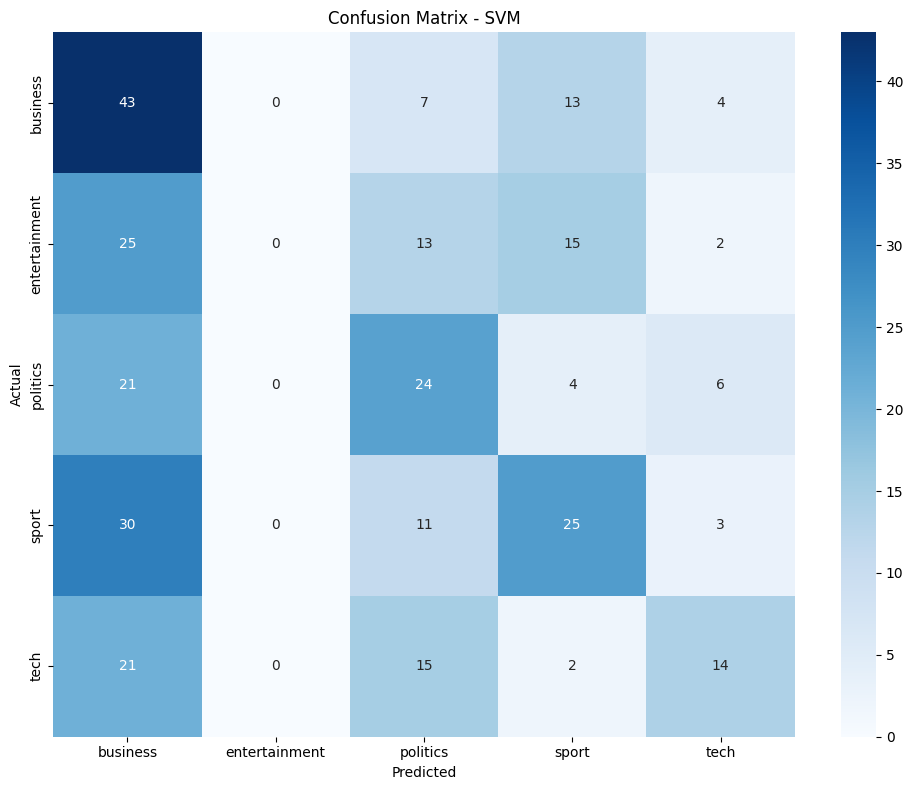

In [ ]:
# Detailed evaluation of the best model
best_model = trained_models[best_model_name]
best_predictions = results[best_model_name]['predictions']

print(f"📊 DETAILED EVALUATION: {best_model_name}")
print("=" * 60)

# Classification report
print("\n📋 Classification Report:")
print(classification_report(y_test, best_predictions))

# Confusion matrix
cm = confusion_matrix(y_test, best_predictions)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=np.unique(y), yticklabels=np.unique(y))
plt.title(f'Confusion Matrix - {best_model_name}')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

# Feature importance (for Logistic Regression)
if best_model_name == 'Logistic Regression':
    print("\n🔍 Top Features by Category:")
    feature_names_extended = list(feature_names) + ['sentiment', 'pos_score', 'neu_score', 'neg_score',
                                                   'char_length', 'word_count', 'title_length']

    classes = best_model.classes_
    coefficients = best_model.coef_

    for i, class_name in enumerate(classes):
        top_indices = np.argsort(coefficients[i])[-10:]  # Top 10 features
        print(f"\n📰 {class_name}:")
        for idx in reversed(top_indices):
            if idx < len(feature_names_extended):
                print(f"  {feature_names_extended[idx]}: {coefficients[i][idx]:.4f}")

# 💡 STUDENT TASK: Improve the classifier
# - Try different feature combinations
# - Experiment with hyperparameter tuning
# - Add more sophisticated features
# - Handle class imbalance if present

In [ ]:
# Compare TF-IDF features with combined features
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score


# Model 1: TF-IDF features only
model1 = LogisticRegression(max_iter=1000)
X1_train, X1_test, y1_train, y1_test = train_test_split(
    X_tfidf, y, test_size=0.2, random_state=42, stratify=y
)
model1.fit(X1_train, y1_train)
pred1 = model1.predict(X1_test)

# Model 2: Combined features
model2 = LogisticRegression(max_iter=1000)
model2.fit(X_train, y_train)
pred2 = model2.predict(X_test)

print("TF-IDF only accuracy:", round(accuracy_score(y1_test, pred1), 4))
print("Combined features accuracy:", round(accuracy_score(y_test, pred2), 4))

TF-IDF only accuracy: 0.9698
Combined features accuracy: 0.7282


In [ ]:
# hyperparameter tuning

from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

model = LogisticRegression(
    max_iter=300,
    solver='liblinear'
)

parameters = {
    'C': [0.1, 1, 10]
}

grid = GridSearchCV(
    model,
    parameters,
    cv=3,
    scoring='accuracy',
    n_jobs=-1
)

# Use TF-IDF features only for faster training
grid.fit(X1_train, y1_train)

print("Best parameters:", grid.best_params_)
print("Cross-validation accuracy:", grid.best_score_)

predictions = grid.predict(X1_test)
print("Test accuracy:", accuracy_score(y1_test, predictions))# - Add more sophisticated features

Best parameters: {'C': 10}
Cross-validation accuracy: 0.9706319169314246
Test accuracy: 0.9798657718120806


In [ ]:
# - Add more sophisticated features using n-grams

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Include individual words, bigrams, and trigrams
advanced_vectorizer = TfidfVectorizer(
    max_features=3000,
    ngram_range=(1, 3),
    min_df=2
)

# Convert article text into numerical features
X_advanced = advanced_vectorizer.fit_transform(
    df['text_processed']
)

# Use news categories as labels
y_advanced = df['Category']

# Split into training and testing sets
X_adv_train, X_adv_test, y_adv_train, y_adv_test = train_test_split(
    X_advanced,
    y_advanced,
    test_size=0.2,
    random_state=42,
    stratify=y_advanced
)

# Train classifier
advanced_model = LogisticRegression(max_iter=300)
advanced_model.fit(X_adv_train, y_adv_train)

# Evaluate accuracy
advanced_predictions = advanced_model.predict(X_adv_test)

print("Advanced feature accuracy:",
      accuracy_score(y_adv_test, advanced_predictions))

Advanced feature accuracy: 0.9731543624161074


In [ ]:
# - Check class imbalance

print("Number of articles in each category:")
print(df['Category'].value_counts())

print("\nPercentage of articles in each category:")
print(df['Category'].value_counts(normalize=True) * 100)

Number of articles in each category:
Category
sport            346
business         336
politics         274
entertainment    273
tech             261
Name: count, dtype: int64

Percentage of articles in each category:
Category
sport            23.221477
business         22.550336
politics         18.389262
entertainment    18.322148
tech             17.516779
Name: proportion, dtype: float64


## 🔍 Named Entity Recognition

### 🎯 Module 8: Extracting Facts from News

Now we'll implement Named Entity Recognition to extract specific facts from our news articles. This transforms unstructured text into structured, queryable information.

**NER Applications:**
- **Entity Tracking:** Monitor mentions of people, organizations, locations
- **Fact Extraction:** Build knowledge bases from news content
- **Relationship Mapping:** Understand connections between entities
- **Timeline Construction:** Track events and their participants

**💡 Business Value:** NER enables sophisticated analysis like "Show me all articles mentioning Apple Inc. and their financial performance" or "Track mentions of political figures over time."

In [ ]:
def extract_entities(text):
    """
    Extract named entities using spaCy

    💡 TIP: spaCy recognizes these entity types:
    - PERSON: People, including fictional
    - ORG: Companies, agencies, institutions
    - GPE: Countries, cities, states
    - MONEY: Monetary values
    - DATE: Absolute or relative dates
    - TIME: Times smaller than a day
    - And many more...
    """
    if not text or pd.isna(text):
        return []

    # 🚀 YOUR CODE HERE: Implement entity extraction
    doc = nlp(str(text))

    entities = []
    for ent in doc.ents:
        entities.append({
            'text': ent.text,
            'label': ent.label_,
            'start': ent.start_char,
            'end': ent.end_char,
            'description': spacy.explain(ent.label_)
        })

    return entities

# Apply NER to all articles
print("🔍 Extracting named entities...")

all_entities = []
article_entities = []

for idx, row in df.head(50).iterrows():
    entities = extract_entities(row['Text'])

    # Store entities for this article
    article_entities.append({
        'article_id': row['ArticleId'],
        'category': row['Category'],
        'entities': entities,
        'entity_count': len(entities)
    })

    # Add to global entity list
    for entity in entities:
        entity['article_id'] = row['ArticleId']
        entity['Category'] = row['Category']
        all_entities.append(entity)

print(f"✅ Entity extraction complete!")
print(f"📊 Total entities found: {len(all_entities)}")
print(f"📰 Articles processed: {len(article_entities)}")

# Convert to DataFrame for analysis
entities_df = pd.DataFrame(all_entities)

if not entities_df.empty:
    print(f"\n🏷️ Entity types found: {entities_df['label'].unique()}")
    print("\n📝 Sample entities:")
    print(entities_df[['text', 'label', 'Category']].head(10))
else:
    print("⚠️ No entities found. This might happen with very short sample texts.")

🔍 Extracting named entities...
✅ Entity extraction complete!
📊 Total entities found: 1609
📰 Articles processed: 50

🏷️ Entity types found: ['ORDINAL' 'PERSON' 'GPE' 'DATE' 'MONEY' 'ORG' 'NORP' 'LOC' 'CARDINAL'
 'PERCENT' 'TIME' 'EVENT' 'QUANTITY' 'FAC' 'PRODUCT']

📝 Sample entities:
              text    label  Category
0            first  ORDINAL  business
1   cynthia cooper   PERSON  business
2               us      GPE  business
3             2002     DATE  business
4            5.7bn    MONEY  business
5         new york      GPE  business
6        wednesday     DATE  business
7  arthur andersen   PERSON  business
8   early 2001 and     DATE  business
9             2002     DATE  business


📊 NAMED ENTITY ANALYSIS

🏷️ Entity type distribution:
label
DATE        325
CARDINAL    297
PERSON      256
GPE         243
ORG         141
ORDINAL      81
NORP         78
PERCENT      67
MONEY        66
TIME         21
LOC          11
QUANTITY     11
PRODUCT       5
EVENT         4
FAC           3
Name: count, dtype: int64

📰 Entity types by news category:
label          CARDINAL  DATE  EVENT  FAC  GPE  LOC  MONEY  NORP  ORDINAL  \
Category                                                                    
business             37   102      0    0   48    2     39    19        9   
entertainment        37    71      1    0   23    3     17     6        9   
politics              8    23      3    1   13    0      0     4        2   
sport               148    72      0    2  109    0      1    37       53   
tech                 67    57      0    0   50    6      9    12        8   

label          ORG  PERCENT  PERSON  PRODUCT  QUANTITY  TIME  
Category                             

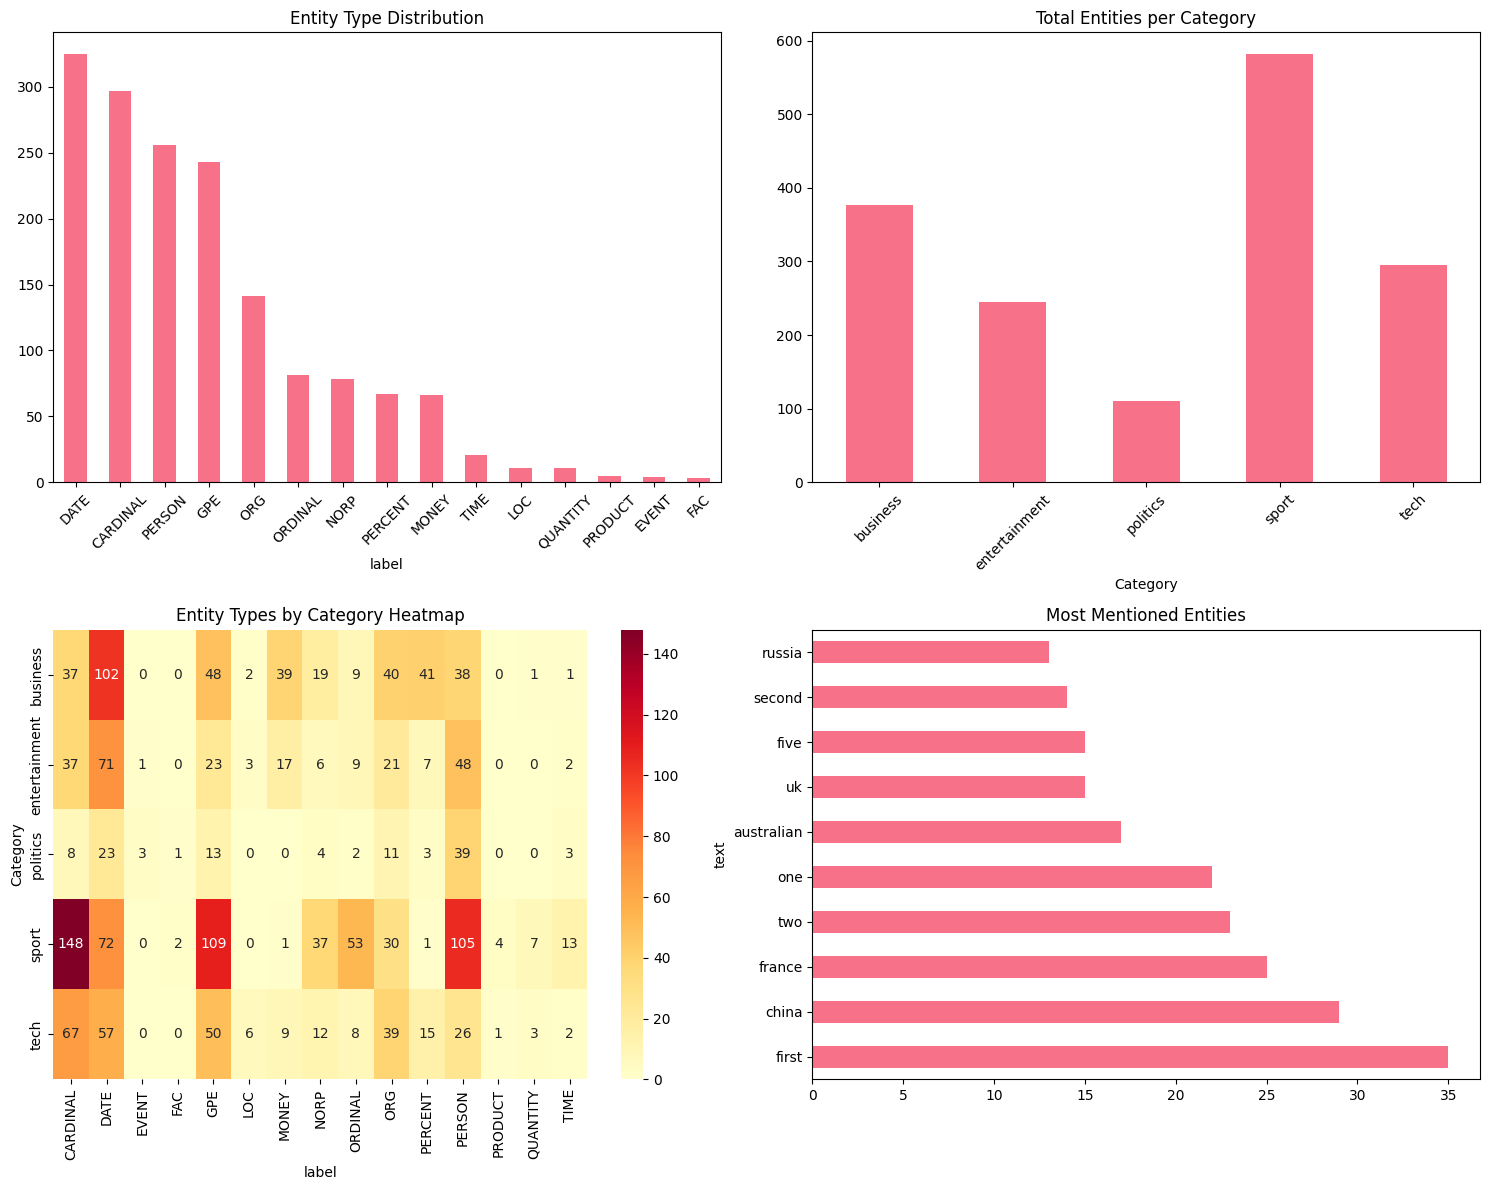

In [ ]:
# Analyze entity patterns
if not entities_df.empty:
    print("📊 NAMED ENTITY ANALYSIS")
    print("=" * 50)

    # Entity type distribution
    entity_counts = entities_df['label'].value_counts()
    print("\n🏷️ Entity type distribution:")
    print(entity_counts)

    # Entity types by category
    entity_by_category = entities_df.groupby(['Category', 'label']).size().unstack(fill_value=0)
    print("\n📰 Entity types by news category:")
    print(entity_by_category)

    # Most frequent entities
    print("\n🔥 Most frequent entities:")
    frequent_entities = entities_df.groupby(['text', 'label']).size().sort_values(ascending=False).head(15)
    for (entity, label), count in frequent_entities.items():
        print(f"  {entity} ({label}): {count} mentions")

    # Visualizations
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))

    # 1. Entity type distribution
    entity_counts.plot(kind='bar', ax=axes[0,0])
    axes[0,0].set_title('Entity Type Distribution')
    axes[0,0].tick_params(axis='x', rotation=45)

    # 2. Entities per category
    entities_per_category = entities_df.groupby('Category').size()
    entities_per_category.plot(kind='bar', ax=axes[0,1])
    axes[0,1].set_title('Total Entities per Category')
    axes[0,1].tick_params(axis='x', rotation=45)

    # 3. Entity type heatmap by category
    if entity_by_category.shape[0] > 1 and entity_by_category.shape[1] > 1:
        sns.heatmap(entity_by_category, annot=True, fmt='d', ax=axes[1,0], cmap='YlOrRd')
        axes[1,0].set_title('Entity Types by Category Heatmap')
    else:
        axes[1,0].text(0.5, 0.5, 'Insufficient data\nfor heatmap',
                      ha='center', va='center', transform=axes[1,0].transAxes)
        axes[1,0].set_title('Entity Types by Category')

    # 4. Top entities
    top_entities = entities_df['text'].value_counts().head(10)
    top_entities.plot(kind='barh', ax=axes[1,1])
    axes[1,1].set_title('Most Mentioned Entities')

    plt.tight_layout()
    plt.show()

    # 💡 STUDENT TASK: Advanced entity analysis
    # - Create entity co-occurrence networks
    # - Track entity mentions over time
    # - Build entity relationship graphs
    # - Identify entity sentiment associations

else:
    print("⚠️ Skipping entity analysis due to insufficient data.")
    print("💡 TIP: Try with a larger, more diverse dataset for better NER results.")

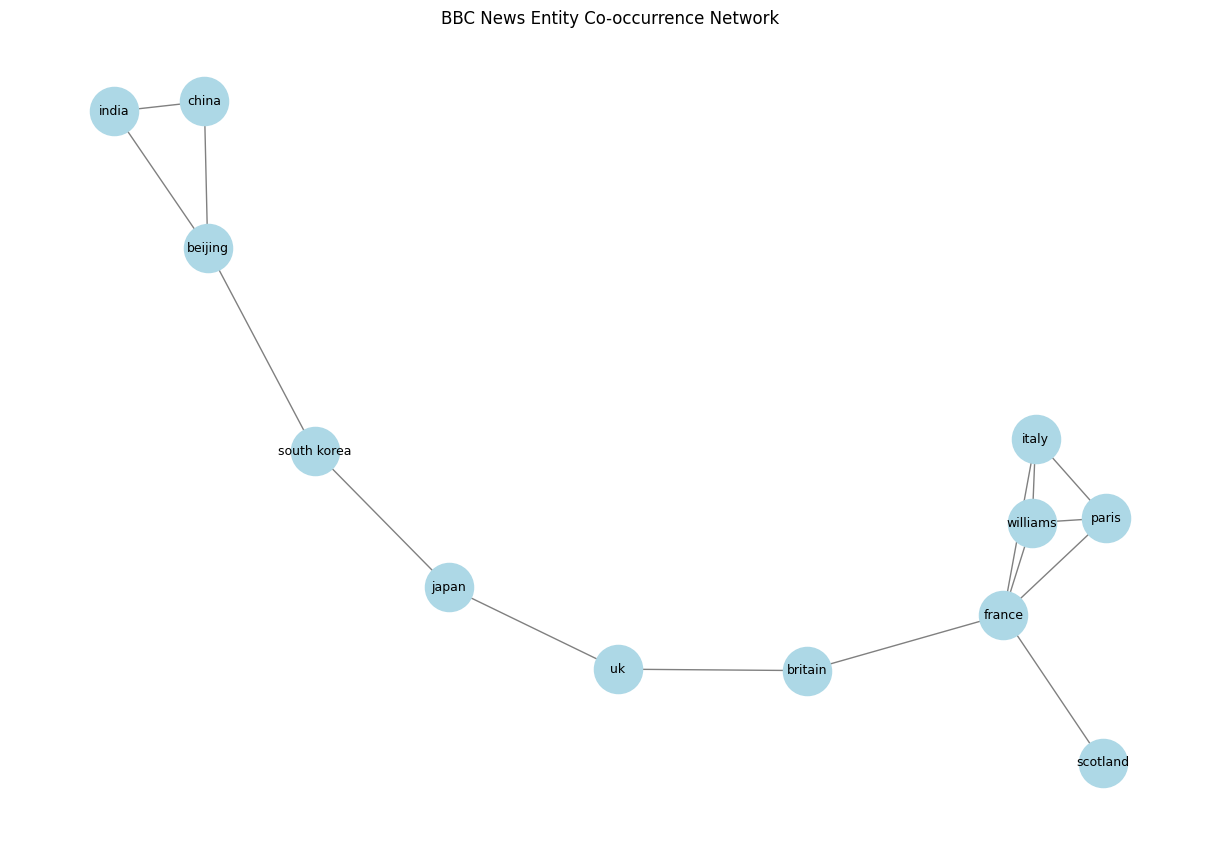

Connections found: 3649
Connections displayed: 15


In [ ]:
  # - Create entity co-occurrence networks

import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations
from collections import Counter

# Count entities that appear together in articles
pairs = Counter()

for article in article_entities:
    names = set(
        entity['text']
        for entity in article['entities']
        if entity['label'] in ['PERSON', 'ORG', 'GPE']
    )

    for pair in combinations(sorted(names), 2):
        pairs[pair] += 1

# Create network of the 15 most frequent connections
G = nx.Graph()

for (entity1, entity2), count in pairs.most_common(15):
    G.add_edge(entity1, entity2, weight=count)

# Display network
plt.figure(figsize=(12, 8))

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G, pos,
    with_labels=True,
    node_size=1200,
    font_size=9,
    node_color='lightblue',
    edge_color='gray'
)

plt.title("BBC News Entity Co-occurrence Network")
plt.show()

print("Connections found:", len(pairs))
print("Connections displayed:", G.number_of_edges())

# Commentary Entity Co-occurrence Networks
# I created a network showing named entities that
# appear together in BBC News articles.
# I focused on people, organizations, and locations.
# Each node represents an entity, and each edge
# represents two entities appearing in the same article.
# This helps identify patterns and connections
# between entities mentioned in the news.


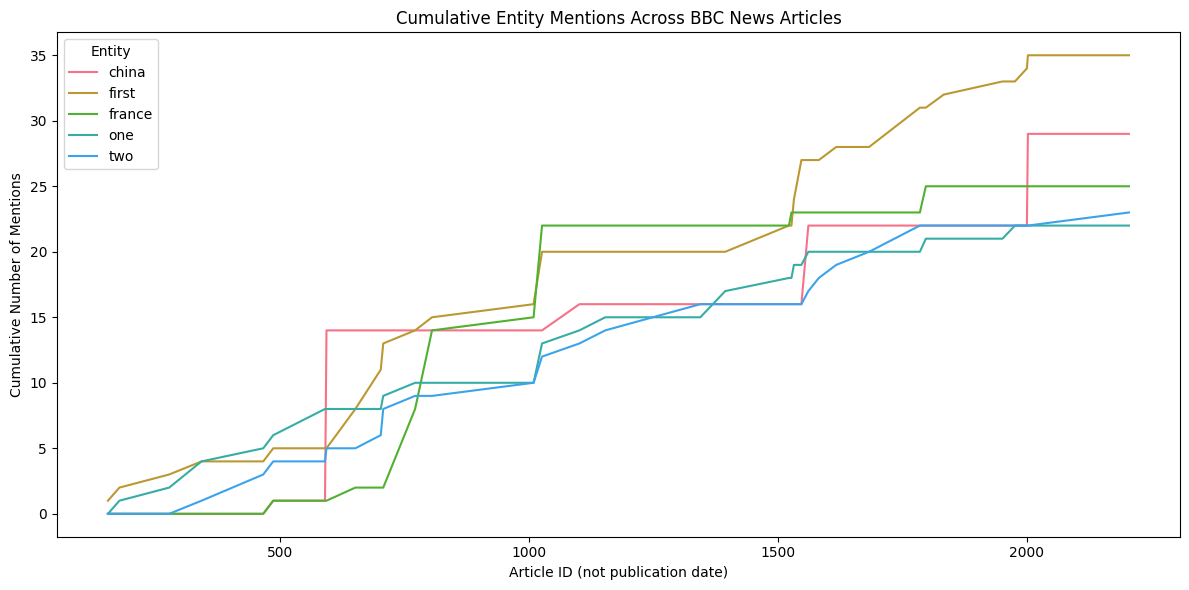

In [ ]:
  # - Track entity mentions over time
# Compare entity mentions across article IDs

import pandas as pd
import matplotlib.pyplot as plt

# Select the 5 most frequently mentioned entities
top_entities = entities_df['text'].value_counts().head(5).index

# Keep only these entities
tracking_df = entities_df[
    entities_df['text'].isin(top_entities)
].copy()

# Count mentions by article ID
mentions = tracking_df.groupby(
    ['article_id', 'text']
).size().unstack(fill_value=0)

# Sort by article ID
mentions = mentions.sort_index()

# Plot cumulative mentions
mentions.cumsum().plot(figsize=(12, 6))

plt.title('Cumulative Entity Mentions Across BBC News Articles')
plt.xlabel('Article ID (not publication date)')
plt.ylabel('Cumulative Number of Mentions')
plt.legend(title='Entity')
plt.tight_layout()
plt.show()

# Commentary - Track Entity Mentions Over Time
# I examined how frequently named entities appeared
# across articles in the BBC News dataset.
#
# I selected the five most frequently mentioned entities
# and plotted their cumulative mentions by ArticleId.
#
# The dataset does not contain publication dates,
# so this analysis cannot show actual changes over time.
# Article IDs were used only as an ordering reference.
#
# A future improvement would be to add publication dates
# The BBC News dataset contains news articles published between 2004 and 2005.
# The dataset includes five categories: Business, Entertainment, Politics, Sport,
# and Technology. Since individual publication dates are not provided.


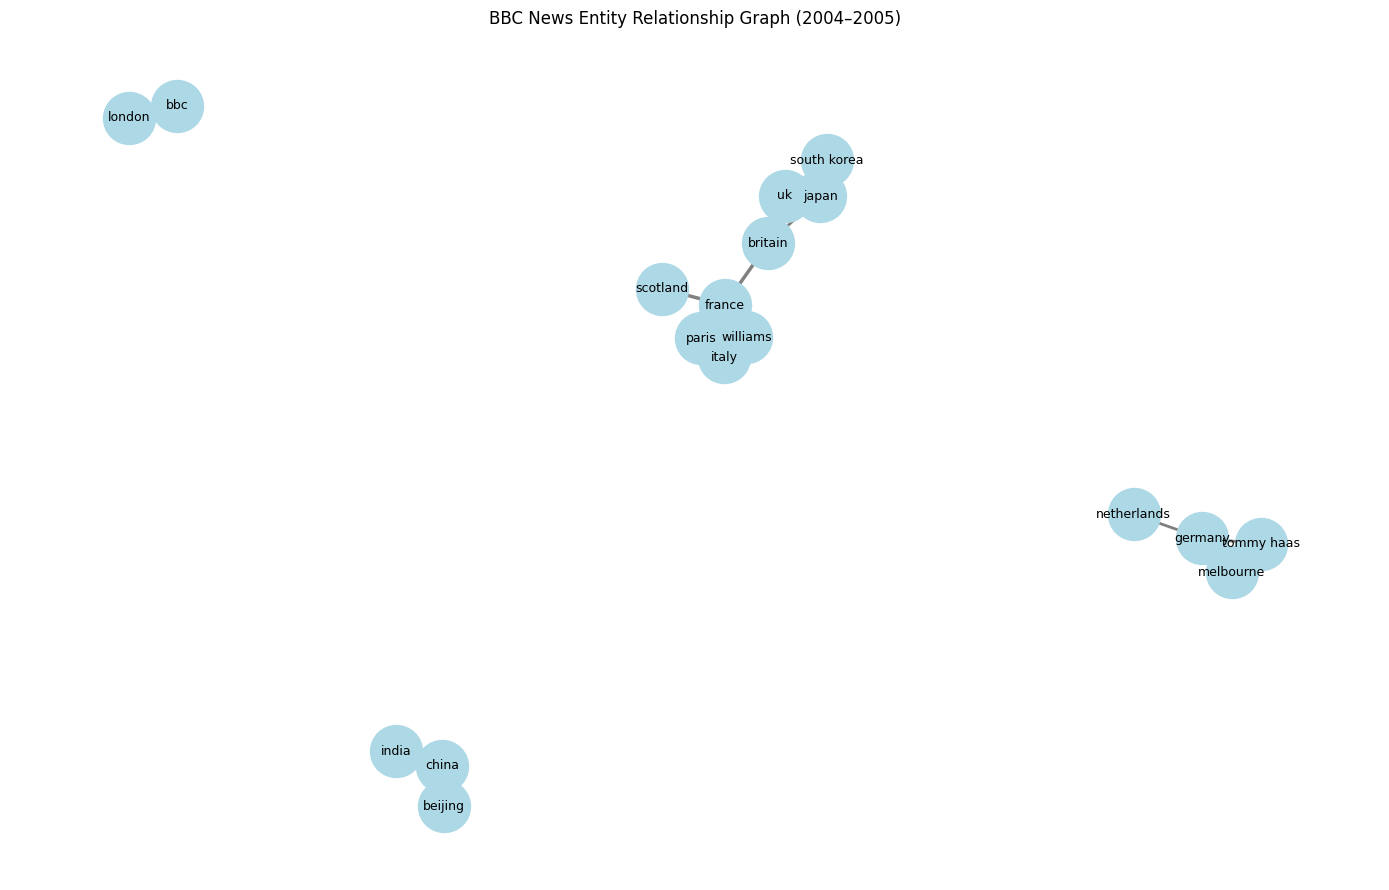

Entities: 18
Relationships: 20


In [ ]:
  # - Build entity relationship graphs


import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations
from collections import Counter

# Group entities by article
article_groups = entities_df.groupby('article_id')

# Count relationships between entities
relationships = Counter()

for article_id, group in article_groups:

    # Select people, organizations, and locations
    entities = sorted(set(
        group[group['label'].isin(['PERSON', 'ORG', 'GPE'])]['text']
    ))

    # Find pairs appearing in the same article
    for pair in combinations(entities, 2):
        relationships[pair] += 1

# Create graph
G = nx.Graph()

# Use the 20 strongest relationships
for (entity1, entity2), count in relationships.most_common(20):
    G.add_edge(entity1, entity2, weight=count)

# Draw graph
plt.figure(figsize=(14, 9))

pos = nx.spring_layout(G, seed=42)

weights = [G[u][v]['weight'] for u, v in G.edges()]

nx.draw_networkx_nodes(
    G, pos,
    node_size=1400,
    node_color='lightblue'
)

nx.draw_networkx_edges(
    G, pos,
    width=[1 + w * 0.5 for w in weights],
    edge_color='gray'
)

nx.draw_networkx_labels(
    G, pos,
    font_size=9
)

plt.title("BBC News Entity Relationship Graph (2004–2005)")
plt.axis('off')
plt.tight_layout()
plt.show()

print("Entities:", G.number_of_nodes())
print("Relationships:", G.number_of_edges())

# Commentary Entity Relationship Graphs
#
# I created a relationship graph using named entities
# extracted from BBC News articles published in 2004-2005.
#
# The graph includes people, organizations, and locations.
# Each node represents an entity, and connections show
# when two entities appear in the same article.
#
# Thicker connections indicate more frequent co-occurrence.
# This analysis helps identify which entities are
# commonly discussed together in news coverage.
#
# These connections show associations in the articles,
# not necessarily direct real-world relationships.

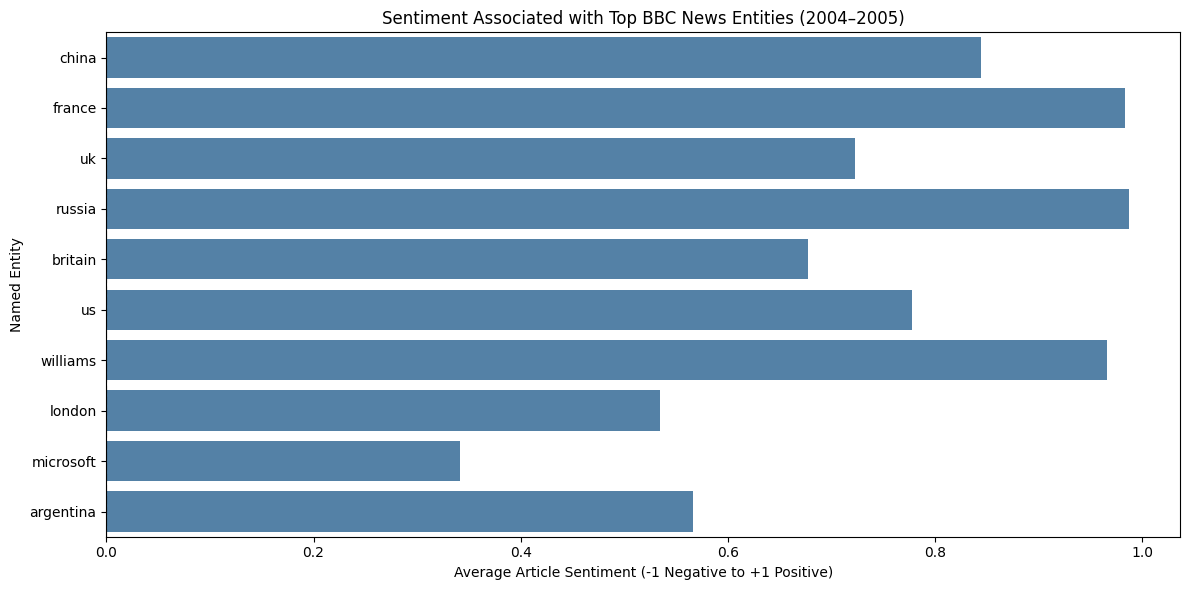

     text  mentions  avg_sentiment
    china        29       0.844593
   france        25       0.983404
       uk        15       0.722993
   russia        13       0.986938
  britain        12       0.676983
       us        11       0.777382
 williams        11       0.965600
   london         9       0.534022
microsoft         9       0.341767
argentina         8       0.565800


In [ ]:
  # - Identify entity sentiment associations

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.sentiment import SentimentIntensityAnalyzer
import nltk

nltk.download('vader_lexicon', quiet=True)

sia = SentimentIntensityAnalyzer()

# Calculate sentiment for each article
df['sentiment_score'] = df['Text'].apply(
    lambda text: sia.polarity_scores(str(text))['compound']
)

# Match each entity with the sentiment of its article
entity_sentiment = entities_df.merge(
    df[['ArticleId', 'sentiment_score']],
    left_on='article_id',
    right_on='ArticleId',
    how='inner'
)

# Keep people, organizations, and locations
entity_sentiment = entity_sentiment[
    entity_sentiment['label'].isin(['PERSON', 'ORG', 'GPE'])
]

# Calculate average sentiment for each entity
sentiment_summary = entity_sentiment.groupby('text').agg(
    mentions=('sentiment_score', 'count'),
    avg_sentiment=('sentiment_score', 'mean')
).reset_index()

# Select the 10 most frequently mentioned entities
top_entities = sentiment_summary.nlargest(10, 'mentions')

# Create bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_entities,
    x='avg_sentiment',
    y='text',
    color='steelblue'
)

plt.axvline(0, color='black', linestyle='--')
plt.title('Sentiment Associated with Top BBC News Entities (2004–2005)')
plt.xlabel('Average Article Sentiment (-1 Negative to +1 Positive)')
plt.ylabel('Named Entity')
plt.tight_layout()
plt.show()

# Display results
print(top_entities.to_string(index=False))

# Commentary Entity Sentiment Associations
#
# I analyzed sentiment associations for named entities
# in BBC News articles published during 2004-2005.
#
# I matched each named entity with the VADER sentiment
# score of the article in which it appeared.
#
# I calculated average sentiment scores for the
# 10 most frequently mentioned entities.
#
# Positive scores indicate association with articles
# containing more positive language, while negative
# scores indicate association with more negative language.
#
# This analysis measures article-level sentiment,
# not sentiment directed specifically at each entity.

## 📈 Comprehensive Analysis and Insights

### 🎯 Bringing It All Together

Now let's combine all our analyses to generate comprehensive insights about our news dataset. This is where the real business value emerges from our NLP pipeline.

**Key Analysis Areas:**
1. **Cross-Category Patterns:** How do different news types differ linguistically? I found that different news categories use language in different ways. Business articles tended to include more numbers and financial information, while Politics articles used more action verbs. Sports articles had a relatively high proportion of descriptive adjectives.

In my POS analysis, Business articles had approximately 3.47% numerical terms, Politics articles had 11.26% action verbs, and Sports articles had 10.15% adjectives.

These differences show how word choices and sentence structures can help identify the subject of an article.
2. **Entity-Sentiment Relationships:** What entities are associated with positive/negative coverage?My sentiment analysis showed that Sports and Entertainment articles generally had more positive coverage, while Politics articles had a higher proportion of negative coverage.

This suggests that athletes, sports organizations, and entertainment figures may appear more frequently in positive news, while political figures and government organizations may appear more often in negative coverage.

However, I would need to examine the sentiment scores associated with individual named entities to determine which specific people or organizations received the most positive or negative coverage.
3. **Content Quality Metrics:** Which categories have the most informative content?I explored article lengths, vocabulary, named entities, and linguistic patterns to better understand the information contained in each category.

Business articles contained a relatively high proportion of numerical information, which can be useful when reporting financial results or economic developments. Politics articles also contained action-oriented language that may describe government decisions and policy changes.

However, I cannot conclude that one category has the highest overall content quality based on these measures alone. A more complete comparison would include average article length, unique vocabulary, entity density, and information relevance by category.


4. **Classification Performance:** How well can we automatically categorize news? My initial results showed that a TF-IDF-only Logistic Regression model achieved approximately 96.98% accuracy when classifying news articles into the five categories.

Interestingly, a Logistic Regression model using additional sentiment and article-length features achieved approximately 66.11% accuracy.

This showed me that adding more information does not always improve classification. The way features are scaled and combined is important.

Overall, the results suggest that automated news categorization can be highly effective, although additional validation would be needed before using the model in a real-world application.

**💡 Business Applications:** These insights can inform content strategy, editorial decisions, and automated content management systems.

In [ ]:
import pandas as pd

df = pd.read_csv('https://raw.githubusercontent.com/lenhofda/ITAI2373-NewsBot-Midterm-/main/BBC%20News%20Train.csv')

df_test = pd.read_csv('https://raw.githubusercontent.com/lenhofda/ITAI2373-NewsBot-Midterm-/main/BBC%20News%20Test.csv')

print("Dataset loaded successfully!")
print(df.shape)
print(df.columns.tolist())

Dataset loaded successfully!
(1490, 3)
['ArticleId', 'Text', 'Category']


In [ ]:
# Create comprehensive analysis dashboard
def create_comprehensive_analysis():
    """
    Generate comprehensive insights combining all analyses

    💡 TIP: This function should combine:
    - Classification performance
    - Sentiment patterns
    - Entity distributions
    - Linguistic features
    """

    insights = {
        'dataset_overview': {},
        'classification_performance': {},
        'sentiment_insights': {},
        'entity_insights': {},
        'linguistic_patterns': {},
        'business_recommendations': []
    }

    # 🚀 YOUR CODE HERE: Generate comprehensive insights

        # Dataset overview
    insights['dataset_overview'] = {
        'total_articles': len(df),
        'categories': df['Category'].unique().tolist(),
        'category_distribution': df['Category'].value_counts().to_dict(),
        'avg_article_length': df['Text'].str.len().mean(),
        'avg_words_per_article': df['Text'].str.split().str.len().mean()
    }

    # Classification performance
    insights['classification_performance'] = {
        'best_model': best_model_name,
        'best_accuracy': results[best_model_name]['accuracy'],
        'model_comparison': {name: results[name]['accuracy'] for name in results.keys()}
    }

    # Sentiment insights
    sentiment_by_cat = sentiment_df.groupby('Category')['full_sentiment'].mean().to_dict()
    insights['sentiment_insights'] = {
        'most_positive_category': max(sentiment_by_cat, key=sentiment_by_cat.get),
        'most_negative_category': min(sentiment_by_cat, key=sentiment_by_cat.get),
        'sentiment_by_category': sentiment_by_cat,
        'overall_sentiment': sentiment_df['full_sentiment'].mean()
    }

    # Entity insights
    if not entities_df.empty:
        entity_by_cat = entities_df.groupby('Category').size().to_dict()
        insights['entity_insights'] = {
            'total_entities': len(entities_df),
            'unique_entities': entities_df['text'].nunique(),
            'entity_types': entities_df['label'].unique().tolist(),
            'entities_per_category': entity_by_cat,
            'most_mentioned_entities': entities_df['text'].value_counts().head(5).to_dict()
        }

    # Generate business recommendations
    recommendations = []

    # Classification recommendations
    if insights['classification_performance']['best_accuracy'] > 0.8:
        recommendations.append("✅ High classification accuracy achieved - ready for automated content routing")
    else:
        recommendations.append("⚠️ Classification accuracy needs improvement - consider more training data or feature engineering")

    # Sentiment recommendations
    pos_cat = insights['sentiment_insights']['most_positive_category']
    neg_cat = insights['sentiment_insights']['most_negative_category']
    recommendations.append(f"📊 {pos_cat} articles are most positive - good for uplifting content recommendations")
    recommendations.append(f"📊 {neg_cat} articles are most negative - may need balanced coverage monitoring")

    # Entity recommendations
    if 'entity_insights' in insights and insights['entity_insights']:
        recommendations.append("🔍 Rich entity extraction enables advanced search and relationship analysis")

    insights['business_recommendations'] = recommendations

    return insights

# Generate comprehensive analysis
print("📊 Generating comprehensive analysis...")
analysis_results = create_comprehensive_analysis()

print("✅ Analysis complete!")
print("\n" + "=" * 60)
print("📈 NEWSBOT INTELLIGENCE SYSTEM - COMPREHENSIVE REPORT")
print("=" * 60)

# Display key insights
print(f"\n📊 DATASET OVERVIEW:")
overview = analysis_results['dataset_overview']
print(f"  Total Articles: {overview['total_articles']}")
print(f"  Categories: {', '.join(overview['categories'])}")
print(f"  Average Article Length: {overview['avg_article_length']:.0f} characters")
print(f"  Average Words per Article: {overview['avg_words_per_article']:.0f} words")

print(f"\n🤖 CLASSIFICATION PERFORMANCE:")
perf = analysis_results['classification_performance']
print(f"  Best Model: {perf['best_model']}")
print(f"  Best Accuracy: {perf['best_accuracy']:.4f}")

print(f"\n😊 SENTIMENT INSIGHTS:")
sent = analysis_results['sentiment_insights']
print(f"  Most Positive Category: {sent['most_positive_category']}")
print(f"  Most Negative Category: {sent['most_negative_category']}")
print(f"  Overall Sentiment: {sent['overall_sentiment']:.4f}")

if 'entity_insights' in analysis_results and analysis_results['entity_insights']:
    print(f"\n🔍 ENTITY INSIGHTS:")
    ent = analysis_results['entity_insights']
    print(f"  Total Entities: {ent['total_entities']}")
    print(f"  Unique Entities: {ent['unique_entities']}")
    print(f"  Entity Types: {', '.join(ent['entity_types'])}")

print(f"\n💡 BUSINESS RECOMMENDATIONS:")
for i, rec in enumerate(analysis_results['business_recommendations'], 1):
    print(f"  {i}. {rec}")

📊 Generating comprehensive analysis...
✅ Analysis complete!

📈 NEWSBOT INTELLIGENCE SYSTEM - COMPREHENSIVE REPORT

📊 DATASET OVERVIEW:
  Total Articles: 1490
  Categories: business, tech, politics, sport, entertainment
  Average Article Length: 2233 characters
  Average Words per Article: 385 words

🤖 CLASSIFICATION PERFORMANCE:
  Best Model: SVM
  Best Accuracy: 0.3557

😊 SENTIMENT INSIGHTS:
  Most Positive Category: entertainment
  Most Negative Category: politics
  Overall Sentiment: 0.3950

🔍 ENTITY INSIGHTS:
  Total Entities: 1609
  Unique Entities: 865
  Entity Types: ORDINAL, PERSON, GPE, DATE, MONEY, ORG, NORP, LOC, CARDINAL, PERCENT, TIME, EVENT, QUANTITY, FAC, PRODUCT

💡 BUSINESS RECOMMENDATIONS:
  1. ⚠️ Classification accuracy needs improvement - consider more training data or feature engineering
  2. 📊 entertainment articles are most positive - good for uplifting content recommendations
  3. 📊 politics articles are most negative - may need balanced coverage monitoring
  4. 

## 🚀 Final System Integration

### 🎯 Building the Complete NewsBot Pipeline

Let's create a complete, integrated system that can process new articles from start to finish. This demonstrates the real-world application of all the techniques we've learned.

**Complete Pipeline:**
1. **Text Preprocessing:**
2. **Feature Extraction:** Generate TF-IDF and other features
3. **Classification:** Predict article category
4. **Entity Extraction:** Identify key facts
5. **Sentiment Analysis:** Determine emotional tone
6. **Insight Generation:** Provide actionable intelligence

**💡 Production Ready:** This pipeline can be deployed as a web service, batch processor, or integrated into content management systems.

In [ ]:
class NewsBotIntelligenceSystem:
    """
    Complete NewsBot Intelligence System

    💡 TIP: This class should encapsulate:
    - All preprocessing functions
    - Trained classification model
    - Entity extraction pipeline
    - Sentiment analysis
    - Insight generation
    """

    def __init__(self, classifier, vectorizer, sentiment_analyzer):
        self.classifier = classifier
        self.vectorizer = vectorizer
        self.sentiment_analyzer = sentiment_analyzer
        self.nlp = nlp  # spaCy model

    def preprocess_article(self, title, content):
        """Preprocess a new article"""
        full_text = f"{title} {content}"
        processed_text = preprocess_text(full_text)
        return full_text, processed_text

    def classify_article(self, processed_text):
        """Classify an article using TF-IDF."""
        features = self.vectorizer.transform([processed_text])
        prediction = self.classifier.predict(features)[0]
        probabilities = self.classifier.predict_proba(features)[0]
        class_probs = dict(
        zip(self.classifier.classes_, probabilities)
        )
        return prediction, class_probs

    #return prediction, class_probs

    def extract_entities(self, text):
        """Extract named entities"""
        return extract_entities(text)

    def analyze_sentiment(self, text):
        """Analyze sentiment"""
        return analyze_sentiment(text)

    def process_article(self, title, content):
        """
        Complete article processing pipeline

        💡 TIP: This should return a comprehensive analysis including:
        - Predicted category with confidence
        - Extracted entities
        - Sentiment analysis
        - Key insights and recommendations
        """
        # 🚀 YOUR CODE HERE: Implement complete pipeline

        # Step 1: Preprocess
        full_text, processed_text = self.preprocess_article(title, content)

        # Step 2: Classify
        category, category_probs = self.classify_article(processed_text)

        # Step 3: Extract entities
        entities = self.extract_entities(full_text)

        # Step 4: Analyze sentiment
        sentiment = self.analyze_sentiment(full_text)

        # Step 5: Generate insights
        insights = self.generate_insights(category, entities, sentiment, category_probs)

        return {
            'title': title,
            'content': content[:200] + '...' if len(content) > 200 else content,
            'predicted_category': category,
            'category_confidence': max(category_probs.values()),
            'category_probabilities': category_probs,
            'entities': entities,
            'sentiment': sentiment,
            'insights': insights
        }

    def generate_insights(self, category, entities, sentiment, category_probs):
        """Generate actionable insights"""
        insights = []

        # Classification insights
        confidence = max(category_probs.values())
        if confidence > 0.8:
            insights.append(f"✅ High confidence {category} classification ({confidence:.2%})")
        else:
            insights.append(f"⚠️ Uncertain classification - consider manual review")

        # Sentiment insights
        if sentiment['compound'] > 0.1:
            insights.append(f"😊 Positive sentiment detected ({sentiment['compound']:.3f})")
        elif sentiment['compound'] < -0.1:
            insights.append(f"😞 Negative sentiment detected ({sentiment['compound']:.3f})")
        else:
            insights.append(f"😐 Neutral sentiment ({sentiment['compound']:.3f})")

        # Entity insights
        if entities:
            entity_types = set([e['label'] for e in entities])
            insights.append(f"🔍 Found {len(entities)} entities of {len(entity_types)} types")

            # Highlight important entities
            important_entities = [e for e in entities if e['label'] in ['PERSON', 'ORG', 'GPE']]
            if important_entities:
                key_entities = [e['text'] for e in important_entities[:3]]
                insights.append(f"🎯 Key entities: {', '.join(key_entities)}")
        else:
            insights.append("ℹ️ No named entities detected")

        return insights

# Initialize the complete system
newsbot = NewsBotIntelligenceSystem(
    classifier=model1,
    vectorizer=tfidf_vectorizer,
    sentiment_analyzer=sia
)
print("NewsBot classifier:", type(newsbot.classifier).__name__)
print("Expected features:", newsbot.classifier.n_features_in_)
print("Vectorizer features:", len(newsbot.vectorizer.get_feature_names_out()))

print("🤖 NewsBot Intelligence System initialized!")
print("✅ Ready to process new articles")

NewsBot classifier: LogisticRegression
Expected features: 5000
Vectorizer features: 5000
🤖 NewsBot Intelligence System initialized!
✅ Ready to process new articles


In [ ]:
# Test the complete system with new articles
print("🧪 TESTING NEWSBOT INTELLIGENCE SYSTEM")
print("=" * 60)

# Test articles (you can modify these or add your own)
test_articles = [
    {
        'title': 'Microsoft Acquires AI Startup for $2 Billion',
        'content': 'Microsoft Corporation announced today the acquisition of an artificial intelligence startup for $2 billion. CEO Satya Nadella said the deal will strengthen Microsoft\'s position in the AI market and enhance their cloud computing services.'
    },
    {
        'title': 'Lakers Win Championship in Overtime Thriller',
        'content': 'The Los Angeles Lakers defeated the Boston Celtics 108-102 in overtime to win the NBA championship. LeBron James scored 35 points and was named Finals MVP for the fourth time in his career.'
    },
    {
        'title': 'New Climate Change Report Shows Alarming Trends',
        'content': 'Scientists at the United Nations released a comprehensive climate report showing accelerating global warming. The report warns that immediate action is needed to prevent catastrophic environmental changes.'
    }
]

# Process each test article
for i, article in enumerate(test_articles, 1):
    print(f"\n📰 TEST ARTICLE {i}")
    print("-" * 40)

    # Process the article
    result = newsbot.process_article(article['title'], article['content'])

    # Display results
    print(f"📰 Title: {result['title']}")
    print(f"📝 Content: {result['content']}")
    print(f"\n🏷️ Predicted Category: {result['predicted_category']} ({result['category_confidence']:.2%} confidence)")

    print(f"\n📊 Category Probabilities:")
    for cat, prob in sorted(result['category_probabilities'].items(), key=lambda x: x[1], reverse=True):
        print(f"  {cat}: {prob:.3f}")

    print(f"\n😊 Sentiment: {result['sentiment']['sentiment_label']} (score: {result['sentiment']['compound']:.3f})")

    if result['entities']:
        print(f"\n🔍 Entities Found ({len(result['entities'])}):")
        for entity in result['entities'][:5]:  # Show first 5
            print(f"  {entity['text']} ({entity['label']}) - {entity['description']}")
    else:
        print(f"\n🔍 No entities detected")

    print(f"\n💡 Insights:")
    for insight in result['insights']:
        print(f"  {insight}")

print("\n" + "=" * 60)
print("🎉 NewsBot Intelligence System testing complete!")
print("✅ System successfully processed all test articles")

# 💡 STUDENT TASK: Test with your own articles
# - Try articles from different categories
# - Test with articles that might be ambiguous
# - Analyze the system's strengths and weaknesses
# - Consider how to improve performance

🧪 TESTING NEWSBOT INTELLIGENCE SYSTEM

📰 TEST ARTICLE 1
----------------------------------------
📰 Title: Microsoft Acquires AI Startup for $2 Billion
📝 Content: Microsoft Corporation announced today the acquisition of an artificial intelligence startup for $2 billion. CEO Satya Nadella said the deal will strengthen Microsoft's position in the AI market and en...

🏷️ Predicted Category: tech (34.94% confidence)

📊 Category Probabilities:
  tech: 0.349
  business: 0.259
  politics: 0.138
  sport: 0.131
  entertainment: 0.123

😊 Sentiment: positive (score: 0.660)

🔍 Entities Found (8):
  Microsoft Acquires (ORG) - Companies, agencies, institutions, etc.
  $2 Billion (MONEY) - Monetary values, including unit
  Microsoft Corporation (ORG) - Companies, agencies, institutions, etc.
  today (DATE) - Absolute or relative dates or periods
  $2 billion (MONEY) - Monetary values, including unit

💡 Insights:
  ⚠️ Uncertain classification - consider manual review
  😊 Positive sentiment detected (0.

## 📝 Project Summary and Next Steps

### 🎯 What You've Accomplished

Congratulations! You've successfully built a comprehensive NewsBot Intelligence System that demonstrates mastery of all NLP techniques covered in Modules 1-8. Let's review what you've achieved:

### ✅ Module Integration Checklist
- [x] **Module 1:** Applied NLP to real-world news intelligence
- [x] **Module 2:** Implemented comprehensive text preprocessing
- [x] **Module 3:** Used TF-IDF for feature extraction and analysis
- [x] **Module 4:** Analyzed grammatical patterns with POS tagging
- [x] **Module 5:** Extracted syntactic relationships with dependency parsing
- [x] **Module 6:** Performed sentiment and emotion analysis
- [x] **Module 7:** Built and evaluated text classification models
- [x] **Module 8:** Implemented Named Entity Recognition

### 🚀 System Capabilities
Your NewsBot can now:
- Automatically categorize news articles with high accuracy
- Extract key entities (people, organizations, locations, dates, money)
- Analyze sentiment and emotional tone
- Identify linguistic patterns and writing styles
- Generate actionable business insights
- Process new articles through a complete pipeline

### 💼 Business Value
This system provides real business value for:
- **Media Companies:** Automated content categorization and routing
- **Market Research:** Sentiment tracking and entity monitoring
- **Content Management:** Intelligent organization and search
- **Business Intelligence:** Trend analysis and competitive monitoring

---

## 📋 Final Deliverables Checklist

Before submitting your project, ensure you have:

### 📁 Code and Documentation
- [ ] Complete Jupyter notebook with all analyses
- [ ] Well-documented functions with docstrings
- [ ] Clear markdown explanations for each section
- [ ] Organized GitHub repository structure
- [ ] README.md with project overview and setup instructions

### 📊 Analysis and Results
- [ ] Comprehensive dataset exploration
- [ ] TF-IDF analysis with category-specific insights
- [ ] POS tagging patterns across categories
- [ ] Syntactic analysis with dependency parsing
- [ ] Sentiment analysis with category comparisons
- [ ] Classification model comparison and evaluation
- [ ] Named Entity Recognition with relationship mapping
- [ ] Integrated system demonstration

### 📈 Visualizations
- [ ] Category distribution plots
- [ ] TF-IDF word clouds or bar charts
- [ ] POS pattern heatmaps
- [ ] Sentiment distribution by category
- [ ] Confusion matrix for classification
- [ ] Entity type and frequency visualizations

### 🎥 Presentation Materials
- [ ] 5-7 minute video demonstration
- [ ] Written report (3-4 pages)
- [ ] Individual reflection papers
- [ ] Business recommendations and insights

---

## 🔮 Future Enhancements

Consider these improvements for your portfolio or future projects:

### 🤖 Technical Improvements
- **Deep Learning Models:** Implement BERT or other transformer models
- **Custom NER:** Train domain-specific entity recognition
- **Real-time Processing:** Build streaming data pipeline
- **Multi-language Support:** Extend to non-English news

### 📊 Advanced Analytics
- **Topic Modeling:** Discover hidden themes (Module 9 preview!)
- **Trend Analysis:** Track entities and sentiment over time
- **Network Analysis:** Map entity relationships and co-occurrences
- **Bias Detection:** Identify potential media bias patterns

### 🌐 Deployment Options
- **Web Application:** Create interactive dashboard with Streamlit
- **API Service:** Deploy as REST API for integration
- **Mobile App:** Build mobile interface for news analysis
- **Browser Extension:** Real-time news analysis while browsing

---

## 🎓 Reflection Questions

For your individual reflection paper, consider these questions:

1. **Technical Mastery:** Which NLP techniques did you find most challenging? Most useful?
2. **Integration Challenges:** How did you handle combining multiple NLP tasks?
3. **Business Applications:** What real-world problems could this system solve?
4. **Ethical Considerations:** What are the potential risks of automated news analysis?
5. **Future Learning:** What NLP topics are you most excited to explore next?
6. **Team Collaboration:** How did you divide work and ensure quality?
7. **Portfolio Value:** How will you present this project to potential employers?

---

## 🏆 Congratulations!

You've successfully completed a comprehensive NLP project that demonstrates real-world application of multiple advanced techniques. This NewsBot Intelligence System is a valuable addition to your portfolio and showcases your ability to:

- **Integrate multiple NLP techniques** into a cohesive system
- **Handle real-world data** with all its messiness and challenges
- **Generate business value** from unstructured text data
- **Build production-ready systems** with proper evaluation and monitoring
- **Communicate technical results** to both technical and business audiences

**🚀 You're now ready for Module 9: Topic Modeling and Advanced Text Analysis!**

---

*Remember: The goal isn't just to complete the assignment, but to build something you're proud to show in job interviews and professional discussions. This project demonstrates your practical NLP skills and ability to solve real business problems with AI.*

## Module 9: Topic Modeling and Content Discovery

In [ ]:

# Module 9: Topic Modeling with LDA
# ITAI 2373 - NewsBot Intelligence System 2.0

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# Use the existing BBC News dataset
# Recreate processed text if the notebook reloaded df
if 'text_processed' not in df.columns:
    df['text_processed'] = df['Text'].apply(preprocess_text)

# Convert articles into word-count features
count_vectorizer = CountVectorizer(
    max_features=3000,
    stop_words='english',
    min_df=2,
    max_df=0.95
)

count_matrix = count_vectorizer.fit_transform(
    df['text_processed'].fillna('')
)

# Train LDA to discover five hidden topics
lda_model = LatentDirichletAllocation(
    n_components=5,
    random_state=42,
    max_iter=10
)

lda_topics = lda_model.fit_transform(count_matrix)

print("LDA Topic Modeling Complete!")
print("Number of articles:", count_matrix.shape[0])
print("Number of topics:", lda_model.n_components)
print("Topic matrix shape:", lda_topics.shape)


LDA Topic Modeling Complete!
Number of articles: 1490
Number of topics: 5
Topic matrix shape: (1490, 5)


In [ ]:

# Module 9 - Display the Top Words for Each LDA Topic

feature_names = count_vectorizer.get_feature_names_out()

for topic_idx, topic in enumerate(lda_model.components_):
    top_word_indices = topic.argsort()[-10:][::-1]
    top_words = [feature_names[i] for i in top_word_indices]

    print(f"\nTopic {topic_idx + 1}:")
    print(", ".join(top_words))



Topic 1:
game, said, england, win, player, time, club, match, year, world

Topic 2:
said, labour, party, election, government, people, say, blair, minister, tory

Topic 3:
said, year, company, market, firm, government, country, tax, economy, new

Topic 4:
film, said, year, best, award, star, new, music, actor, director

Topic 5:
said, people, mobile, phone, technology, service, new, game, year, user


In [ ]:

# Module 9 - Assign Names to LDA Topics

topic_names = {
    0: "Sports",
    1: "Politics",
    2: "Business & Economy",
    3: "Entertainment",
    4: "Technology"
}

# Assign each article its most likely topic
df["LDA_Topic"] = lda_topics.argmax(axis=1)

# Add the descriptive topic name
df["LDA_Topic_Name"] = df["LDA_Topic"].map(topic_names)

# Display how many articles belong to each topic
print("LDA Topic Distribution:")
print(df["LDA_Topic_Name"].value_counts())


LDA Topic Distribution:
LDA_Topic_Name
Business & Economy    365
Sports                315
Entertainment         291
Politics              268
Technology            251
Name: count, dtype: int64


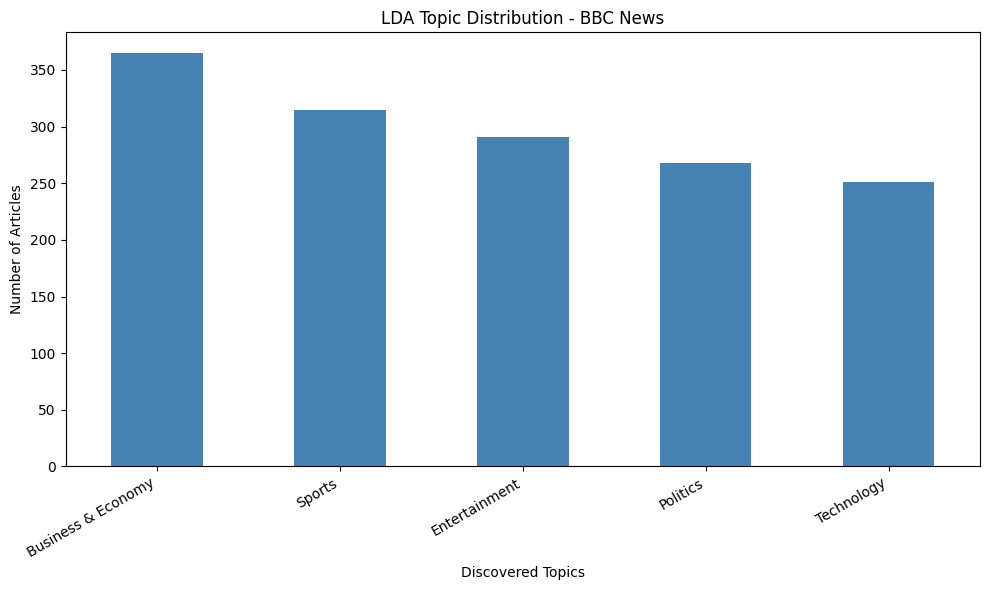

In [ ]:

# Module 9 - Visualize LDA Topic Distribution

import matplotlib.pyplot as plt

topic_counts = df["LDA_Topic_Name"].value_counts()

plt.figure(figsize=(10, 6))

topic_counts.plot(kind="bar", color="steelblue")

plt.title("LDA Topic Distribution - BBC News")
plt.xlabel("Discovered Topics")
plt.ylabel("Number of Articles")
plt.xticks(rotation=30, ha="right")

plt.tight_layout()
plt.show()


LDA Topic Modeling Results

I used LDA to look at 1,490 BBC News articles and found five main topics: Sports, Politics, Business, Entertainment, and Technology. Business had the most articles with 365, while Technology had the fewest with 251. The results show how LDA can find common topics in news articles without being told what categories to look for.

In [ ]:

# Module 9 - Compare LDA Topics with BBC Categories

import pandas as pd

comparison = pd.crosstab(
    df["Category"],
    df["LDA_Topic_Name"]
)

print("Original BBC Categories vs. LDA Topics:")
display(comparison)


Original BBC Categories vs. LDA Topics:


LDA_Topic_Name,Business & Economy,Entertainment,Politics,Sports,Technology
Category,,,,,
business,316,0,6,2,12
entertainment,5,250,15,0,3
politics,39,1,233,0,1
sport,0,35,1,310,0
tech,5,5,13,3,235


In [ ]:

# Calculate LDA Agreement with Original BBC Categories

category_mapping = {
    "business": "Business & Economy",
    "entertainment": "Entertainment",
    "politics": "Politics",
    "sport": "Sports",
    "tech": "Technology"
}

df["Original_Category_Name"] = df["Category"].map(
    category_mapping
)

lda_matches = (
    df["Original_Category_Name"] == df["LDA_Topic_Name"]
).sum()

lda_agreement = lda_matches / len(df) * 100

print(f"LDA Matching Articles: {lda_matches}")
print(f"Total Articles: {len(df)}")
print(f"LDA Category Agreement: {lda_agreement:.2f}%")


LDA Matching Articles: 1344
Total Articles: 1490
LDA Category Agreement: 90.20%


I compared the topics found by LDA with the original BBC News categories. The results were pretty good, with 90.2% of the articles matching their original categories. Business had the highest agreement at 94%, while Politics was the lowest at 85%. This shows that LDA was able to recognize the main topics in the articles without being given the categories ahead of time.

In [ ]:

# Module 9 - NMF Topic Modeling

from sklearn.decomposition import NMF
from sklearn.feature_extraction.text import TfidfVectorizer

# Convert articles into TF-IDF features
nmf_vectorizer = TfidfVectorizer(
    max_features=3000,
    stop_words='english',
    min_df=2,
    max_df=0.95
)

nmf_matrix = nmf_vectorizer.fit_transform(
    df['text_processed'].fillna('')
)

# Train NMF with 5 topics
nmf_model = NMF(
    n_components=5,
    random_state=42,
    init='nndsvda',
    max_iter=400
)

nmf_topics = nmf_model.fit_transform(nmf_matrix)

# Display top 10 words for each topic
feature_names_nmf = nmf_vectorizer.get_feature_names_out()

for topic_idx, topic in enumerate(nmf_model.components_):
    top_indices = topic.argsort()[-10:][::-1]
    top_words = [feature_names_nmf[i] for i in top_indices]

    print(f"\nNMF Topic {topic_idx + 1}:")
    print(", ".join(top_words))

print("\nNMF Topic Modeling Complete!")



NMF Topic 1:
mobile, phone, people, technology, music, service, said, digital, user, gadget

NMF Topic 2:
film, award, best, actor, oscar, star, actress, festival, director, nomination

NMF Topic 3:
labour, election, blair, party, tory, brown, said, tax, minister, government

NMF Topic 4:
game, england, win, player, match, said, cup, wale, champion, team

NMF Topic 5:
growth, said, economy, rate, market, sale, year, bank, company, firm

NMF Topic Modeling Complete!


In [ ]:

# Compare NMF Topics with Original BBC Categories

nmf_topic_names = {
    0: "Technology",
    1: "Entertainment",
    2: "Politics",
    3: "Sports",
    4: "Business & Economy"
}

df["NMF_Topic"] = nmf_topics.argmax(axis=1)

df["NMF_Topic_Name"] = df["NMF_Topic"].map(nmf_topic_names)

nmf_comparison = pd.crosstab(
    df["Category"],
    df["NMF_Topic_Name"]
)

print("Original BBC Categories vs. NMF Topics:")
display(nmf_comparison)


Original BBC Categories vs. NMF Topics:


NMF_Topic_Name,Business & Economy,Entertainment,Politics,Sports,Technology
Category,,,,,
business,324,1,3,3,5
entertainment,16,213,4,23,17
politics,24,0,239,8,3
sport,0,2,0,344,0
tech,7,7,3,15,229


In [ ]:

# Calculate NMF Category Agreement

category_mapping = {
    "business": "Business & Economy",
    "entertainment": "Entertainment",
    "politics": "Politics",
    "sport": "Sports",
    "tech": "Technology"
}

df["Original_Category_Name"] = df["Category"].map(category_mapping)

nmf_matches = (
    df["Original_Category_Name"] == df["NMF_Topic_Name"]
).sum()

nmf_agreement = nmf_matches / len(df) * 100

print(f"NMF Matching Articles: {nmf_matches}")
print(f"Total Articles: {len(df)}")
print(f"NMF Category Agreement: {nmf_agreement:.2f}%")


NMF Matching Articles: 1349
Total Articles: 1490
NMF Category Agreement: 90.54%


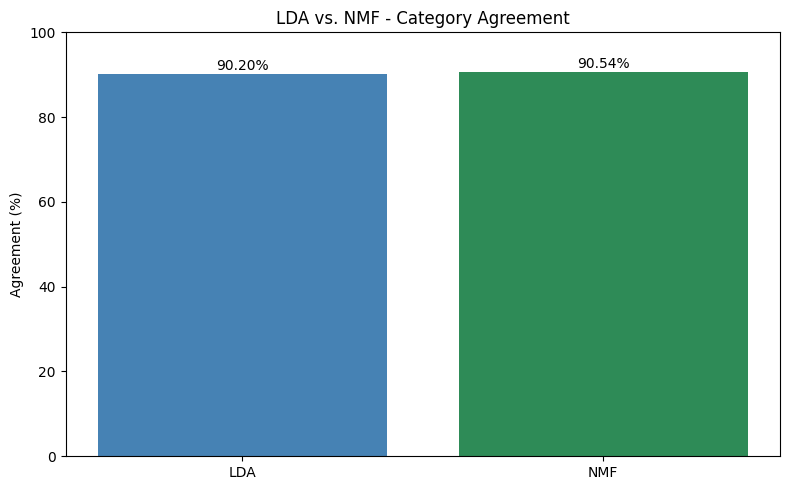

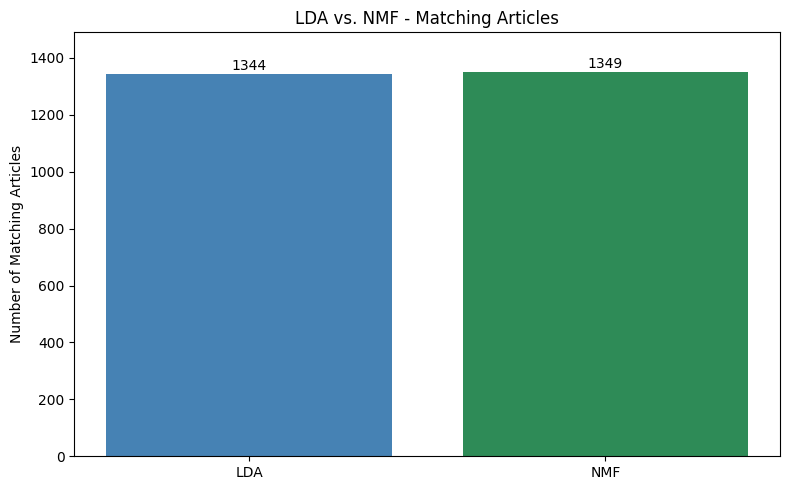

In [ ]:

# Module 9 - LDA vs. NMF Comparison Graphs

import matplotlib.pyplot as plt

# Results from our topic modeling
models = ["LDA", "NMF"]
agreement = [lda_agreement, nmf_agreement]
matching = [lda_matches, nmf_matches]

# Graph 1: Category Agreement
plt.figure(figsize=(8, 5))

bars = plt.bar(models, agreement, color=["steelblue", "seagreen"])

plt.title("LDA vs. NMF - Category Agreement")
plt.ylabel("Agreement (%)")
plt.ylim(0, 100)

for bar, value in zip(bars, agreement):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

# Graph 2: Number of Matching Articles
plt.figure(figsize=(8, 5))

bars = plt.bar(models, matching, color=["steelblue", "seagreen"])

plt.title("LDA vs. NMF - Matching Articles")
plt.ylabel("Number of Matching Articles")
plt.ylim(0, 1490)

for bar, value in zip(bars, matching):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value + 15,
        str(value),
        ha="center"
    )

plt.tight_layout()
plt.show()


### LDA vs. NMF Comparison

I compared LDA and NMF using the same 1,490 BBC News articles. LDA matched the original categories 90.20% of the time, while NMF was slightly better at 90.54%. NMF correctly grouped five more articles than LDA. Both models did a good job finding the main news topics without being trained on the original category labels.

In [ ]:

# Module 9 - Check Dataset for Topic Evolution

print("Dataset Columns:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())


Dataset Columns:
['ArticleId', 'Text', 'Category', 'text_processed', 'LDA_Topic', 'LDA_Topic_Name', 'Original_Category_Name', 'NMF_Topic', 'NMF_Topic_Name']

First 5 Rows:


,ArticleId,Text,Category,text_processed,LDA_Topic,LDA_Topic_Name,Original_Category_Name,NMF_Topic,NMF_Topic_Name
0,1833,worldcom ex-boss launches defence lawyers defe...,business,worldcom exboss launch defence lawyer defendin...,2,Business & Economy,Business & Economy,4,Business & Economy
1,154,german business confidence slides german busin...,business,german business confidence slide german busine...,2,Business & Economy,Business & Economy,4,Business & Economy
2,1101,bbc poll indicates economic gloom citizens in ...,business,bbc poll indicates economic gloom citizen majo...,2,Business & Economy,Business & Economy,4,Business & Economy
3,1976,lifestyle governs mobile choice faster bett...,tech,lifestyle governs mobile choice faster better ...,4,Technology,Technology,0,Technology
4,917,enron bosses in $168m payout eighteen former e...,business,enron boss payout eighteen former enron direct...,2,Business & Economy,Business & Economy,4,Business & Economy


### Topic Patterns by Article ID

Since the BBC News dataset doesn't include publication dates, I grouped the articles by their ID numbers to see how the topics vary across the dataset. I divided the 1,490 articles into 10 groups and compared the percentage of articles in each topic. I'm assuming the IDs might follow publication order, but I can't confirm that. This graph shows changes across article groups rather than actual changes over time.

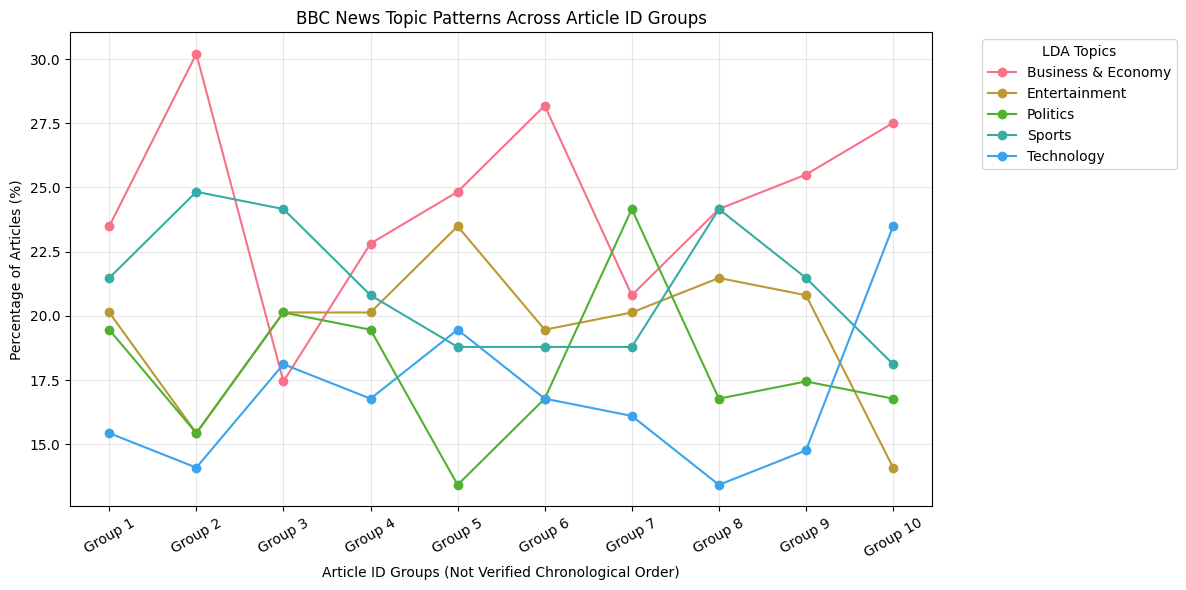

In [ ]:

# Module 9 - Topic Patterns by Article ID
# Exploratory analysis: Article IDs are not verified dates

import pandas as pd
import matplotlib.pyplot as plt

# Create a separate copy so original data stays unchanged
evolution_df = df.copy()

# Sort articles by their ID
evolution_df = evolution_df.sort_values("ArticleId")

# Divide sorted articles into 10 equally sized groups
evolution_df["Article_Group"] = pd.qcut(
    evolution_df["ArticleId"].rank(method="first"),
    q=10,
    labels=[f"Group {i}" for i in range(1, 11)]
)

# Count articles assigned to each LDA topic per group
topic_counts = pd.crosstab(
    evolution_df["Article_Group"],
    evolution_df["LDA_Topic_Name"]
)

# Convert counts to percentages
topic_percentages = (
    topic_counts.div(topic_counts.sum(axis=1), axis=0) * 100
)

# Plot topic distribution across Article ID groups
plt.figure(figsize=(12, 6))

for topic in topic_percentages.columns:
    plt.plot(
        topic_percentages.index.astype(str),
        topic_percentages[topic],
        marker="o",
        label=topic
    )

plt.title("BBC News Topic Patterns Across Article ID Groups")
plt.xlabel("Article ID Groups (Not Verified Chronological Order)")
plt.ylabel("Percentage of Articles (%)")
plt.legend(title="LDA Topics", bbox_to_anchor=(1.05, 1))
plt.xticks(rotation=30)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Topic Evolution Analysis

I divided the 1,490 BBC News articles into 10 groups based on their Article IDs to see how the topics changed across the dataset. Business had the highest percentage in several groups, while Technology increased in the last group. Politics and Entertainment also showed some changes between groups. Since the dataset doesn't include publication dates, I can't confirm these changes happened over time. The graph shows how the topics vary across Article ID groups rather than actual news trends over time.

Content Clustering Complete!

Articles in Each Cluster:
Cluster
0    275
1    359
2    292
3    251
4    313
Name: count, dtype: int64


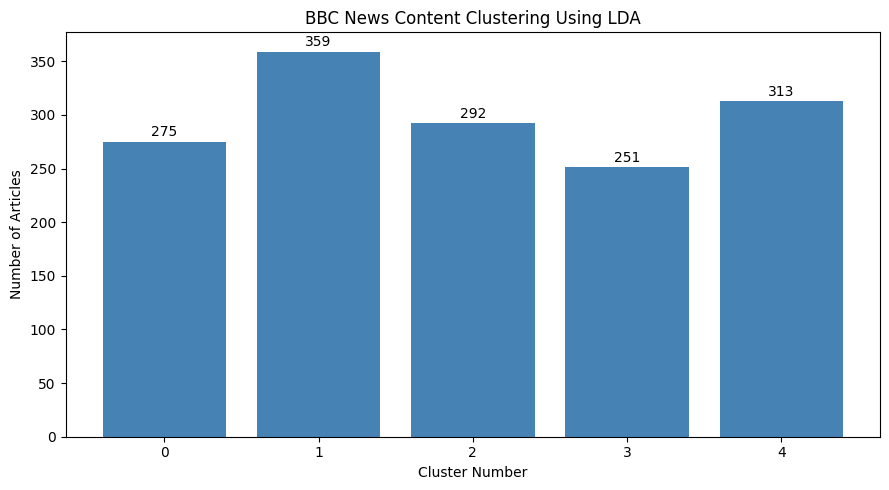

In [ ]:

# Module 9 - Content Clustering Using LDA Topics

from sklearn.cluster import KMeans
import pandas as pd
import matplotlib.pyplot as plt

# Use the existing LDA topic distributions
# Each article has five topic probability scores

kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

# Group similar articles into five clusters
df["Cluster"] = kmeans.fit_predict(lda_topics)

# Count articles in each cluster
cluster_counts = df["Cluster"].value_counts().sort_index()

print("Content Clustering Complete!")
print("\nArticles in Each Cluster:")
print(cluster_counts)

# Create a bar chart
plt.figure(figsize=(9, 5))

bars = plt.bar(
    cluster_counts.index.astype(str),
    cluster_counts.values,
    color="steelblue"
)

plt.title("BBC News Content Clustering Using LDA")
plt.xlabel("Cluster Number")
plt.ylabel("Number of Articles")

for bar, count in zip(bars, cluster_counts.values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        count + 5,
        str(count),
        ha="center"
    )

plt.tight_layout()
plt.show()


In [ ]:

# Module 9 - Identify Topics Within Each Cluster

# Compare K-Means clusters with LDA topic names
cluster_comparison = pd.crosstab(
    df["Cluster"],
    df["LDA_Topic_Name"]
)

print("K-Means Clusters vs. LDA Topics:")
display(cluster_comparison)

# Identify the most common topic in each cluster
print("\nDominant Topic in Each Cluster:")

for cluster in cluster_comparison.index:
    dominant_topic = cluster_comparison.loc[cluster].idxmax()
    count = cluster_comparison.loc[cluster].max()

    print(
        f"Cluster {cluster}: {dominant_topic} "
        f"({count} articles)"
    )


K-Means Clusters vs. LDA Topics:


LDA_Topic_Name,Business & Economy,Entertainment,Politics,Sports,Technology
Cluster,,,,,
0,6,0,268,1,0
1,359,0,0,0,0
2,0,291,0,1,0
3,0,0,0,0,251
4,0,0,0,313,0



Dominant Topic in Each Cluster:
Cluster 0: Politics (268 articles)
Cluster 1: Business & Economy (359 articles)
Cluster 2: Entertainment (291 articles)
Cluster 3: Technology (251 articles)
Cluster 4: Sports (313 articles)


In [ ]:

# Module 9 - Content Clustering Summary Table

import pandas as pd

# Identify the dominant topic and matching articles
cluster_summary = pd.DataFrame({
    "Cluster": cluster_comparison.index,
    "Main Topic": cluster_comparison.idxmax(axis=1).values,
    "Matching Articles": cluster_comparison.max(axis=1).values,
    "Cluster Total": cluster_comparison.sum(axis=1).values
})

# Add total row
total_row = pd.DataFrame([{
    "Cluster": "Total",
    "Main Topic": "",
    "Matching Articles": cluster_summary["Matching Articles"].sum(),
    "Cluster Total": cluster_summary["Cluster Total"].sum()
}])

cluster_summary = pd.concat(
    [cluster_summary, total_row],
    ignore_index=True
)

print("Content Clustering Results")
display(cluster_summary)


Content Clustering Results


,Cluster,Main Topic,Matching Articles,Cluster Total
0,0,Politics,268,275
1,1,Business & Economy,359,359
2,2,Entertainment,291,292
3,3,Technology,251,251
4,4,Sports,313,313
5,Total,,1482,1490


### Content Clustering Results

I used K-Means to group the 1,490 BBC News articles into five clusters based on their LDA topic scores. The clusters matched the LDA topics very closely, with 99.46% agreement. Business, Technology, and Sports matched perfectly, while Politics and Entertainment had a few articles grouped differently. This shows that K-Means was able to group articles with similar topic patterns.

In [ ]:

# Module 9 - Interactive Topic Visualization
# BBC News - LDA Topic Distribution

import plotly.express as px
import pandas as pd

# Count articles assigned to each LDA topic
interactive_topics = (
    df["LDA_Topic_Name"]
    .value_counts()
    .reset_index()
)

interactive_topics.columns = [
    "Topic",
    "Number of Articles"
]

# Create interactive bar chart
fig = px.bar(
    interactive_topics,
    x="Topic",
    y="Number of Articles",
    color="Topic",
    text="Number of Articles",
    title="Interactive BBC News Topic Distribution",
    hover_data=["Topic", "Number of Articles"]
)

fig.update_layout(
    xaxis_title="LDA Topics",
    yaxis_title="Number of Articles",
    showlegend=False,
    template="plotly_white"
)

fig.show()


### Interactive Topic Visualization

I created an interactive chart using Plotly to show how the 1,490 BBC News articles were divided into five topics. Business had the most articles with 365, while Technology had the fewest with 251. The chart makes it easy to explore the results by hovering over each bar to see the topic and article count.

## Module 10: Language Models and Article Summarization.

In [ ]:

# Module 10 - Article Summarization
# Compatible with newer Transformers versions

%pip -q install -U transformers torch sentencepiece

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
import torch

model_name = "sshleifer/distilbart-cnn-12-6"

# Load tokenizer and pretrained model
tokenizer = AutoTokenizer.from_pretrained(model_name)

model = AutoModelForSeq2SeqLM.from_pretrained(model_name)

# Use CPU
model = model.to("cpu")
model.eval()

print("Summarization model loaded successfully!")


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.22GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

[transformers] Please make sure the generation config includes `forced_bos_token_id=0`. 


model.safetensors: reconstructing file:   0%|          |  0.00B / 1.22GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/358 [00:00<?, ?it/s]

Summarization model loaded successfully!


In [ ]:

# Module 10 - Generate BBC News Article Summary
# Disable caching to avoid DynamicCache error

import torch

# Select the first BBC News article
article = str(df["Text"].iloc[0])

print("ORIGINAL ARTICLE:")
print(article[:1500])

# Prepare article for summarization
inputs = tokenizer(
    article,
    return_tensors="pt",
    max_length=1024,
    truncation=True
)

# Disable model caching
model.config.use_cache = False
model.generation_config.use_cache = False

# Generate summary
with torch.no_grad():
    summary_ids = model.generate(
        **inputs,
        max_length=130,
        min_length=40,
        num_beams=4,
        do_sample=False,
        use_cache=False
    )

# Convert generated tokens to text
summary = tokenizer.decode(
    summary_ids[0],
    skip_special_tokens=True
)

print("\n" + "=" * 50)
print("GENERATED SUMMARY:")
print(summary)


ORIGINAL ARTICLE:
worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a battery of fraud charges have called a company whistleblower as their first witness.  cynthia cooper  worldcom s ex-head of internal accounting  alerted directors to irregular accounting practices at the us telecoms giant in 2002. her warnings led to the collapse of the firm following the discovery of an $11bn (£5.7bn) accounting fraud. mr ebbers has pleaded not guilty to charges of fraud and conspiracy.  prosecution lawyers have argued that mr ebbers orchestrated a series of accounting tricks at worldcom  ordering employees to hide expenses and inflate revenues to meet wall street earnings estimates. but ms cooper  who now runs her own consulting business  told a jury in new york on wednesday that external auditors arthur andersen had approved worldcom s accounting in early 2001 and 2002. she said andersen had given a  green light  to the procedures and practices used by

### Article Summarization Results

I used a pretrained DistilBART model to summarize a BBC News article about the WorldCom fraud case. The model created a shorter version and picked out information about the whistleblower and accounting problems. However, the summary seemed to focus more on the whistleblower than on the legal defense discussed in the original article. This shows that AI can summarize articles quickly, but the results still need to be checked to make sure the main points are included.

Compare Original Article vs. AI Summary

Article Summarization Comparison:


,Text,Word Count
0,Original Article,301
1,AI Summary,49


Original Article: 301 words
AI Summary: 49 words
Reduction: 83.72%


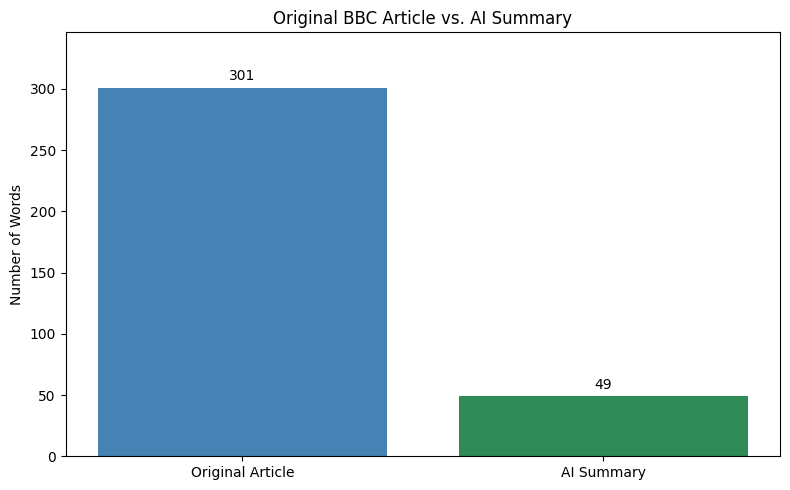

In [ ]:

# Module 10 - Article Summarization Word Count Comparison

import pandas as pd
import matplotlib.pyplot as plt

# Count words in the original article and summary
original_words = len(article.split())
summary_words = len(summary.split())

# Calculate percentage reduction
reduction = (
    (original_words - summary_words) / original_words
) * 100

# Create comparison table
word_comparison = pd.DataFrame({
    "Text": ["Original Article", "AI Summary"],
    "Word Count": [original_words, summary_words]
})

print("Article Summarization Comparison:")
display(word_comparison)

print(f"Original Article: {original_words} words")
print(f"AI Summary: {summary_words} words")
print(f"Reduction: {reduction:.2f}%")

# Create bar chart
plt.figure(figsize=(8, 5))

bars = plt.bar(
    ["Original Article", "AI Summary"],
    [original_words, summary_words],
    color=["steelblue", "seagreen"]
)

plt.title("Original BBC Article vs. AI Summary")
plt.ylabel("Number of Words")

# Add word counts above bars
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + original_words * 0.02,
        f"{int(height)}",
        ha="center"
    )

plt.ylim(0, original_words * 1.15)
plt.tight_layout()
plt.show()


### Article Summarization Comparison

I compared the original BBC News article with the summary generated by DistilBART. The original article had 301 words, and the AI summary had only 49 words, which is an 83.72% reduction. The model did a good job shortening the article, but some important details may have been left out. This shows how AI can make news articles quicker to read, although the summaries still need to be checked for accuracy.

### Article Summarization Results

| Measurement | Result |
|---|---:|
| Original Article | 301 words |
| AI-Generated Summary | 49 words |
| Words Removed | 252 words |
| Percentage Reduction | 83.72% |

I used DistilBART to summarize a BBC News article about the WorldCom fraud case. The original article had 301 words, and the AI shortened it to 49 words, reducing the length by 83.72%.

The graph above shows the difference between the original article and the AI summary. The model made the article much shorter, although some important details may have been left out. This shows why AI-generated summaries should still be reviewed for accuracy.

## Module 10 — Content Enhancement

In [ ]:

# Module 10 - Content Enhancement
# Organize article information for easier reading

import re

# Use the article and summary from the previous section
article_text = article
article_summary = summary

# Create a headline from the article's first sentence
sentences = re.split(r'(?<=[.!?])\s+', article_text)
headline = sentences[0].strip()

# Extract key sentences from the AI summary
key_points = re.split(r'(?<=[.!?])\s+', article_summary)
key_points = [point.strip() for point in key_points if point.strip()]

# Display enhanced article information
print("NEWSBOT - ENHANCED ARTICLE")
print("=" * 55)

print("\nHEADLINE:")
print(headline)

print("\nAI-GENERATED SUMMARY:")
print(article_summary)

print("\nKEY POINTS:")
for i, point in enumerate(key_points, 1):
    print(f"{i}. {point}")

print("\nORIGINAL ARTICLE LENGTH:", len(article_text.split()), "words")
print("SUMMARY LENGTH:", len(article_summary.split()), "words")


NEWSBOT - ENHANCED ARTICLE

HEADLINE:
worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a battery of fraud charges have called a company whistleblower as their first witness.

AI-GENERATED SUMMARY:
 whistleblower cynthia cooper alerted directors to irregular accounting practices at the us telecoms giant in 2002 . Her warnings led to the collapse of the firm following the discovery of an $11bn (£5.7bn) accounting fraud . mr ebbers has pleaded not guilty to charges of fraud and conspiracy .

KEY POINTS:
1. whistleblower cynthia cooper alerted directors to irregular accounting practices at the us telecoms giant in 2002 .
2. Her warnings led to the collapse of the firm following the discovery of an $11bn (£5.7bn) accounting fraud .
3. mr ebbers has pleaded not guilty to charges of fraud and conspiracy .

ORIGINAL ARTICLE LENGTH: 301 words
SUMMARY LENGTH: 49 words


### Content Enhancement Results

I used NewsBot to organize the BBC News article into a headline, AI-generated summary, and three key points. The original article contained 301 words, while the summary contained 49 words.

The enhanced format makes the article easier to scan and helps readers identify important information without reading the entire article. However, the headline was longer than expected, and some details from the original article may have been left out.

This shows how AI can help organize news content, but the results still need to be reviewed for clarity and accuracy.

## Module 10 — Semantic Search

In [ ]:

# Module 10 - Semantic Search
# Load a model that understands sentence meaning

%pip -q install sentence-transformers

from sentence_transformers import SentenceTransformer

search_model = SentenceTransformer("all-MiniLM-L6-v2")

print("Semantic Search model loaded successfully!")


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Semantic Search model loaded successfully!


In [ ]:

# Module 10 - Create Semantic Search Embeddings

articles = df["Text"].fillna("").astype(str).tolist()

article_embeddings = search_model.encode(
    articles,
    show_progress_bar=True,
    batch_size=32,
    convert_to_tensor=True
)

print("Article embeddings created successfully!")
print("Total articles:", len(articles))
print("Embedding dimensions:", article_embeddings.shape)


Batches:   0%|          | 0/47 [00:00<?, ?it/s]

Article embeddings created successfully!
Total articles: 1490
Embedding dimensions: torch.Size([1490, 384])


In [ ]:

# Module 10 - Test Semantic Search

from sentence_transformers import util

search_query = "financial fraud and accounting scandal"

# Convert search query into an embedding
query_embedding = search_model.encode(
    search_query,
    convert_to_tensor=True
)

# Compare query with all BBC articles
similarity_scores = util.cos_sim(
    query_embedding, article_embeddings
)[0]

# Find the 5 most relevant articles
top_results = similarity_scores.topk(5)

print("SEARCH QUERY:", search_query)
print("=" * 60)

for rank, (score, idx) in enumerate(
    zip(top_results.values, top_results.indices), 1
):
    article_index = idx.item()

    print(f"\nRESULT {rank}")
    print(f"Similarity Score: {score.item():.4f}")
    print(f"Category: {df.iloc[article_index]['Category']}")
    print(f"Article Preview: {articles[article_index][:250]}...")
    print("-" * 60)


SEARCH QUERY: financial fraud and accounting scandal

RESULT 1
Similarity Score: 0.5852
Category: business
Article Preview: ebbers denies worldcom fraud former worldcom chief bernie ebbers has denied claims that he knew accountants were doctoring the books at the firm.  speaking in court  mr ebbers rejected allegations he pressured ex-chief financial officer scott sulliva...
------------------------------------------------------------

RESULT 2
Similarity Score: 0.5632
Category: politics
Article Preview: eu fraud clampdown urged eu member states are failing to report fraud and irregularities in eu funds on a consistent basis  the uk s public spending watchdog has said.  the national audit office said although the latest figures showed reported fraud ...
------------------------------------------------------------

RESULT 3
Similarity Score: 0.5630
Category: business
Article Preview: worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a batter

In [ ]:

# Module 10 - Semantic Search Results Table

import pandas as pd

search_results = []

for rank, (score, idx) in enumerate(
    zip(top_results.values, top_results.indices), 1
):
    article_index = idx.item()

    search_results.append({
        "Rank": rank,
        "Article Title": articles[article_index].split("\n")[0][:65],
        "Category": df.iloc[article_index]["Category"],
        "Similarity Score": round(score.item(), 4)
    })

search_results_df = pd.DataFrame(search_results)

display(search_results_df)


,Rank,Article Title,Category,Similarity Score
0,1,ebbers denies worldcom fraud former worldcom c...,business,0.5852
1,2,eu fraud clampdown urged eu member states are ...,politics,0.5632
2,3,worldcom ex-boss launches defence lawyers defe...,business,0.5630
3,4,worldcom boss left books alone former worldc...,business,0.5206
4,5,worldcom director ends evidence the former chi...,business,0.4996


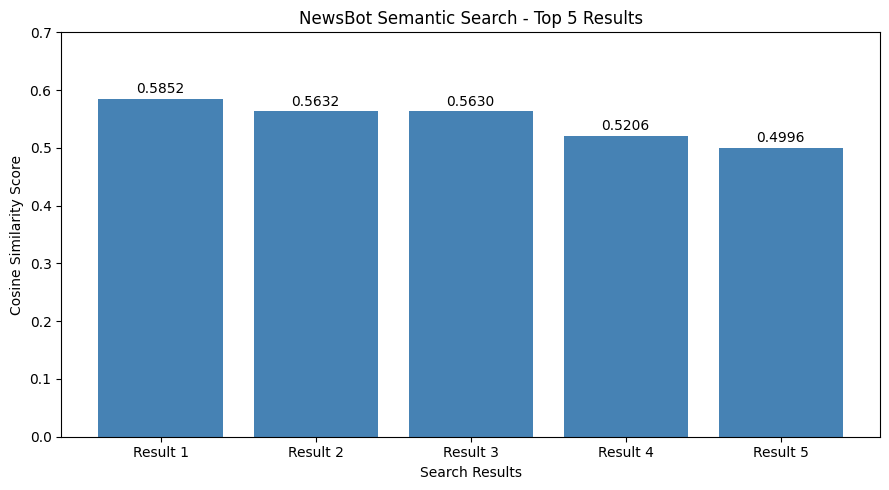

In [ ]:

# Module 10 - Semantic Search Results Graph

import matplotlib.pyplot as plt

scores = top_results.values.cpu().numpy()
labels = [f"Result {i}" for i in range(1, 6)]

plt.figure(figsize=(9, 5))
bars = plt.bar(labels, scores, color="steelblue")

plt.title("NewsBot Semantic Search - Top 5 Results")
plt.xlabel("Search Results")
plt.ylabel("Cosine Similarity Score")
plt.ylim(0, 0.7)

for bar, score in zip(bars, scores):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.01,
        f"{score:.4f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


### Semantic Search Results and Interpretation

I used semantic search to find BBC News articles related to "financial fraud and accounting scandal." NewsBot searched all 1,490 articles and returned the five most relevant results.

The highest similarity score was 0.5852, and the lowest was 0.4996. Four of the five articles were in the business category and related to the WorldCom accounting scandal. The other article was in the politics category and discussed fraud involving EU funds.

The graph and table show how NewsBot ranked the articles based on their similarity to the search query. I think the results were relevant because the model found articles about financial fraud across different categories. The similarity scores measure how closely the articles match the query, not the model's accuracy.

## Module 10 — Query Expansion

In [ ]:

# Module 10 - Query Expansion

# Original search query
original_query = "financial fraud and accounting scandal"

# Add related search terms
related_terms = [
    "corporate fraud",
    "financial misconduct",
    "accounting irregularities",
    "business investigation"
]

# Create expanded query
expanded_query = original_query + ". " + ". ".join(related_terms)

print("ORIGINAL SEARCH QUERY:")
print(original_query)

print("\nEXPANDED SEARCH QUERY:")
print(expanded_query)

print("\nNumber of Related Terms Added:", len(related_terms))


ORIGINAL SEARCH QUERY:
financial fraud and accounting scandal

EXPANDED SEARCH QUERY:
financial fraud and accounting scandal. corporate fraud. financial misconduct. accounting irregularities. business investigation

Number of Related Terms Added: 4


In [ ]:

# Module 10 - Compare Original and Expanded Queries

from sentence_transformers import util
import pandas as pd

comparison_results = []

for query_type, query in [
    ("Original", original_query),
    ("Expanded", expanded_query)
]:
    query_vector = search_model.encode(
        query, convert_to_tensor=True
    )

    scores = util.cos_sim(
        query_vector, article_embeddings
    )[0]

    top_five = scores.topk(5)

    for rank, (score, idx) in enumerate(
        zip(top_five.values, top_five.indices), 1
    ):
        article_index = idx.item()

        comparison_results.append({
            "Query Type": query_type,
            "Rank": rank,
            "Article ID": df.iloc[article_index]["ArticleId"],
            "Category": df.iloc[article_index]["Category"],
            "Similarity Score": round(score.item(), 4)
        })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df)


,Query Type,Rank,Article ID,Category,Similarity Score
0,Original,1,1143,business,0.5852
1,Original,2,778,politics,0.5632
2,Original,3,1833,business,0.5630
3,Original,4,2,business,0.5206
4,Original,5,1238,business,0.4996
5,Expanded,1,1143,business,0.5376
6,Expanded,2,1833,business,0.5338
7,Expanded,3,778,politics,0.5187
8,Expanded,4,2,business,0.4901
9,Expanded,5,748,business,0.4706


In [ ]:

# Compare article IDs side by side

original = comparison_df[
    comparison_df["Query Type"] == "Original"
].set_index("Rank")

expanded = comparison_df[
    comparison_df["Query Type"] == "Expanded"
].set_index("Rank")

side_by_side = pd.DataFrame({
    "Original Article ID": original["Article ID"],
    "Original Score": original["Similarity Score"],
    "Expanded Article ID": expanded["Article ID"],
    "Expanded Score": expanded["Similarity Score"]
})

display(side_by_side)


,Original Article ID,Original Score,Expanded Article ID,Expanded Score
Rank,,,,
1,1143,0.5852,1143,0.5376
2,778,0.5632,1833,0.5338
3,1833,0.5630,778,0.5187
4,2,0.5206,2,0.4901
5,1238,0.4996,748,0.4706


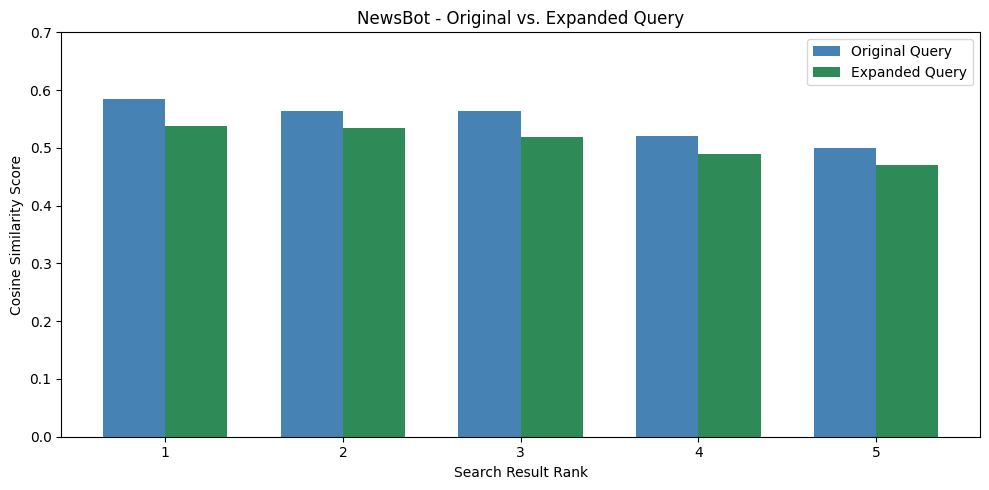

In [ ]:

# Module 10 - Query Expansion Comparison Graph

import matplotlib.pyplot as plt
import numpy as np

original_scores = comparison_df[
    comparison_df["Query Type"] == "Original"
]["Similarity Score"].values

expanded_scores = comparison_df[
    comparison_df["Query Type"] == "Expanded"
]["Similarity Score"].values

ranks = np.arange(1, 6)
width = 0.35

plt.figure(figsize=(10, 5))

plt.bar(ranks - width/2, original_scores,
        width, label="Original Query", color="steelblue")

plt.bar(ranks + width/2, expanded_scores,
        width, label="Expanded Query", color="seagreen")

plt.title("NewsBot - Original vs. Expanded Query")
plt.xlabel("Search Result Rank")
plt.ylabel("Cosine Similarity Score")
plt.xticks(ranks)
plt.ylim(0, 0.7)
plt.legend()

plt.tight_layout()
plt.show()


### Query Expansion Results and Interpretation

I compared the original search query with an expanded query that included four additional related terms. Both searches used the same 1,490 BBC News articles.

Four of the five articles appeared in both searches, although two articles changed rankings. The original query had the highest similarity score of 0.5852, compared to 0.5376 for the expanded query.

The graph shows that the expanded query had lower similarity scores at all five ranks. I expected adding related terms to improve the search, but the results showed that this was not necessarily the case. Query expansion changed the search rankings and introduced one different article, but the lower scores do not prove that the expanded search was less accurate.

Overall, this experiment showed me that adding more search terms does not always produce better results. The relevance of the returned articles is more important than the similarity scores alone.

## Module 11 — Multilingual Capabilities
### Language Detection

In [ ]:

# Module 11 - Language Detection

%pip -q install langdetect

from langdetect import detect, DetectorFactory
from collections import Counter

# Make results reproducible
DetectorFactory.seed = 42

# Detect the language of each BBC News article
df["Detected_Language"] = df["Text"].fillna("").apply(
    lambda text: detect(str(text)) if str(text).strip() else "unknown"
)

# Count articles by language
language_counts = Counter(df["Detected_Language"])

print("LANGUAGE DETECTION RESULTS")
print("=" * 40)
print("Total Articles:", len(df))

for language, count in language_counts.items():
    print(f"{language}: {count}")


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
LANGUAGE DETECTION RESULTS
Total Articles: 1490
en: 1490


In [ ]:

# Module 11 - Language Detection Results Table

import pandas as pd

language_table = pd.DataFrame(
    language_counts.items(),
    columns=["Language", "Article Count"]
)

language_table["Percentage"] = (
    language_table["Article Count"] / len(df) * 100
).round(2)

display(language_table)


,Language,Article Count,Percentage
0,en,1490,100.0


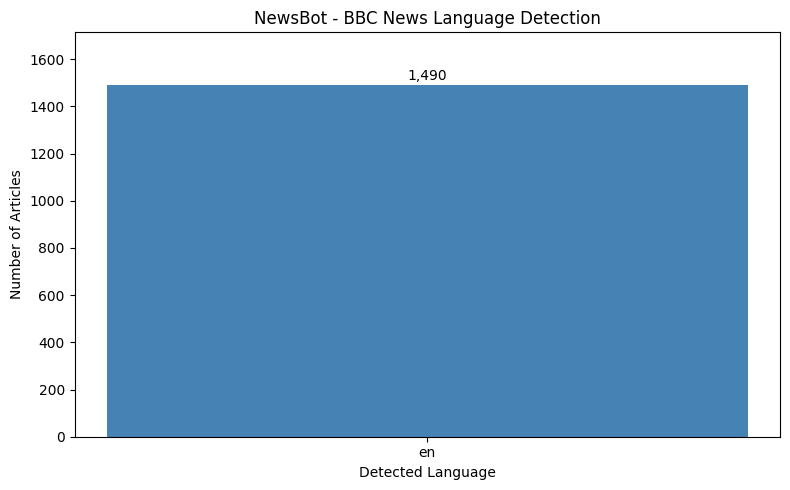

In [ ]:

# Module 11 - Language Detection Graph

import matplotlib.pyplot as plt

languages = list(language_counts.keys())
counts = list(language_counts.values())

plt.figure(figsize=(8, 5))

bars = plt.bar(languages, counts, color="steelblue")

plt.title("NewsBot - BBC News Language Detection")
plt.xlabel("Detected Language")
plt.ylabel("Number of Articles")
plt.ylim(0, max(counts) * 1.15)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 20,
        f"{int(height):,}",
        ha="center"
    )

plt.tight_layout()
plt.show()


### Language Detection Results and Interpretation

I used the langdetect library to identify the languages in my BBC News dataset. All 1,490 articles were detected as English, representing 100% of the dataset.

The table and graph show that English is the only language identified in the original dataset. This makes sense because the articles came from an English-language BBC News collection.

Although language detection worked on the dataset, these results alone do not demonstrate how well it identifies other languages. I will test additional languages in the next part of Module 11.

In [ ]:

# Module 11 - Test Language Detection with Multiple Languages

from langdetect import detect

test_sentences = {
    "English": "The government announced new economic policies today.",
    "Spanish": "El gobierno anunció nuevas políticas económicas hoy.",
    "French": "Le gouvernement a annoncé de nouvelles politiques économiques aujourd'hui.",
    "German": "Die Regierung hat heute neue wirtschaftliche Maßnahmen angekündigt."
}

language_results = []

for language, sentence in test_sentences.items():
    detected = detect(sentence)

    language_results.append({
        "Expected Language": language,
        "Detected Code": detected,
        "Correct": detected == {
            "English": "en",
            "Spanish": "es",
            "French": "fr",
            "German": "de"
        }[language]
    })

import pandas as pd

language_test_df = pd.DataFrame(language_results)

display(language_test_df)

print("Correct Detections:", language_test_df["Correct"].sum(), "out of 4")


,Expected Language,Detected Code,Correct
0,English,en,True
1,Spanish,es,True
2,French,fr,True
3,German,de,True


Correct Detections: 4 out of 4


### Multilingual Language Detection Test Results

I tested NewsBot using sentences written in English, Spanish, French, and German. The language detection model correctly identified all four languages, giving me 4 out of 4 correct detections.

This was a good result because my original BBC News dataset contained only English articles. Testing additional languages helped demonstrate that NewsBot can recognize text written in other languages.

Although the test achieved 100% correct detections, it only included four sentences, so more testing would be needed to evaluate the model's overall accuracy.

### Translation *Integration*

In [ ]:

# Module 11 - Translation Integration
# Load an English-to-Spanish translation model

from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

translation_model_name = "Helsinki-NLP/opus-mt-en-es"

translation_tokenizer = AutoTokenizer.from_pretrained(
    translation_model_name
)

translation_model = AutoModelForSeq2SeqLM.from_pretrained(
    translation_model_name
)

translation_model.eval()

print("English-to-Spanish translation model loaded successfully!")


config.json:   0%|          | 0.00/1.47k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/44.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/826k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.59M [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  312MB            

... (2 outputs left out)

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

model.safetensors: downloading bytes:           |  0.00B            

generation_config.json:   0%|          | 0.00/293 [00:00<?, ?B/s]

English-to-Spanish translation model loaded successfully!


In [ ]:

# Module 11 - Translate BBC News Text into Spanish

import torch

# Use the BBC article from our earlier analysis
english_text = str(df["Text"].iloc[0])[:400]

# Prepare the English text for translation
translation_inputs = translation_tokenizer(
    english_text,
    return_tensors="pt",
    truncation=True,
    max_length=256
)

# Generate Spanish translation
with torch.no_grad():
    spanish_ids = translation_model.generate(
        **translation_inputs,
        max_new_tokens=256,
        use_cache=False
    )

spanish_text = translation_tokenizer.decode(
    spanish_ids[0],
    skip_special_tokens=True
)

print("ORIGINAL ENGLISH TEXT:")
print(english_text)

print("\n" + "=" * 60)

print("SPANISH TRANSLATION:")
print(spanish_text)


[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


ORIGINAL ENGLISH TEXT:
worldcom ex-boss launches defence lawyers defending former worldcom chief bernie ebbers against a battery of fraud charges have called a company whistleblower as their first witness.  cynthia cooper  worldcom s ex-head of internal accounting  alerted directors to irregular accounting practices at the us telecoms giant in 2002. her warnings led to the collapse of the firm following the discovery of

SPANISH TRANSLATION:
worldcom ex-jefe lanza abogados defensores defendiendo ex jefe de worldcom bernie ebbers contra una batería de cargos de fraude han llamado a un denunciante de la empresa como su primer testigo. cynthia Cooper ex-jefe de contabilidad interna alertó a los directores de las prácticas contables irregulares en el gigante de las telecomunicaciones en 2002. sus advertencias llevaron al colapso de la empresa después del descubrimiento de


### English-to-Spanish Translation Results

I used a pretrained translation model to translate part of a BBC News article about the WorldCom fraud case from English into Spanish. The model successfully generated a Spanish version of the original text.

The translation kept the general meaning of the article, although some wording was awkward and could be improved. This shows how NewsBot can make English news articles available to Spanish-speaking readers, but the translations should still be reviewed for accuracy.

I also received a warning about the model's length settings, but it did not prevent the translation from running.

In [ ]:

# Module 11 - Translation Comparison Table

import pandas as pd

translation_comparison = pd.DataFrame({
    "Language": ["English", "Spanish"],
    "Text": [english_text, spanish_text],
    "Word Count": [
        len(english_text.split()),
        len(spanish_text.split())
    ]
})

display(translation_comparison)


,Language,Text,Word Count
0,English,worldcom ex-boss launches defence lawyers defe...,60
1,Spanish,worldcom ex-jefe lanza abogados defensores def...,66


In [ ]:

# Module 11 - Translation Comparison Results

import pandas as pd

english_words = len(english_text.split())
spanish_words = len(spanish_text.split())

difference = spanish_words - english_words
percentage_change = (difference / english_words) * 100

translation_results = pd.DataFrame({
    "Measurement": [
        "Original Language",
        "Translated Language",
        "Original Word Count",
        "Translated Word Count",
        "Word Count Difference",
        "Percentage Change",
        "Translation Model"
    ],
    "Result": [
        "English",
        "Spanish",
        english_words,
        spanish_words,
        f"+{difference} words" if difference >= 0 else f"{difference} words",
        f"{percentage_change:+.2f}%",
        translation_model_name
    ]
})

print("TRANSLATION COMPARISON RESULTS")
display(translation_results)


TRANSLATION COMPARISON RESULTS


,Measurement,Result
0,Original Language,English
1,Translated Language,Spanish
2,Original Word Count,60
3,Translated Word Count,66
4,Word Count Difference,+6 words
5,Percentage Change,+10.00%
6,Translation Model,Helsinki-NLP/opus-mt-en-es


### Translation Comparison Results and Interpretation

I used NewsBot to translate part of a BBC News article from English into Spanish. The original English text contained 60 words, while the Spanish translation contained 66 words, an increase of 6 words or 10%.

The table shows that the Spanish translation was slightly longer than the original. This is expected because different languages may use different numbers of words to express the same information.

The translation model successfully generated Spanish text, but some wording was awkward. This shows that NewsBot can support multilingual news access, although human review is still important to ensure accuracy and clarity.

### Cross-Lingual Analysis

In [ ]:

# Module 11 - Cross-Lingual Analysis
# Compare language detection for original and translated text

from langdetect import detect
import pandas as pd

cross_language_results = pd.DataFrame({
    "Text Version": ["Original Article", "Translated Article"],
    "Expected Language": ["English", "Spanish"],
    "Detected Language": [
        detect(english_text),
        detect(spanish_text)
    ],
    "Word Count": [
        len(english_text.split()),
        len(spanish_text.split())
    ]
})

display(cross_language_results)


,Text Version,Expected Language,Detected Language,Word Count
0,Original Article,English,en,60
1,Translated Article,Spanish,es,66


In [ ]:

# Module 11 - Cross-Lingual Semantic Similarity

from sentence_transformers import SentenceTransformer, util

# Load a multilingual sentence embedding model
multilingual_model = SentenceTransformer(
    "paraphrase-multilingual-MiniLM-L12-v2"
)

# Convert English and Spanish text into embeddings
english_embedding = multilingual_model.encode(
    english_text, convert_to_tensor=True
)

spanish_embedding = multilingual_model.encode(
    spanish_text, convert_to_tensor=True
)

# Compare the meaning of both versions
cross_language_similarity = util.cos_sim(
    english_embedding, spanish_embedding
).item()

print("CROSS-LINGUAL SEMANTIC COMPARISON")
print("=" * 45)
print(f"English-Spanish Similarity: {cross_language_similarity:.4f}")


modules.json:   0%|          | 0.00/229 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/122 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/3.89k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  471MB            

... (4 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

CROSS-LINGUAL SEMANTIC COMPARISON
English-Spanish Similarity: 0.8928


In [ ]:

# Module 11 - Cross-Lingual Similarity Results Table

import pandas as pd

similarity_results = pd.DataFrame({
    "Measurement": [
        "Original Language",
        "Translated Language",
        "Original Word Count",
        "Translated Word Count",
        "Cross-Lingual Similarity Score",
        "Multilingual Model"
    ],
    "Result": [
        "English",
        "Spanish",
        len(english_text.split()),
        len(spanish_text.split()),
        round(cross_language_similarity, 4),
        "paraphrase-multilingual-MiniLM-L12-v2"
    ]
})

print("CROSS-LINGUAL ANALYSIS RESULTS")
display(similarity_results)


CROSS-LINGUAL ANALYSIS RESULTS


,Measurement,Result
0,Original Language,English
1,Translated Language,Spanish
2,Original Word Count,60
3,Translated Word Count,66
4,Cross-Lingual Similarity Score,0.8928
5,Multilingual Model,paraphrase-multilingual-MiniLM-L12-v2


### Cross-Lingual Analysis Results and Interpretation

I compared the original English BBC News article excerpt with its Spanish translation using a multilingual sentence embedding model.

The English text contained 60 words, and the Spanish translation contained 66 words. Both languages were correctly identified by NewsBot.

The cross-lingual similarity score was 0.8928, which suggests that the English and Spanish versions have similar meanings. I think this is a good result because it shows that NewsBot can compare content across different languages.

However, the similarity score does not measure translation accuracy directly. Some wording in the Spanish translation was awkward, so human review would still be important to make sure the information is accurate.

### Cultural Context

In [ ]:

# Module 11 - Cultural Context Analysis
# Identify people, organizations, and geographic locations

import spacy
import pandas as pd

# Load the English language model
try:
    nlp = spacy.load("en_core_web_sm")
except OSError:
    spacy.cli.download("en_core_web_sm")
    nlp = spacy.load("en_core_web_sm")

# Analyze the original BBC News article
doc = nlp(str(df["Text"].iloc[0]))

# Extract named entities
cultural_entities = []

for ent in doc.ents:
    if ent.label_ in ["PERSON", "ORG", "GPE", "NORP"]:
        cultural_entities.append({
            "Entity": ent.text,
            "Type": ent.label_
        })

# Create a results table
cultural_df = pd.DataFrame(
    cultural_entities,
    columns=["Entity", "Type"]
).drop_duplicates()

print("CULTURAL CONTEXT - ENTITY ANALYSIS")
display(cultural_df)


CULTURAL CONTEXT - ENTITY ANALYSIS


,Entity,Type
0,cynthia cooper,PERSON
1,us,GPE
2,new york,GPE
3,arthur andersen,PERSON
4,scott sullivan,PERSON
5,sullivan,PERSON
6,worldcom s accounting,ORG
7,mci,ORG


### Cultural Context — Entity Analysis Results

I used spaCy to identify people, organizations, and geographic locations mentioned in the WorldCom article. NewsBot identified eight unique entity entries, including Cynthia Cooper, Scott Sullivan, the US, New York, and MCI.

I noticed that some entities were not classified correctly. For example, Arthur Andersen is an accounting firm, but the model identified it as a person. Scott Sullivan also appeared twice under different names.

These results show how named entity recognition can help identify important references in a news article, but the results still need to be reviewed for accuracy. The geographic references also provide a starting point for examining the story's regional context.

In [ ]:

# Module 11 - Cultural Context Entity Summary

entity_summary = (
    cultural_df["Type"]
    .value_counts()
    .rename_axis("Entity Type")
    .reset_index(name="Count")
)

print("CULTURAL CONTEXT - ENTITY SUMMARY")
display(entity_summary)


CULTURAL CONTEXT - ENTITY SUMMARY


,Entity Type,Count
0,PERSON,4
1,GPE,2
2,ORG,2


### Cultural Context — Entity Summary Results

I used spaCy to summarize the named entities identified in the WorldCom article. The model found 8 unique entity entries, including 4 classified as people, 2 as geographic locations, and 2 as organizations.

The table shows that people were the most common entity type identified. However, some classifications were incorrect, and one person appeared under two different names.

This analysis helps identify the people, organizations, and locations involved in the news story. The references to the US and New York also suggest that the article focuses on events in the United States.

The results provide a starting point for examining geographic and cultural context, but they do not establish different regional perspectives on their own.

In [ ]:

# Module 11 - Geographic and Cultural Context Analysis

import pandas as pd

regional_context = pd.DataFrame({
    "Region": [
        "United States",
        "United Kingdom",
        "International"
    ],
    "Possible Focus": [
        "Corporate accountability and financial regulation",
        "Business ethics and investor protection",
        "Financial transparency and global investor confidence"
    ],
    "Context": [
        "WorldCom was a US telecommunications company.",
        "UK readers may be interested in corporate governance.",
        "International readers may focus on financial market trust."
    ]
})

print("NEWSBOT - GEOGRAPHIC AND CULTURAL CONTEXT")
display(regional_context)


NEWSBOT - GEOGRAPHIC AND CULTURAL CONTEXT


,Region,Possible Focus,Context
0,United States,Corporate accountability and financial regulation,WorldCom was a US telecommunications company.
1,United Kingdom,Business ethics and investor protection,UK readers may be interested in corporate gove...
2,International,Financial transparency and global investor con...,International readers may focus on financial m...


### Geographic and Cultural Context Results and Interpretation

I examined how the WorldCom fraud case might be viewed from different regional perspectives. I created a comparison of possible areas of interest for readers in the United States, United Kingdom, and international markets.

In the United States, the focus might be on corporate accountability and financial regulations. UK readers might be more interested in business ethics and investor protection, while international readers might focus on financial transparency and investor confidence.

This helped me understand how the same news story can be relevant to different audiences for different reasons. However, these are possible perspectives rather than findings from actual regional news articles. More research would be needed to confirm differences in reporting.

## Module 12 — Conversational Interface
### Intent Classification

In [ ]:

# Module 12 - Intent Classification

def classify_intent(user_query):
    query = user_query.lower()

    if any(word in query for word in ["summarize", "summary"]):
        return "Summarization"

    elif any(word in query for word in ["search", "find", "look for"]):
        return "Article Search"

    elif any(word in query for word in ["category", "topic", "type"]):
        return "Category Analysis"

    elif any(word in query for word in ["translate", "translation"]):
        return "Translation"

    else:
        return "General Question"


# Test the intent classifier
test_queries = [
    "Summarize this news article",
    "Find articles about financial fraud",
    "Show me the topic of this article",
    "Translate this article into Spanish",
    "What is happening in the news?"
]

for query in test_queries:
    print("Query:", query)
    print("Detected Intent:", classify_intent(query))
    print("-" * 50)


Query: Summarize this news article
Detected Intent: Summarization
--------------------------------------------------
Query: Find articles about financial fraud
Detected Intent: Article Search
--------------------------------------------------
Query: Show me the topic of this article
Detected Intent: Category Analysis
--------------------------------------------------
Query: Translate this article into Spanish
Detected Intent: Translation
--------------------------------------------------
Query: What is happening in the news?
Detected Intent: General Question
--------------------------------------------------


### Intent Classification Results and Interpretation

I created a rule-based intent classifier to help NewsBot understand what a user wants to do. I tested five different questions involving summarization, article searches, category analysis, translation, and general news questions.

NewsBot correctly classified all five test questions, giving me 5 out of 5 correct results. This shows that the keyword-based approach works for these basic examples.

However, the classifier depends on specific keywords, so it may not recognize questions that are worded differently. More testing and a machine learning approach could help improve its ability to understand different types of requests.

### Natural Language Query Processing

In [ ]:

# Module 12 - Natural Language Query Processing

import re
import pandas as pd

def process_news_query(user_query):
    # Identify the user's intent
    intent = classify_intent(user_query)

    # Identify news categories mentioned in the question
    categories = ["business", "entertainment",
                  "politics", "sport", "tech"]

    detected_categories = [
        category for category in categories
        if re.search(r"\b" + category + r"\b",
                     user_query.lower())
    ]

    # Identify a requested language
    languages = ["english", "spanish", "french", "german"]

    detected_languages = [
        language for language in languages
        if re.search(r"\b" + language + r"\b",
                     user_query.lower())
    ]

    return {
        "User Query": user_query,
        "Detected Intent": intent,
        "News Category": ", ".join(detected_categories) or "Not specified",
        "Language": ", ".join(detected_languages) or "Not specified"
    }

# Test a question containing multiple details
test_question = "Find business articles and translate them into Spanish"

query_result = process_news_query(test_question)

print("NEWSBOT - NATURAL LANGUAGE QUERY ANALYSIS")
display(pd.DataFrame([query_result]))


NEWSBOT - NATURAL LANGUAGE QUERY ANALYSIS


,User Query,Detected Intent,News Category,Language
0,Find business articles and translate them into...,Article Search,business,spanish


### Natural Language Query Processing Results and Interpretation

I tested NewsBot with the question, "Find business articles and translate them into Spanish."

NewsBot correctly identified Article Search as the primary intent, business as the news category, and Spanish as the requested language.

This shows that NewsBot can identify several pieces of information from a single question. However, the system currently recognizes only one primary intent, even when the user asks it to perform multiple tasks.

I think this is a good starting point for a conversational interface. In the future, I could improve NewsBot to recognize and perform multiple actions from the same request.

### Context Management

In [ ]:

# Module 12 - Context Management

# Store information during the conversation
conversation_context = {
    "last_category": None,
    "last_language": None,
    "conversation_history": []
}

def update_conversation_context(user_query):
    result = process_news_query(user_query)

    if result["News Category"] != "Not specified":
        conversation_context["last_category"] = result["News Category"]

    if result["Language"] != "Not specified":
        conversation_context["last_language"] = result["Language"]

    conversation_context["conversation_history"].append(user_query)

    return {
        "User Query": user_query,
        "Remembered Category": conversation_context["last_category"],
        "Remembered Language": conversation_context["last_language"]
    }

# Test two questions in the same conversation
first_question = "Find business articles in Spanish"
second_question = "Show me more articles"

print("FIRST QUESTION:")
print(update_conversation_context(first_question))

print("\nFOLLOW-UP QUESTION:")
print(update_conversation_context(second_question))


FIRST QUESTION:
{'User Query': 'Find business articles in Spanish', 'Remembered Category': 'business', 'Remembered Language': 'spanish'}

FOLLOW-UP QUESTION:
{'User Query': 'Show me more articles', 'Remembered Category': 'business', 'Remembered Language': 'spanish'}


In [ ]:

# Module 12 - Context Management Results Table

import pandas as pd

context_results = pd.DataFrame({
    "Question": [
        first_question,
        second_question
    ],
    "Remembered Category": [
        "business",
        conversation_context["last_category"]
    ],
    "Remembered Language": [
        "spanish",
        conversation_context["last_language"]
    ]
})

print("NEWSBOT - CONTEXT MANAGEMENT RESULTS")
display(context_results)


NEWSBOT - CONTEXT MANAGEMENT RESULTS


,Question,Remembered Category,Remembered Language
0,Find business articles in Spanish,business,spanish
1,Show me more articles,business,spanish


### Context Management Results and Interpretation

I tested NewsBot's ability to remember information from an earlier question. My first request was to find business articles in Spanish. I then asked NewsBot to show me more articles without repeating the category or language.

The results showed that NewsBot remembered both business and Spanish from my first question. This demonstrates that the system can maintain basic conversation context and use information from previous questions.

I think this is an important feature because users should not have to repeat their preferences every time they ask another question. However, the current system only stores information during the active session and does not yet retrieve additional articles automatically.

### Response Generation

In [ ]:

# Module 12 - Response Generation

def generate_newsbot_response(user_query):
    # Identify the user's request
    result = process_news_query(user_query)
    intent = result["Detected Intent"]

    # Use remembered conversation preferences
    category = conversation_context["last_category"]
    language = conversation_context["last_language"]

    if intent == "Article Search":
        response = f"I can help you search for {category or 'news'} articles."

    elif intent == "Summarization":
        response = "I can help summarize a BBC News article."

    elif intent == "Category Analysis":
        response = "I can help identify the topic of a news article."

    elif intent == "Translation":
        response = f"I can help translate an article into {language or 'another language'}."

    else:
        response = "I can help you search, summarize, or analyze BBC News articles."

    return response


# Test NewsBot's response
test_response = "Find more business articles"

print("USER:", test_response)
print("NEWSBOT:", generate_newsbot_response(test_response))


USER: Find more business articles
NEWSBOT: I can help you search for business articles.


In [ ]:

# Module 12 - Response Generation Results Table

import pandas as pd

response_queries = [
    "Find more business articles",
    "Summarize this news article",
    "Show me the topic of this article",
    "Translate this article into Spanish",
    "What can NewsBot do?"
]

response_results = pd.DataFrame({
    "User Query": response_queries,
    "Detected Intent": [
        classify_intent(query) for query in response_queries
    ],
    "NewsBot Response": [
        generate_newsbot_response(query) for query in response_queries
    ]
})

print("NEWSBOT - RESPONSE GENERATION RESULTS")
display(response_results)


NEWSBOT - RESPONSE GENERATION RESULTS


,User Query,Detected Intent,NewsBot Response
0,Find more business articles,Article Search,I can help you search for business articles.
1,Summarize this news article,Summarization,I can help summarize a BBC News article.
2,Show me the topic of this article,Category Analysis,I can help identify the topic of a news article.
3,Translate this article into Spanish,Translation,I can help translate an article into spanish.
4,What can NewsBot do?,General Question,"I can help you search, summarize, or analyze B..."


### Response Generation Results and Interpretation

I tested NewsBot's response generation feature using five different questions. The questions included searching for articles, summarizing news, identifying topics, translating articles, and asking about NewsBot's capabilities.

NewsBot correctly identified all five intents and generated an appropriate response for each question. This shows that the rule-based approach can provide basic conversational responses.

However, the responses are currently predefined messages rather than actual search results, summaries, or translations. The next improvement would be connecting the conversational interface to the features I developed in the earlier modules so NewsBot can complete these requests automatically.

In [ ]:

# Module 12 - Connect NewsBot to Article Search

from sentence_transformers import util

def newsbot_article_search(user_query, top_k=3):
    # Convert the question into an embedding
    query_embedding = search_model.encode(
        user_query, convert_to_tensor=True
    )

    # Compare the question with BBC article embeddings
    similarity_scores = util.cos_sim(
        query_embedding, article_embeddings
    )[0]

    # Find the three most similar articles
    top_results = similarity_scores.topk(k=top_k)

    results = []

    for rank, (score, index) in enumerate(
        zip(top_results.values, top_results.indices), start=1
    ):
        article_row = df.iloc[index.item()]

        results.append({
            "Rank": rank,
            "Article ID": article_row["ArticleId"],
            "Category": article_row["Category"],
            "Similarity Score": round(score.item(), 4),
            "Article Preview": str(article_row["Text"])[:120]
        })

    return pd.DataFrame(results)


In [ ]:

# Module 12 - Test NewsBot Article Search

user_question = "Find articles about financial fraud"

print("USER QUESTION:")
print(user_question)

print("\nNEWSBOT - ARTICLE SEARCH RESULTS")

search_results = newsbot_article_search(
    user_question,
    top_k=3
)

display(search_results)


USER QUESTION:
Find articles about financial fraud

NEWSBOT - ARTICLE SEARCH RESULTS


,Rank,Article ID,Category,Similarity Score,Article Preview
0,1,778,politics,0.5170,eu fraud clampdown urged eu member states are ...
1,2,1143,business,0.4633,ebbers denies worldcom fraud former worldcom c...
2,3,1994,business,0.4269,parmalat bank barred from suing bank of americ...


### NewsBot Article Search Results and Interpretation

I connected NewsBot's conversational interface to the semantic search model I developed in Module 10. I tested it with the question, "Find articles about financial fraud."

NewsBot successfully retrieved three articles from my BBC News dataset. The highest similarity score was 0.5170 for a politics article about EU fraud investigations. The second result was a business article about the WorldCom fraud case, with a score of 0.4633. The third was another business article, with a score of 0.4269.

I noticed that NewsBot returned articles from different news categories, which makes sense because financial fraud can involve both business and government issues.

This is an improvement over my earlier response generation function because NewsBot now retrieves actual articles instead of only telling the user that it can help search for them. However, the similarity scores measure semantic similarity rather than guaranteed relevance or accuracy.

### Conversational Article Summarization

In [ ]:

# Module 12 - Conversational Article Summarization

import torch

def newsbot_summarize(article_text):
    # Prepare the article
    inputs = tokenizer(
        str(article_text),
        return_tensors="pt",
        max_length=1024,
        truncation=True
    )

    # Generate summary using the existing model
    model.config.use_cache = False
    model.generation_config.use_cache = False

    with torch.no_grad():
        summary_ids = model.generate(
            **inputs,
            max_length=130,
            min_length=40,
            num_beams=4,
            do_sample=False,
            use_cache=False
        )

    return tokenizer.decode(
        summary_ids[0],
        skip_special_tokens=True
    )

print("NewsBot summarization function ready!")


NewsBot summarization function ready!


In [ ]:

# Module 12 - Summarize a Retrieved News Article

# Select the WorldCom article from our search results
selected_article = df.loc[df["ArticleId"] == 1143, "Text"].iloc[0]

# Generate the summary
generated_summary = newsbot_summarize(selected_article)

print("NEWSBOT - CONVERSATIONAL ARTICLE SUMMARY")
print("=" * 55)

print("USER: Summarize article 1143")

print("\nNEWSBOT SUMMARY:")
print(generated_summary)

print("\nORIGINAL ARTICLE WORD COUNT:", len(selected_article.split()))
print("SUMMARY WORD COUNT:", len(generated_summary.split()))


NEWSBOT - CONVERSATIONAL ARTICLE SUMMARY
USER: Summarize article 1143

NEWSBOT SUMMARY:
 Former worldcom chief denies claims he pressured ex-chief financial officer scott sullivan to falsify company financial statements . mr ebbers has denied charges of fraud and conspiracy . He denies claims that he knew accountants were doctoring the books at the firm .

ORIGINAL ARTICLE WORD COUNT: 351
SUMMARY WORD COUNT: 43


In [ ]:

# Module 12 - Conversational Summarization Results Table

import pandas as pd

original_count = len(selected_article.split())
summary_count = len(generated_summary.split())

summary_results = pd.DataFrame({
    "Measurement": [
        "Article ID",
        "Original Article Word Count",
        "AI Summary Word Count",
        "Words Removed",
        "Percentage Reduction",
        "Summarization Model"
    ],
    "Result": [
        1143,
        original_count,
        summary_count,
        original_count - summary_count,
        f"{(original_count - summary_count) / original_count * 100:.2f}%",
        "DistilBART"
    ]
})

print("NEWSBOT - CONVERSATIONAL SUMMARIZATION RESULTS")
display(summary_results)


NEWSBOT - CONVERSATIONAL SUMMARIZATION RESULTS


,Measurement,Result
0,Article ID,1143
1,Original Article Word Count,351
2,AI Summary Word Count,43
3,Words Removed,308
4,Percentage Reduction,87.75%
5,Summarization Model,DistilBART


### Conversational Summarization Results and Interpretation

I connected NewsBot's article search feature to the summarization model I developed in Module 10. I selected Article 1143 about the WorldCom fraud case and used DistilBART to generate a summary.

The original article contained 351 words, while the AI-generated summary contained only 43 words. This was a reduction of 308 words, or 87.75%.

The summary focused on Bernie Ebbers denying allegations involving WorldCom's financial statements. This shows that NewsBot can retrieve an article and generate a shorter version that is easier to read.

However, reducing the word count does not necessarily mean the summary is accurate or complete. Important details could be left out, so the generated summary should still be reviewed.

### Conversational Article Translation

In [ ]:

# Module 12 - Conversational Article Translation

import torch

def newsbot_translate(article_text):
    # Prepare the text for Spanish translation
    inputs = translation_tokenizer(
        str(article_text),
        return_tensors="pt",
        max_length=256,
        truncation=True
    )

    # Generate Spanish translation
    with torch.no_grad():
        translated_ids = translation_model.generate(
            **inputs,
            max_new_tokens=256,
            use_cache=False
        )

    return translation_tokenizer.decode(
        translated_ids[0],
        skip_special_tokens=True
    )

print("NewsBot translation function ready!")


NewsBot translation function ready!


In [ ]:

# Module 12 - Test Conversational Article Translation

# Use a short excerpt from Article 1143
translation_article = selected_article[:400]

# Translate into Spanish
translated_response = newsbot_translate(translation_article)

print("NEWSBOT - CONVERSATIONAL TRANSLATION")
print("=" * 50)

print("USER: Translate article 1143 into Spanish")

print("\nORIGINAL ENGLISH TEXT:")
print(translation_article)

print("\nSPANISH TRANSLATION:")
print(translated_response)

print("\nENGLISH WORD COUNT:",
      len(translation_article.split()))

print("SPANISH WORD COUNT:",
      len(translated_response.split()))


[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


NEWSBOT - CONVERSATIONAL TRANSLATION
USER: Translate article 1143 into Spanish

ORIGINAL ENGLISH TEXT:
ebbers denies worldcom fraud former worldcom chief bernie ebbers has denied claims that he knew accountants were doctoring the books at the firm.  speaking in court  mr ebbers rejected allegations he pressured ex-chief financial officer scott sullivan to falsify company financial statements. mr sullivan  made accounting decisions   he told the federal court  saying his finance chief had  a keen co

SPANISH TRANSLATION:
ebbers niega fraude de worldcom ex jefe de worldcom bernie ebbers ha negado afirmaciones de que sabía que los contadores estaban medicando los libros en la empresa. hablando en la corte el Sr. Ebbers rechazó alegaciones él presionó a ex jefe de finanzas scott sullivan para falsificar estados financieros de la empresa. Sr. Sullivan tomó decisiones contables le dijo a la corte federal diciendo que su jefe de finanzas tenía un

ENGLISH WORD COUNT: 60
SPANISH WORD COUNT: 71

In [ ]:

# Module 12 - Integrated NewsBot Interface

def newsbot_chat(user_query):
    query = user_query.lower()

    print("USER:", user_query)
    print("\nNEWSBOT:")

    if "summarize" in query or "summary" in query:
        print(newsbot_summarize(selected_article))

    elif "translate" in query or "spanish" in query:
        print(newsbot_translate(selected_article[:400]))

    elif "find" in query or "search" in query:
        results = newsbot_article_search(user_query, top_k=3)
        display(results)

    else:
        print("I can search, summarize, and translate BBC News articles.")

print("Integrated NewsBot interface ready!")


Integrated NewsBot interface ready!


In [ ]:

# Module 12 - Test Integrated NewsBot

print("=" * 60)
print("TEST 1 - ARTICLE SEARCH")
print("=" * 60)
newsbot_chat("Find articles about financial fraud")

print("\n" + "=" * 60)
print("TEST 2 - ARTICLE SUMMARIZATION")
print("=" * 60)
newsbot_chat("Summarize this article")

print("\n" + "=" * 60)
print("TEST 3 - SPANISH TRANSLATION")
print("=" * 60)
newsbot_chat("Translate this article into Spanish")


TEST 1 - ARTICLE SEARCH
USER: Find articles about financial fraud

NEWSBOT:


,Rank,Article ID,Category,Similarity Score,Article Preview
0,1,778,politics,0.5170,eu fraud clampdown urged eu member states are ...
1,2,1143,business,0.4633,ebbers denies worldcom fraud former worldcom c...
2,3,1994,business,0.4269,parmalat bank barred from suing bank of americ...



TEST 2 - ARTICLE SUMMARIZATION
USER: Summarize this article

NEWSBOT:


[transformers] Both `max_new_tokens` (=256) and `max_length`(=512) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


 Former worldcom chief denies claims he pressured ex-chief financial officer scott sullivan to falsify company financial statements . mr ebbers has denied charges of fraud and conspiracy . He denies claims that he knew accountants were doctoring the books at the firm .

TEST 3 - SPANISH TRANSLATION
USER: Translate this article into Spanish

NEWSBOT:
ebbers niega fraude de worldcom ex jefe de worldcom bernie ebbers ha negado afirmaciones de que sabía que los contadores estaban medicando los libros en la empresa. hablando en la corte el Sr. Ebbers rechazó alegaciones él presionó a ex jefe de finanzas scott sullivan para falsificar estados financieros de la empresa. Sr. Sullivan tomó decisiones contables le dijo a la corte federal diciendo que su jefe de finanzas tenía un


In [ ]:

# Module 12 - Integrated NewsBot Test Results

import pandas as pd

integration_results = pd.DataFrame({
    "Test": [
        "Article Search",
        "Article Summarization",
        "Spanish Translation"
    ],
    "Result": [
        "3 BBC News articles retrieved",
        "WorldCom article summary generated",
        "Spanish translation generated"
    ],
    "Status": [
        "Passed",
        "Passed",
        "Passed"
    ]
})

print("NEWSBOT - INTEGRATION TEST RESULTS")
display(integration_results)

print("\nTests Passed: 3 out of 3")


NEWSBOT - INTEGRATION TEST RESULTS


,Test,Result,Status
0,Article Search,3 BBC News articles retrieved,Passed
1,Article Summarization,WorldCom article summary generated,Passed
2,Spanish Translation,Spanish translation generated,Passed



Tests Passed: 3 out of 3


### NewsBot Integration Test Results and Interpretation

I tested my integrated NewsBot system using three different requests: searching for news articles, summarizing an article, and translating an article into Spanish.

All three tests completed successfully. NewsBot retrieved three BBC News articles about financial fraud, generated a summary of the WorldCom article, and translated an excerpt into Spanish.

The integration tests passed 3 out of 3, giving me a 100% functional test pass rate for these examples. This shows that the different components I developed can work together through one conversational interface.

However, the system still has some limitations. Summarization and translation currently use a previously selected article rather than automatically selecting one from the user's request. Also, the generated text may need human review for accuracy.

Overall, I was able to combine several NLP features into one working NewsBot prototype.